In [ ]:
import xscen as xs
import xarray as xr
import figanos.matplotlib as fg
fg.utils.set_mpl_style('ouranos')
import xclim as xc
import glob
import pandas as pd
import numpy as np
import matplotlib
from pathlib import Path
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
import cartopy.crs as ccrs
from matplotlib import gridspec
import copy
import sys
from matplotlib.patches import Rectangle
import os
import shapely
os.environ["QT_QPA_PLATFORM"] = "offscreen"  # prevent Qt kernel crash in Jupyter

import numpy as np
import itertools
import pandas as pd
from ete3 import Tree, TreeStyle, NodeStyle, TextFace, add_face_to_node
import xscen as xs
from IPython.display import Image, display
import geopandas as gpd
import matplotlib.patches as patches
import scipy
import matplotlib.colors as mcolors
color_dict = fg.utils.categorical_colors()


#pd.set_option('display.max_rows', None)

from xscen import CONFIG
xs.load_config(
    "../config/ARCHES/config_ARCHES.yml",
    "../config/ARCHES/paths_ARCHES.yml",
    reset=True,
)
cat_sim = xs.DataCatalog(CONFIG['extraction']['simulation']['search_data_catalogs']['data_catalogs'][0])

# CRCM5 mask
sfltf=cat_sim.search(source='CRCM5-SN', experiment='historical', variable='sftlf', driving_model='CanESM5').to_dataset(xarray_open_kwargs={'engine':'h5netcdf'})
mask = xs.regrid.create_mask(
                    sfltf,
                    **CONFIG["extraction"]["simulation"]["create_mask"],
                )
variables=['tasmax', 'tasmin','pr']
fe={ 'lakes':{'scale':'110m', 'edgecolor':'black', 'facecolor':'none'},'coastline':{'scale':'50m'}}

map_proj=ccrs.LambertConformal()
#map_proj=ccrs.RotatedPole(pole_longitude=87.59703130293302,pole_latitude=31.758312454493154,) # proj of casr

style_colors = matplotlib.rcParams["axes.prop_cycle"].by_key()["color"]
key_colors= {'CaSR':style_colors[0], 'raw':style_colors[1],'ESPO':style_colors[2],'Scaling':style_colors[3],}

    
months=['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN',
          'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']


if not Path(CONFIG['figures']).exists():
    Path(CONFIG['figures']).mkdir(parents=True, exist_ok=True)

#comes from availability
ids=['CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM4-8_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM4-8_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM4-8_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r8i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r4i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r3i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r4i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r8i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r3i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r3i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r4i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r8i1p1f2_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_AS-RCEC_TaiESM1_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_AS-RCEC_TaiESM1_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_AS-RCEC_TaiESM1_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CMCC_CMCC-ESM2_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CMCC_CMCC-ESM2_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CMCC_CMCC-ESM2_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r6i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-MM_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-MM_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-MM_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-MM_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NOAA-GFDL_GFDL-ESM4_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NOAA-GFDL_GFDL-ESM4_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_NOAA-GFDL_GFDL-ESM4_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r1i2p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r6i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp585_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp585_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp245_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp245_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r5i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1_ssp585_r1i1p1f2_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1_ssp370_r1i1p1f2_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1_ssp245_r1i1p1f2_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-ESM2-1_ssp245_r1i1p1f2_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-ESM2-1_ssp370_r1i1p1f2_global', 'CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-ESM2-1_ssp585_r1i1p1f2_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r1i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r1i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r5i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r3i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r1i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5-1_ssp585_r1i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5-1_ssp370_r1i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5-1_ssp245_r1i1p2f1_global', 'CMIP6_ScenarioMIP_BCC_BCC-CSM2-MR_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_BCC_BCC-CSM2-MR_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_BCC_BCC-CSM2-MR_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r6i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r6i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r9i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r11i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r6i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r11i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r9i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r6i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r9i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r4i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r11i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r1i1p1f1_global', 'CMIP6_CORDEX_CNRM-ESM2-1_r1i1p1f2_OURANOS_CRCM5-SN_ssp245_r1_NAM-12', 'CMIP6_CORDEX_CNRM-ESM2-1_r1i1p1f2_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp585_r1_NAM-12', 'CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp245_r1_NAM-12', 'CMIP6_CORDEX_NorESM2-MM_r1i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_NorESM2-MM_r1i1p1f1_OURANOS_CRCM5-SN_ssp245_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r5i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r4i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r1i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r3i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r2i1p1f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12', 'CMIP6_CORDEX_MPI-ESM1-2-LR_r1i1p1f1_OURANOS_CRCM5-SN_ssp245_r1_NAM-12']


/cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/MPI/gcc12/openmpi4/esmf/8.8.0/lib/python3.12/site-packages/esmpy/interface/loadESMF.py:94: VersionWarning: ESMF installation version 8.8.0, ESMPy version 8.8.0b0
  warnings.warn("ESMF installation version {}, ESMPy version {}".format(


In [ ]:
lgdfs = []
files = glob.glob(f"{CONFIG['data']}/region_shapefiles/*.shp")
for f in files:
    lgdfs.append(gpd.read_file(f))
gdfsa = pd.concat(lgdfs)
gdfsa

In [2]:
def _rmse(sim, ref):
    return np.sqrt(np.nanmean((sim - ref) ** 2, axis=-1))

def maps2(label1, label2, prop_ref, prop_sim, prop_scen1, prop_scen2, meas_sim_prop, meas_scen1_prop, meas_scen2_prop):
    "Load properties and measures and plot them."
    
    
    # #TODO: tmp until run with new xscen and fix xsdba
    # prop_ref.attrs['grid_mapping']='crs'
    prop_sim.attrs['grid_mapping']='rotated_pole'
    prop_scen1.attrs['grid_mapping']='rotated_pole'
    prop_scen2.attrs['grid_mapping']='rotated_pole'

    # meas_sim_prop.attrs['grid_mapping']='crs'
    meas_scen1_prop.attrs['grid_mapping']='rotated_pole'
    meas_scen2_prop.attrs['grid_mapping']='rotated_pole'

    


    prop_long_name=prop_sim.attrs['long_name'] 
    meas_long_name=meas_sim_prop.attrs['long_name'] 
    # change units
    if prop_ref.attrs['units']=='kg m-2 s-1':
        prop_ref = xc.core.units.convert_units_to(prop_ref, 'mm d-1', context='hydro')
        prop_sim = xc.core.units.convert_units_to(prop_sim, 'mm d-1', context='hydro')
        prop_scen1 = xc.core.units.convert_units_to(prop_scen1, 'mm d-1', context='hydro')
        prop_scen2 = xc.core.units.convert_units_to(prop_scen2, 'mm d-1', context='hydro')
        meas_sim_prop = xc.core.units.convert_units_to(meas_sim_prop, 'mm d-1', context='hydro')
        meas_scen1_prop = xc.core.units.convert_units_to(meas_scen1_prop, 'mm d-1', context='hydro')
        meas_scen2_prop = xc.core.units.convert_units_to(meas_scen2_prop, 'mm d-1', context='hydro')
        
    if prop_ref.attrs['units']=='K':
        prop_ref = xc.core.units.convert_units_to(prop_ref, 'degC')
        prop_sim = xc.core.units.convert_units_to(prop_sim, 'degC')
        prop_scen1 = xc.core.units.convert_units_to(prop_scen, 'degC')
        prop_scen2 = xc.core.units.convert_units_to(prop_scen, 'degC')
        
    #set colormap
    maxi_prop = max(prop_ref.max().values, prop_scen1.max().values, prop_scen2.max().values, prop_sim.max().values)
    mini_prop = min(prop_ref.min().values, prop_scen1.min().values, prop_scen2.min().values, prop_sim.min().values)
    maxi_meas = float(max(abs(meas_scen1_prop).where(~np.isinf(meas_scen1_prop)).max().values,
                          abs(meas_scen2_prop).where(~np.isinf(meas_scen2_prop)).max().values,
                          abs(meas_sim_prop).where(~np.isinf(meas_sim_prop)).max().values))

    #plot
    fig = plt.figure(figsize=(15, 10))
    map_proj = fg.utils.get_rotpole(prop_sim)
    gs = gridspec.GridSpec(3, 3)
    ax0= fig.add_subplot(gs[1,0],projection=map_proj)
    ax1= fig.add_subplot(gs[0,1],projection=fg.utils.get_rotpole(prop_sim))
    ax2= fig.add_subplot(gs[0,2],projection=map_proj)
    ax3= fig.add_subplot(gs[1,1],projection=fg.utils.get_rotpole(prop_scen1))
    ax4= fig.add_subplot(gs[1,2],projection=fg.utils.get_rotpole(meas_scen1_prop))
    ax5= fig.add_subplot(gs[2,1],projection=fg.utils.get_rotpole(prop_scen2))
    ax6= fig.add_subplot(gs[2,2],projection=fg.utils.get_rotpole(meas_scen2_prop))

    plot_kw_prop=dict(add_colorbar=False, vmin=mini_prop,vmax=maxi_prop)
    plot_kw_meas=dict(add_colorbar=False, vmin=-maxi_meas,vmax=maxi_meas)
    features={ 'lakes':{'scale':'110m', 'edgecolor':'black', 'facecolor':'none'},'coastline':{'scale':'50m'}}
    #plot
    # deep copy until bug is fix TODO
    #TODO: choose cmap by end until figanos >5.0.0 is out and can use divergent
    #var_group=str(fg.utils.get_var_group(f"{sys.executable[:-10]}/lib/python3.13/site-packages/figanos/data/ipcc_colors/variable_groups.json",
    var_group=str(fg.utils.get_var_group(unique_str=f"{sys.executable[:-10]}/lib/python3.11/site-packages/figanos/data/ipcc_colors/variable_groups.json",                            
        da=meas_sim_prop))
    cmap=f"{var_group}_div"
    
    fg.gridmap(prop_ref, ax=ax0, plot_kw=copy.deepcopy(plot_kw_prop), features=copy.deepcopy(features))
    fg.gridmap(prop_sim, ax=ax1, plot_kw=copy.deepcopy(plot_kw_prop), features=copy.deepcopy(features))
    fg.gridmap(prop_scen1, ax=ax3, plot_kw=copy.deepcopy(plot_kw_prop), features=copy.deepcopy(features))
    fg.gridmap(prop_scen2, ax=ax5, plot_kw=copy.deepcopy(plot_kw_prop), features=copy.deepcopy(features))

    fg.gridmap(meas_sim_prop, ax=ax2, plot_kw=copy.deepcopy(plot_kw_meas),cmap=cmap, features=copy.deepcopy(features))
    fg.gridmap(meas_scen1_prop, ax=ax4, plot_kw=copy.deepcopy(plot_kw_meas),cmap=cmap, features=copy.deepcopy(features))
    fg.gridmap(meas_scen2_prop, ax=ax6, plot_kw=copy.deepcopy(plot_kw_meas),cmap=cmap, features=copy.deepcopy(features))

    #prop colorbar
    fig.subplots_adjust(bottom=0.1)
    cbar_ax = fig.add_axes([0.15, -0.1, 0.45, 0.03])
    cb1=fig.colorbar(ax0.get_children()[0], cax=cbar_ax,orientation='horizontal')
    cb1.set_label(label=f"{prop_long_name} ({prop_sim.attrs['units']})",size=13)
    cb1.ax.tick_params(axis='x', direction='out')
    cb1.outline.set_visible(False)
    
    #meas colorbar
    cbar_ax = fig.add_axes([0.68, -0.1, 0.25, 0.03])
    cb2=fig.colorbar(ax2.get_children()[0], cax=cbar_ax,orientation='horizontal')
    cb2.set_label(label=f"{meas_long_name} ({meas_sim_prop.attrs['units']})",size=13)
    
    cb2.ax.tick_params(axis='x', direction='out')
    cb2.outline.set_visible(False)
    
    
    #rmse
    rmse_sim = xr.apply_ufunc(
        _rmse,
        prop_sim.stack(loc=['rlat','rlon']).chunk(dict(loc=-1)),
        prop_ref.stack(loc=['rlat','rlon']).chunk(dict(loc=-1)),
        input_core_dims=[["loc"], ["loc"]],
        dask="parallelized",
    ).values
    
    
    rmse_scen1 = xr.apply_ufunc(
        _rmse,
        prop_scen1.stack(loc=['rlat','rlon']).chunk(dict(loc=-1)),
        prop_ref.stack(loc=['rlat','rlon']).chunk(dict(loc=-1)),
        input_core_dims=[["loc"], ["loc"]],
        dask="parallelized",
    ).values

    rmse_scen2 = xr.apply_ufunc(
        _rmse,
        prop_scen2.stack(loc=['rlat','rlon']).chunk(dict(loc=-1)),
        prop_ref.stack(loc=['rlat','rlon']).chunk(dict(loc=-1)),
        input_core_dims=[["loc"], ["loc"]],
        dask="parallelized",
    ).values
    
    fs=15
    ax0.set_title(r'a) reference', fontsize=fs)
    ax1.set_title(r'b) original', fontsize=fs)
    prop_sim.attrs['units']=prop_sim.attrs['units'].replace('mm d-1', 'mm/d')
    prop_scen1.attrs['units']=prop_scen1.attrs['units'].replace('mm d-1', 'mm/d')
    ax2.set_title(f"c) original \n RMSE={rmse_sim:.2f} {prop_sim.attrs['units']}",
                  fontsize=fs)
    ax3.set_title(f'd) {label1}', fontsize=fs)
    ax4.set_title(f"e) {label1} \n RMSE={rmse_scen1:.2f} {prop_scen1.attrs['units']}",
                  fontsize=fs)
    ax5.set_title(f'f) {label2}', fontsize=fs)
    ax6.set_title(f"g) {label2} \n RMSE={rmse_scen2:.2f} {prop_scen1.attrs['units']}",
                  fontsize=fs)
    fig.tight_layout()
    return fig,[ax0,ax1,ax2,ax3,ax4, ax5,ax6], [cb1,cb2]


# Availability

2026-10-16 10:52:38 INFO     xscen.extract   Catalog opened: < catalog with 1331 dataset(s) from 74432 asset(s)> from 1 files.


INFO:xscen.extract:Catalog opened: < catalog with 1331 dataset(s) from 74432 asset(s)> from 1 files.


2026-10-16 10:52:38 INFO     xscen.extract   Dispatching historical dataset to future experiments.


INFO:xscen.extract:Dispatching historical dataset to future experiments.


2026-10-16 10:52:41 INFO     xscen.extract   Removing 3051 assets based on exclusion dict 'id': ['CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r2i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r2i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r2i1p2f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r7i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r10i1p1f1_global'].


INFO:xscen.extract:Removing 3051 assets based on exclusion dict 'id': ['CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r2i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r2i1p2f1_global', 'CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r2i1p2f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r2i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r7i1p1f1_global', 'CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r10i1p1f1_global'].


2026-10-16 10:52:41 INFO     xscen.extract   Removing 4292 assets based on exclusion dict 'source': ['GFDL-CM4', 'EC-Earth3-CC', 'KIOST-ESM', 'NESM3', 'CMCC-CM2-SR5'].


INFO:xscen.extract:Removing 4292 assets based on exclusion dict 'source': ['GFDL-CM4', 'EC-Earth3-CC', 'KIOST-ESM', 'NESM3', 'CMCC-CM2-SR5'].
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xclim/core/indicator.py:296: UserWarning: Class conversions.WIND_SPEED_FROM_VECTOR already exists and will be overwritten.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xclim/core/indicator.py:296: UserWarning: Class conversions.WIND_VECTOR_FROM_SPEED already exists and will be overwritten.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xclim/core/indicator.py:296: UserWarning: Class conversions.TAS_MIDPOINT already exists and will be overwritten.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xclim/core/indicator.py:296: UserWarning: Class conversions.RELATIVE_HUMIDITY_FROM_DEWPOINT already exists and will be overwritten.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/s

2026-10-16 10:52:41 INFO     xscen.extract   67431 assets matched the criteria : {'processing_level': 'raw', 'mip_era': 'CMIP6', 'experiment': ['ssp245', 'ssp370', 'ssp585']}.


INFO:xscen.extract:67431 assets matched the criteria : {'processing_level': 'raw', 'mip_era': 'CMIP6', 'experiment': ['ssp245', 'ssp370', 'ssp585']}.


2026-10-16 10:52:41 INFO     xscen.extract   Iterating over 293 potential datasets.


INFO:xscen.extract:Iterating over 293 potential datasets.


2026-10-16 10:52:41 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:41 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:41 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:41 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp245_r1i1p1f1_global.


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp245_r1i1p1f1_global.


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:42 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NASA-GISS_GISS-E2-1-H_ssp370_r1i1p1f2_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NASA-GISS_GISS-E2-1-H_ssp370_r1i1p1f2_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NASA-GISS_GISS-E2-1-G_ssp585_r1i1p1f2_global doesn't have all needed variables (missing at least pr).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NASA-GISS_GISS-E2-1-G_ssp585_r1i1p1f2_global doesn't have all needed variables (missing at least pr).


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NASA-GISS_GISS-E2-1-G_ssp370_r1i1p1f2_global doesn't have all needed variables (missing at least pr).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NASA-GISS_GISS-E2-1-G_ssp370_r1i1p1f2_global doesn't have all needed variables (missing at least pr).


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NASA-GISS_GISS-E2-1-G_ssp245_r1i1p1f2_global doesn't have all needed variables (missing at least pr).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NASA-GISS_GISS-E2-1-G_ssp245_r1i1p1f2_global doesn't have all needed variables (missing at least pr).


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r8i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r4i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:43 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r2i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.


2026-10-16 10:52:43 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r3i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r4i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r8i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r3i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r2i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:44 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r2i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r3i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r4i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r8i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp126_r1i1p1f2_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:45 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:45 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp585_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:46 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:47 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NCAR_CESM2-WACCM_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NCAR_CESM2-WACCM_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NCAR_CESM2-WACCM_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NCAR_CESM2-WACCM_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NCAR_CESM2-WACCM_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NCAR_CESM2-WACCM_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NCAR_CESM2_ssp370_r4i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NCAR_CESM2_ssp370_r4i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp126_r1i1p1f1_global.


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:48 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp245_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp126_r1i1p1f1_global.


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp245_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp245_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp245_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp245_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp585_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp585_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp585_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp126_r1i1p1f1_global.


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_FGOALS-f3-L_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_FGOALS-f3-L_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_FGOALS-f3-L_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_FGOALS-f3-L_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_CAS-ESM2-0_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_CAS-ESM2-0_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_CAS-ESM2-0_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_CAS-ESM2-0_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:49 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r4i1p1f1_global doesn't have all needed variables (missing at least pr).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r4i1p1f1_global doesn't have all needed variables (missing at least pr).


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r5i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r5i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r6i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r6i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r10i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp585_r10i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r6i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:50 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp245_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r11i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r11i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:51 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_NCC_NorESM2-MM_ssp245_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_NCC_NorESM2-MM_ssp126_r1i1p1f1_global.


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp245_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp126_r1i1p1f1_global.


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp245_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp370_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp370_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp370_r3i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NCC_NorESM2-LM_ssp370_r3i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:52 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r1i2p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:53 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:53 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp585_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:54 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp245_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_AWI_AWI-CM-1-1-MR_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least pr).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_AWI_AWI-CM-1-1-MR_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least pr).


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_AWI_AWI-CM-1-1-MR_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least pr).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_AWI_AWI-CM-1-1-MR_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least pr).


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_AWI_AWI-CM-1-1-MR_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least pr).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_AWI_AWI-CM-1-1-MR_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least pr).


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM5A2-INCA_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM5A2-INCA_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:55 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r6i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:55 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp585_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:56 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp245_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:57 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp585_r2i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp126_r1i1p1f2_global.


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp245_r2i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp126_r1i1p1f2_global.


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp126_r1i1p1f2_global.


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:58 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:58 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:52:59 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp245_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_MIROC_MIROC6_ssp585_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_MIROC_MIROC6_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_FIO-QLNM_FIO-ESM-2-0_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_FIO-QLNM_FIO-ESM-2-0_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_FIO-QLNM_FIO-ESM-2-0_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_FIO-QLNM_FIO-ESM-2-0_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:00 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.


2026-10-16 10:53:00 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:01 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp245_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:02 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:02 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp585_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_HAMMOZ-Consortium_MPI-ESM-1-2-HAM_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_HAMMOZ-Consortium_MPI-ESM-1-2-HAM_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_DWD_MPI-ESM1-2-HR_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_DWD_MPI-ESM1-2-HR_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:03 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp585_r3i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp585_r3i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:03 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:03 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:03 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp245_r3i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp245_r3i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:03 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp245_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp245_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:03 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:04 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp370_r3i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp370_r3i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:04 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp370_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp370_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:04 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_NIMS-KMA_KACE-1-0-G_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1_ssp370_r2i1p1f2_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1_ssp370_r2i1p1f2_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1_ssp370_r3i1p1f2_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1_ssp370_r3i1p1f2_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1-HR_ssp245_r1i1p1f2_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1-HR_ssp245_r1i1p1f2_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1-HR_ssp370_r1i1p1f2_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1-HR_ssp370_r1i1p1f2_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1-HR_ssp585_r1i1p1f2_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-CM6-1-HR_ssp585_r1i1p1f2_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:04 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-ESM2-1_ssp370_r3i1p1f2_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-ESM2-1_ssp370_r3i1p1f2_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-ESM2-1_ssp370_r2i1p1f2_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CNRM-CERFACS_CNRM-ESM2-1_ssp370_r2i1p1f2_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp245_r1i1p1f1_global.


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp245_r1i1p1f1_global.


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:05 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:05 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp245_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp245_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp245_r1i1p1f1_global.


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CCCma_CanESM5-CanOE_ssp370_r1i1p2f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CCCma_CanESM5-CanOE_ssp370_r1i1p2f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:06 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp585_r1i1p2f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r1i1p2f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r5i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:07 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r3i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r1i1p2f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_CCCma_CanESM5_ssp245_r2i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_CCCma_CanESM5_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAMS_CAMS-CSM1-0_ssp245_r2i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAMS_CAMS-CSM1-0_ssp245_r2i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAMS_CAMS-CSM1-0_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAMS_CAMS-CSM1-0_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAMS_CAMS-CSM1-0_ssp370_r2i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAMS_CAMS-CSM1-0_ssp370_r2i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:08 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAMS_CAMS-CSM1-0_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAMS_CAMS-CSM1-0_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CCCR-IITM_IITM-ESM_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CCCR-IITM_IITM-ESM_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CCCR-IITM_IITM-ESM_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CCCR-IITM_IITM-ESM_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CCCR-IITM_IITM-ESM_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CCCR-IITM_IITM-ESM_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp370_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp370_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:09 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp370_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp370_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:09 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp245_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp245_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:09 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:10 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp245_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp245_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:10 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp245_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:10 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp585_r1i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:10 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least sftlf).


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp585_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg-LR_ssp585_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-AerChem_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-AerChem_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r3i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r3i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r14i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r14i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp119_r1i1p1f1_global.


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r12i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r12i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:10 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r3i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r2i1p1f1_global doesn't have all needed variables (missing at least tasmin).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r2i1p1f1_global doesn't have all needed variables (missing at least tasmin).


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r5i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r5i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp245_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp119_r1i1p1f1_global.


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r13i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r13i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp119_r1i1p1f1_global.


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r6i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp119_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r3i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r3i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp585_r2i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r3i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r3i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:11 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r6i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r9i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r11i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp585_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r6i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:12 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r11i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r9i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r6i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r9i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r4i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmax, after search cat has []


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xscen/extract.py:689: UserWarning: Dataset CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp245_r11i1p1f1_global doesn't have the fixed field sftlf, but it can be acquired from CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp126_r1i1p1f1_global.
DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:14 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:14 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:15 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:15 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   At var tasmin, after search cat has []


DEBUG:xscen.extract:At var tasmin, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   At var dtr, after search cat has ['dtr']


DEBUG:xscen.extract:At var dtr, after search cat has ['dtr']


2026-10-16 10:53:15 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAMS_CAMS-CSM1-0_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAMS_CAMS-CSM1-0_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:15 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_FGOALS-f3-L_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_FGOALS-f3-L_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:15 DEBUG    xscen.extract   At var tasmax, after search cat has []


DEBUG:xscen.extract:At var tasmax, after search cat has []


2026-10-16 10:53:15 DEBUG    xscen.extract   Dataset CMIP6_ScenarioMIP_CAS_CAS-ESM2-0_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


DEBUG:xscen.extract:Dataset CMIP6_ScenarioMIP_CAS_CAS-ESM2-0_ssp370_r1i1p1f1_global doesn't have all needed variables (missing at least tasmax).


2026-10-16 10:53:15 INFO     xscen.extract   Found 211 with all variables requested and corresponding to the criteria.


INFO:xscen.extract:Found 211 with all variables requested and corresponding to the criteria.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_INM-CM5-0_INM_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_INM-CM5-0_INM_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_UKESM1-0-LL_MOHC_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_UKESM1-0-LL_MOHC_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_UKESM1-0-LL_MOHC_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_UKESM1-0-LL_MOHC_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_UKESM1-0-LL_MOHC_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_UKESM1-0-LL_MOHC_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MPI-ESM1-2-LR_MPI-M_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MPI-ESM1-2-LR_MPI-M_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MPI-ESM1-2-LR_MPI-M_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MPI-ESM1-2-LR_MPI-M_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MPI-ESM1-2-LR_MPI-M_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MPI-ESM1-2-LR_MPI-M_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_FGOALS-g3_CAS_ScenarioMIP_ssp370 has 3 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_FGOALS-g3_CAS_ScenarioMIP_ssp370 has 3 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_FGOALS-g3_CAS_ScenarioMIP_ssp245 has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_FGOALS-g3_CAS_ScenarioMIP_ssp245 has 2 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_FGOALS-g3_CAS_ScenarioMIP_ssp585 has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_FGOALS-g3_CAS_ScenarioMIP_ssp585 has 2 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_ACCESS-ESM1-5_CSIRO_ScenarioMIP_ssp585 has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_ACCESS-ESM1-5_CSIRO_ScenarioMIP_ssp585 has 2 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_ACCESS-ESM1-5_CSIRO_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_ACCESS-ESM1-5_CSIRO_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_ACCESS-ESM1-5_CSIRO_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_ACCESS-ESM1-5_CSIRO_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_NorESM2-MM_NCC_ScenarioMIP_ssp245 has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_NorESM2-MM_NCC_ScenarioMIP_ssp245 has 2 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_NorESM2-LM_NCC_ScenarioMIP_ssp245 has 3 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_NorESM2-LM_NCC_ScenarioMIP_ssp245 has 3 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MRI-ESM2-0_MRI_ScenarioMIP_ssp585 has 4 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MRI-ESM2-0_MRI_ScenarioMIP_ssp585 has 4 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MRI-ESM2-0_MRI_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MRI-ESM2-0_MRI_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MRI-ESM2-0_MRI_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MRI-ESM2-0_MRI_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_IPSL-CM6A-LR_IPSL_ScenarioMIP_ssp585 has 4 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_IPSL-CM6A-LR_IPSL_ScenarioMIP_ssp585 has 4 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_IPSL-CM6A-LR_IPSL_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_IPSL-CM6A-LR_IPSL_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_IPSL-CM6A-LR_IPSL_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_IPSL-CM6A-LR_IPSL_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MIROC-ES2L_MIROC_ScenarioMIP_ssp585 has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MIROC-ES2L_MIROC_ScenarioMIP_ssp585 has 2 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MIROC-ES2L_MIROC_ScenarioMIP_ssp245 has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MIROC-ES2L_MIROC_ScenarioMIP_ssp245 has 2 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MIROC-ES2L_MIROC_ScenarioMIP_ssp370 has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MIROC-ES2L_MIROC_ScenarioMIP_ssp370 has 2 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MIROC6_MIROC_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MIROC6_MIROC_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MIROC6_MIROC_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MIROC6_MIROC_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MIROC6_MIROC_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MIROC6_MIROC_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MPI-ESM1-2-HR_DKRZ_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MPI-ESM1-2-HR_DKRZ_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_MPI-ESM1-2-HR_DKRZ_ScenarioMIP_ssp245 has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_MPI-ESM1-2-HR_DKRZ_ScenarioMIP_ssp245 has 2 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_CanESM5_CCCma_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_CanESM5_CCCma_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_CanESM5_CCCma_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_CanESM5_CCCma_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_CanESM5_CCCma_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_CanESM5_CCCma_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_EC-Earth3-Veg_EC-Earth-Consortium_ScenarioMIP_ssp370 has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_EC-Earth3-Veg_EC-Earth-Consortium_ScenarioMIP_ssp370 has 2 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_EC-Earth3-Veg_EC-Earth-Consortium_ScenarioMIP_ssp245 has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_EC-Earth3-Veg_EC-Earth-Consortium_ScenarioMIP_ssp245 has 2 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_EC-Earth3-Veg_EC-Earth-Consortium_ScenarioMIP_ssp585 has 3 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_EC-Earth3-Veg_EC-Earth-Consortium_ScenarioMIP_ssp585 has 3 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_EC-Earth3_EC-Earth-Consortium_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_EC-Earth3_EC-Earth-Consortium_ScenarioMIP_ssp585 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_EC-Earth3_EC-Earth-Consortium_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_EC-Earth3_EC-Earth-Consortium_ScenarioMIP_ssp370 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset global_CMIP6_EC-Earth3_EC-Earth-Consortium_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset global_CMIP6_EC-Earth3_EC-Earth-Consortium_ScenarioMIP_ssp245 has 5 valid members. Restricting as per requested.


2026-10-16 10:53:15 INFO     xscen.extract   Dataset NAM-12_MPI-ESM1-2-LR_CMIP6_CRCM5-SN_OURANOS_CORDEX_ssp370 has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM-12_MPI-ESM1-2-LR_CMIP6_CRCM5-SN_OURANOS_CORDEX_ssp370 has 5 valid members. Restricting as per requested.


['CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r4i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r5i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r2i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r3i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM4-8_ssp585_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM4-8_ssp370_r1i1p1f1_global', 'CMIP6_ScenarioMIP_INM_INM-CM4-8_ssp245_r1i1p1f1_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r8i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r4i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r1i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r2i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp585_r3i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r4i1p1f2_global', 'CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp245_r8i1p1f2_g

QStandardPaths: XDG_RUNTIME_DIR not set, defaulting to '/tmp/runtime-julavoie'


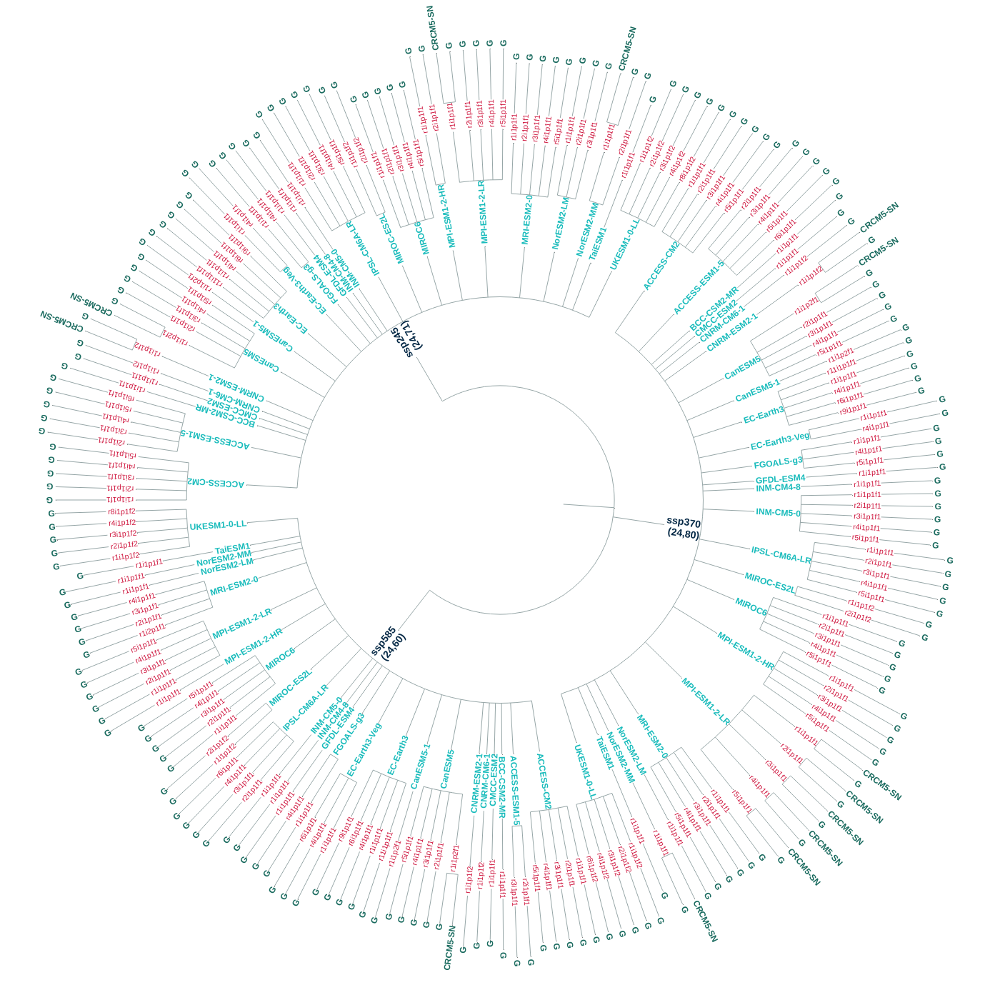

In [3]:
# need
# pip install PyQt5-sip
# pip install --no-index ete3 PyQt5



# # ── 1. Data─────────────────────────

cat_sim_id= xs.search_data_catalogs(**CONFIG["extraction"]["simulation"]["search_data_catalogs"])
df=pd.concat([cat.df for cat in cat_sim_id.values()])

ids=list(df.id.unique())
print(ids)



df=df[['source', 'member', 'experiment', 'driving_model',"driving_member" ]].drop_duplicates()
df["driving_model"] = df["driving_model"].fillna(df["source"])
df["driving_member"] = df["driving_member"].fillna(df["member"])
df.loc[df["driving_model"] == df["source"], "source"] = 'G'

# ── 2. Build the ete3 Tree from the DataFrame ─────────────────────────────────

def build_tree(df: pd.DataFrame) -> Tree:
    """
    Build a 3-level tree: experiment → member → source
    """
    root = Tree()
    root.name = "root"

    for experiment, exp_group in df.groupby("experiment"):
        exp_node = root.add_child(name=str(experiment))
 
        for source, source_group in exp_group.groupby("driving_model"):
            source_node = exp_node.add_child(name=str(source))
 
            for member, member_group in source_group.groupby("driving_member"):
                member_node = source_node.add_child(name=str(member))
            
                    
                for rcm, rcm_group in member_group.groupby("source"):
                    rcm_node = member_node.add_child(name=str(rcm))

    return root


tree = build_tree(df)


# ── 3. Style nodes by level ───────────────────────────────────────────────────

LEVEL_COLORS = {
    0: "#2c3e50" ,   # root
    1: "#052946",   # experiment
    2: "#18BBBB",   # member
    3: "#CE153D",   # source
    4: "#196a5e",   # rcm
}



def style_tree(tree: Tree) -> None:
    """Apply visual styles — no circle markers, leaf count on experiment nodes."""
    for node in tree.traverse():
        depth = node.get_distance(tree, topology_only=True)
        level = int(depth)
        color = LEVEL_COLORS.get(level, LEVEL_COLORS[3])

        # Remove all circle markers
        ns = NodeStyle()
        ns["size"] = 0
        ns["vt_line_color"] = "#95a5a6"
        ns["hz_line_color"] = "#95a5a6"
        #ns["vt_line_width"] = 1.5
        #ns["hz_line_width"] = 1.5
        node.set_style(ns)

        if node.is_root():
            continue

        

        # Experiment nodes: name + number of leaves
        if level == 1:
            n_leaves = len(node.get_leaves())
            n_children = len(node.get_children())
            label = TextFace(
                f" {node.name} \n  ({n_children},{n_leaves})",
                fsize=20,
                fgcolor=color,
                bold=True,
            )
            node.add_face(label, column=0, position="branch-right")
            #node.dist=1
        
        elif level ==2:
            label = TextFace(
                f" {node.name}",
                fsize=17,
                fgcolor=color,
                bold=True,
            )
            node.add_face(label, column=0, position="branch-right")
        elif level ==3:
            label = TextFace(
                f" {node.name}",
                fsize=15,
                fgcolor=color,
                bold=False,
            )
            node.add_face(label, column=0, position="branch-right")
        # Member and source nodes: name only
        else:
            label = TextFace(
                f" {node.name}",
                fsize=17,
                fgcolor=color,
                bold=True,
            )
            node.add_face(label, column=0, position="branch-right")


style_tree(tree)


# ── 4. Configure circular TreeStyle ──────────────────────────────────────────

ts = TreeStyle()
ts.show_leaf_name = False
ts.show_branch_length = False
ts.show_branch_support = False
ts.mode = "c"
ts.arc_start = -180
ts.arc_span  = 360
ts.show_scale = False
ts.branch_vertical_margin = -7
# ts.title.add_face(
#     TextFace("Available on narval", fsize=14, bold=True),
#     column=0,
# )
#to avoid bug on narval
# for node in tree.traverse():
#     node.img_style["hz_line_width"]=1
#     node.img_style["vt_line_width"]=1

# ── 5. Render ─────────────────────────────────────────────────────────────────

OUTPUT_FILE = f"tree_of_inputs.png"
tree.render(OUTPUT_FILE, tree_style=ts, w=1400, units="px", dpi=150)

display(Image(OUTPUT_FILE))


# Create catalogue

In [4]:
# patts = [
#     "staging/{type}/{processing_level}/{bias_adjust_project}_{version}_{bias_adjust_reference}/{mip_era}/{activity}/{domain}/{institution}/{source}/{experiment}/{member}/{frequency}/{variable}/{?:_}_{DATES}.zarr.zip",
#     "staging/{type}/{processing_level}/{bias_adjust_project}_{version}_{bias_adjust_reference}/{mip_era}/{activity}/{domain}/{institution}/{source}/{driving_model}/{driving_member}/{experiment}/{member}/{frequency}/{variable}/{?:_}_{DATES}.zarr.zip"
# ]
# df = xs.catutils.parse_directory(directories=[CONFIG['scaling'], CONFIG['espo']],
#                                  patterns=patts,
#                                  )

# display(df)
# cat = xs.ProjectCatalog.create(
#     f'{CONFIG['arches']}/cat_ARCHES.json',
#     project={'title': 'tmp_cat','id': 'tmp'},
#     overwrite=True
# )
# cat.update(df)
cat = xs.ProjectCatalog(f'{CONFIG['arches']}/cat_ARCHES.json')
display(cat.df)

,id,type,processing_level,bias_adjust_institution,bias_adjust_project,bias_adjust_reference,mip_era,activity,driving_model,driving_member,...,member,xrfreq,frequency,variable,domain,date_start,date_end,version,format,path
0,Scaling_CaSR_CMIP6_CORDEX_MPI-ESM1-2-LR_r4i1p1...,simulation,biasadjusted,NaN,Scaling,CaSR,CMIP6,CORDEX,MPI-ESM1-2-LR,r4i1p1f1,...,r1,D,day,"(tasmax,)",NAM,1951-01-01,2100-12-31 23:00:00,v20,zarr,/project/ctb-frigon/julavoie/ARCHES/scaling/st...
1,Scaling_CaSR_CMIP6_CORDEX_MPI-ESM1-2-LR_r4i1p1...,simulation,biasadjusted,NaN,Scaling,CaSR,CMIP6,CORDEX,MPI-ESM1-2-LR,r4i1p1f1,...,r1,D,day,"(dtr,)",NAM,1951-01-01,2100-12-31 23:00:00,v20,zarr,/project/ctb-frigon/julavoie/ARCHES/scaling/st...
2,Scaling_CaSR_CMIP6_CORDEX_MPI-ESM1-2-LR_r4i1p1...,simulation,biasadjusted,NaN,Scaling,CaSR,CMIP6,CORDEX,MPI-ESM1-2-LR,r4i1p1f1,...,r1,D,day,"(pr,)",NAM,1951-01-01,2100-12-31 23:00:00,v20,zarr,/project/ctb-frigon/julavoie/ARCHES/scaling/st...
3,Scaling_CaSR_CMIP6_CORDEX_MPI-ESM1-2-LR_r4i1p1...,simulation,biasadjusted,NaN,Scaling,CaSR,CMIP6,CORDEX,MPI-ESM1-2-LR,r4i1p1f1,...,r1,D,day,"(tasmin,)",NAM,1951-01-01,2100-12-31 23:00:00,v20,zarr,/project/ctb-frigon/julavoie/ARCHES/scaling/st...
4,Scaling_CaSR_CMIP6_CORDEX_MPI-ESM1-2-LR_r5i1p1...,simulation,biasadjusted,NaN,Scaling,CaSR,CMIP6,CORDEX,MPI-ESM1-2-LR,r5i1p1f1,...,r1,D,day,"(tasmin,)",NAM,1951-01-01,2100-12-31 23:00:00,v20,zarr,/project/ctb-frigon/julavoie/ARCHES/scaling/st...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1031,DQM-dtr_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-L...,simulation,biasadjusted,NaN,DQM-dtr,CaSR,CMIP6,ScenarioMIP,NaN,NaN,...,r3i1p1f2,D,day,"(tasmin,)",NAM,1951-01-01,2100-12-31 23:00:00,v20,zarr,/project/ctb-frigon/julavoie/ARCHES/dqm-dtr/st...
1032,DQM-dtr_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-L...,simulation,biasadjusted,NaN,DQM-dtr,CaSR,CMIP6,ScenarioMIP,NaN,NaN,...,r4i1p1f2,D,day,"(tasmin,)",NAM,1951-01-01,2100-12-31 23:00:00,v20,zarr,/project/ctb-frigon/julavoie/ARCHES/dqm-dtr/st...
1033,DQM-dtr_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-L...,simulation,biasadjusted,NaN,DQM-dtr,CaSR,CMIP6,ScenarioMIP,NaN,NaN,...,r4i1p1f2,D,day,"(tasmax,)",NAM,1951-01-01,2100-12-31 23:00:00,v20,zarr,/project/ctb-frigon/julavoie/ARCHES/dqm-dtr/st...
1034,DQM-dtr_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-L...,simulation,biasadjusted,NaN,DQM-dtr,CaSR,CMIP6,ScenarioMIP,NaN,NaN,...,r8i1p1f2,D,day,"(tasmax,)",NAM,1951-01-01,2100-12-31 23:00:00,v20,zarr,/project/ctb-frigon/julavoie/ARCHES/dqm-dtr/st...


# Extreme pr

In [5]:
ds= xr.open_zarr('/project/ctb-frigon/julavoie/ESPO/DQM-31jan/staging/simulation/biasadjusted/DQM_v20_CaSR/CMIP6/CORDEX/NAM/OURANOS/CRCM5-SN/CanESM5/r1i1p2f1/ssp370/r1/day/pr/pr_day_ESPO6_v20_CaSR+CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_1950-2100.zarr.zip')
ds=xs.spatial.subset(ds, method='bbox', lat_bnds=[30,40], lon_bnds=[-120,-117])
m=ds.pr.max().values
ds.where((ds.pr==m).compute(), drop=True)

2026-10-16 10:54:46 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 10:54:46 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.


<xarray.Dataset> Size: 32B
Dimensions:       (time: 1, rlat: 1, rlon: 1)
Coordinates:
  * time          (time) object 8B 2022-07-28 00:00:00
  * rlat          (rlat) float32 4B -17.1
  * rlon          (rlon) float32 4B -22.17
    lat           (rlat, rlon) float32 4B 36.72
    lon           (rlat, rlon) float32 4B -119.1
    rotated_pole  int32 4B 1
Data variables:
    pr            (time, rlat, rlon) float32 4B dask.array<chunksize=(1, 1, 1), meta=np.ndarray>
Attributes: (12/26)
    Notes:                        Regridded on the grid of the reference, the...
    avertissement:                Ouranos ne donne aucune garantie, expresse ...
    cat:_data_format_:            zarr
    cat:activity:                 CORDEX
    cat:bias_adjust_institution:  Ouranos
    cat:bias_adjust_project:      DQM
    ...                           ...
    disclaimer:                   Ouranos make no warranty, either express or...
    history:                      [2026-10-16 10:54:46] bbox spatial subsetti...
    license:                      Creative Commons Attribution 4.0 Internatio...
    organisation:                 Groupe scénarios et services climatiques, C...
    organization:                 Scenarios and Climate Services Group, Ouran...
    version:                      v20

/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xarray/core/dataarray.py:6318: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().


2026-10-16 10:55:42 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xarray/core/dataarray.py:6318: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().


2026-10-16 10:55:43 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xarray/core/dataarray.py:6318: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'stan

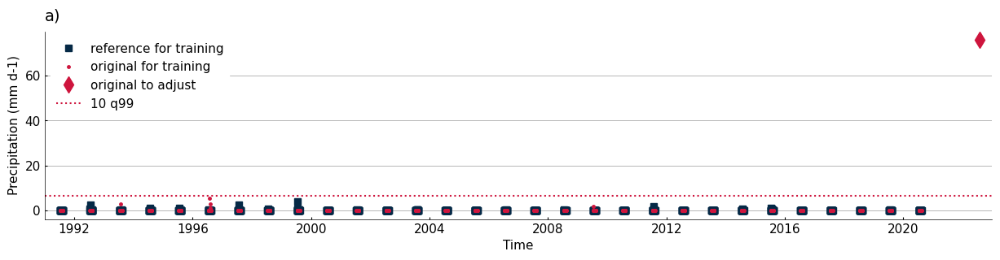

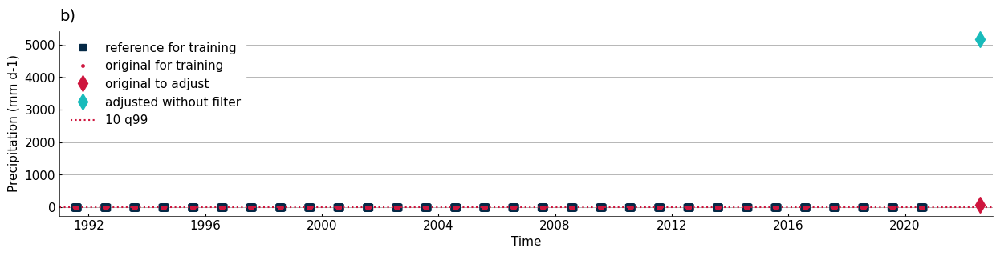

In [6]:
lat=36.71641
lon=-119.139404
date='2022-07-28'

m1=7
d1= 28-15
m2= 8
d2= 15 - (31-28)
ds_raw1 = cat_sim.search(processing_level='raw', source='CRCM5-SN', driving_model='CanESM5', experiment='historical', variable='pr', xrfreq='D').to_dataset(xarray_open_kwargs={'engine':'h5netcdf'})
ds_raw2 = cat_sim.search(processing_level='raw', source='CRCM5-SN', driving_model='CanESM5', experiment='ssp370', variable='pr', xrfreq='D').to_dataset(xarray_open_kwargs={'engine':'h5netcdf'})
ds_raw=xr.concat([ds_raw1, ds_raw2], dim='time')
ds_raw= xs.spatial.subset(ds_raw.pr, method='gridpoint', lat=lat, lon=lon)
ds_raw=xc.core.units.convert_units_to(ds_raw, 'mm/day', context='hydro')

raw_to_adjust=ds_raw.sel(time=date)
maskt = (
    (ds_raw.time.dt.month == m1) & (ds_raw.time.dt.day >= d1)
) | (
    (ds_raw.time.dt.month == m2) & (ds_raw.time.dt.day <= d2)
)

ds_raw = ds_raw.sel(time=maskt).sel(time=slice('1991','2020'))


ds_ref= xr.open_zarr(f"{CONFIG['espo']}/reference/NAM_CaSR_fullregion.zarr.zip")

ds_ref= xs.spatial.subset(ds_ref.pr, method='gridpoint', lat=lat, lon=lon)
ds_ref=xc.core.units.convert_units_to(ds_ref, 'mm/day', context='hydro')

maskt = (
    (ds_ref.time.dt.month == m1) & (ds_ref.time.dt.day >= d1)
) | (
    (ds_ref.time.dt.month == m2) & (ds_ref.time.dt.day <= d2)
)

ds_ref = ds_ref.sel(time=maskt).sel(time=slice('1991','2020'))
q99=ds_ref.quantile(0.99).values

ds_old_adj= xr.open_zarr(f'{CONFIG['nofilter']}/staging/simulation/biasadjusted/DQM_v20_CaSR/CMIP6/CORDEX/NAM/OURANOS/CRCM5-SN/CanESM5/r1i1p2f1/ssp370/r1/day/pr/pr_day_ESPO6_v20_CaSR+CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_1950-2100.zarr.zip')

ds_old_adj= xs.spatial.subset(ds_old_adj.pr.sel(time=date), method='gridpoint', lat=lat, lon=lon)
ds_old_adj=xc.core.units.convert_units_to(ds_old_adj, 'mm/day', context='hydro')

ax=fg.timeseries({ 'reference for training':ds_ref, 'original for training':ds_raw, 'original to adjust':raw_to_adjust},
                 plot_kw={
                     'original for training': {'marker':'.', 'markersize':5, 'linestyle':'none'},
                     'reference for training':{'marker':'s', 'markersize':6, 'linestyle':'none'},
                     'original to adjust':{'marker':'d', 'markersize':10, 'linestyle':'none', 'color':style_colors[1]}},
                 show_lat_lon=False,
                 fig_kw={'figsize':(15,3)})
ax.axhline(10*q99, label='10 q99', color=style_colors[1], linestyle=':')
ax.set_title('a)', loc='left')
ax.set_xlim(pd.to_datetime('1991-01-01'),pd.to_datetime('2023-01-01'))
plt.legend(loc='upper left')
plt.savefig(f"{CONFIG['figures']}/10q99exA.png",bbox_inches='tight')

ax=fg.timeseries({ 'reference for training':ds_ref, 'original for training':ds_raw,'original to adjust':raw_to_adjust, 'adjusted without filter':ds_old_adj},
                 plot_kw={
                     'original for training': {'marker':'.', 'markersize':5, 'linestyle':'none'},
                     'reference for training':{'marker':'s', 'markersize':6, 'linestyle':'none'},
                     'original to adjust':{'marker':'d', 'markersize':10, 'linestyle':'none', 'color':style_colors[1]},
                     'adjusted without filter':{'marker':'d', 'markersize':10, 'linestyle':'none', }},
                 show_lat_lon=False,
                 fig_kw={'figsize':(15,3)})
ax.axhline(10*q99, label='10 q99', color=style_colors[1], linestyle=':')
ax.set_title('b)', loc='left')
ax.set_xlim(pd.to_datetime('1991-01-01'),pd.to_datetime('2023-01-01'))
plt.legend(loc='upper left')
plt.savefig(f"{CONFIG['figures']}/10q99exB.png",bbox_inches='tight')









# DQM vs Scaling

## Spatial pattern


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo

2026-10-16 10:56:03 INFO     xscen.utils     Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}


INFO:xscen.utils:Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.


2026-10-16 10:56:05 INFO     xscen.utils     Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}


INFO:xscen.utils:Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.


2026-10-16 10:56:26 INFO     xscen.utils     Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}


INFO:xscen.utils:Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.


2026-10-16 10:56:52 INFO     xscen.utils     Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}


INFO:xscen.utils:Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.


2026-10-16 10:57:14 INFO     xscen.utils     Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}


INFO:xscen.utils:Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.


2026-10-16 10:57:39 INFO     xscen.utils     Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}


INFO:xscen.utils:Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.


2026-10-16 10:58:01 INFO     xscen.utils     Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}


INFO:xscen.utils:Converting units: {'tasmax': 'degC', 'tasmin': 'degC', 'pr': 'mm/day'}
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.


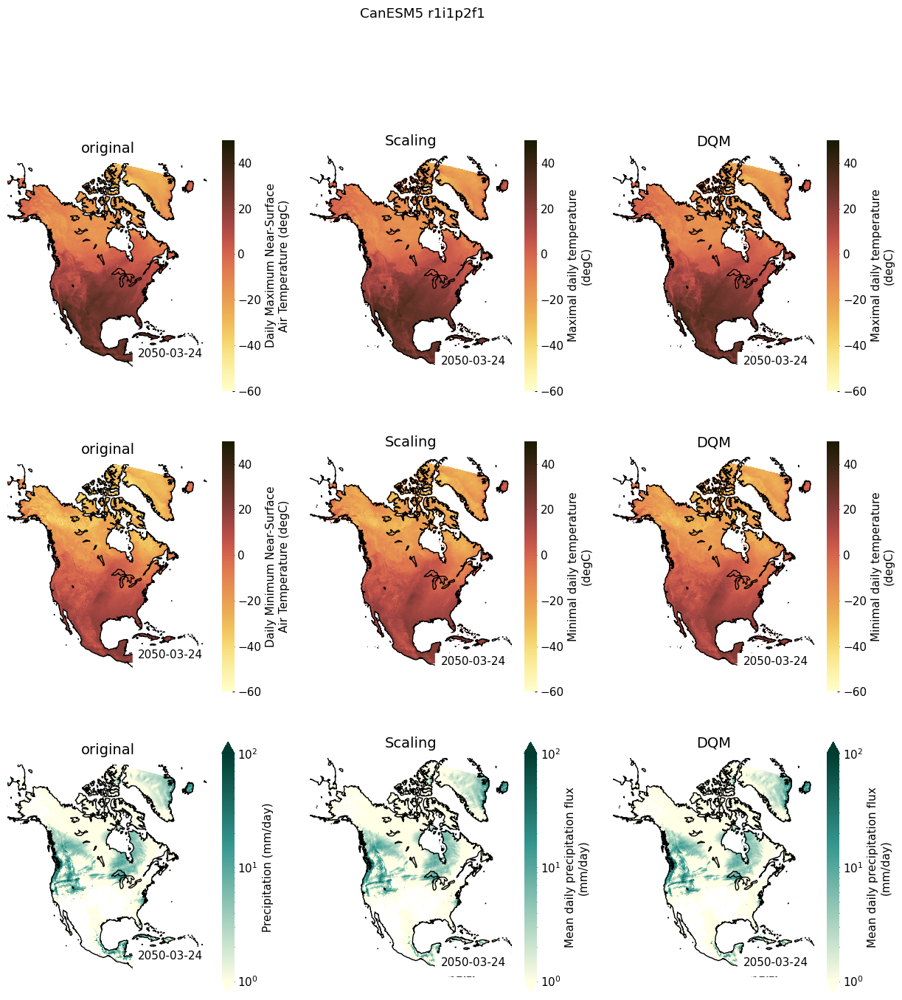

In [7]:
pw= {'tasmax': {'vmax':50,'vmin':-60},
    'tasmin': {'vmax':50,'vmin':-60},
    'pr': dict(norm=LogNorm(vmin=1, vmax=100))
    }
t='2050-03-24'
raw_dict=cat_sim.search(source='CRCM5-SN',driving_model='CanESM5', xrfreq='D',variable=variables, processing_level='raw', experiment='ssp370').to_dataset_dict(xarray_open_kwargs={'engine':'h5netcdf'})
for sim_id, ds_raw in raw_dict.items():
    dm=ds_raw.attrs['cat:driving_model']
    mem=ds_raw.attrs['cat:driving_member']
    ds_raw=xs.utils.clean_up(ds_raw, variables_and_units={'tasmax':'degC', 'tasmin':'degC', 'pr':'mm/day'})
    ds_raw=ds_raw.where(mask)
 

    
    fig, axs= plt.subplots(3,3, subplot_kw={'projection': map_proj}, figsize=(15,15))
    fig.suptitle(f"{dm} {mem}", y=1)
    for i,var in enumerate(variables):
            
        fg.gridmap(ds_raw[var].sel(time=t),show_time=True, ax=axs[i,0], features=fe,
                   plot_kw=pw[var].copy()
                  )
        axs[i,0].set_title('original')
                               
        for j,m in enumerate(['Scaling', 'ESPO'],1):
            ds=cat.search(bias_adjust_project=m, driving_model=dm,driving_member=mem, source='CRCM5-SN', experiment='ssp370', variable=var).to_dataset()
            ds=xs.utils.clean_up(ds, variables_and_units={'tasmax':'degC', 'tasmin':'degC', 'pr':'mm/day'})
            fg.gridmap(ds.sel(time=t),show_time=True, ax=axs[i,j], features=fe,
                       plot_kw=pw[var].copy()
                      )
            axs[i,j].set_title(m.replace("ESPO","DQM"))
    plt.savefig(f"{CONFIG['figures']}/spatial_{dm}_{mem}.png",bbox_inches='tight')


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo

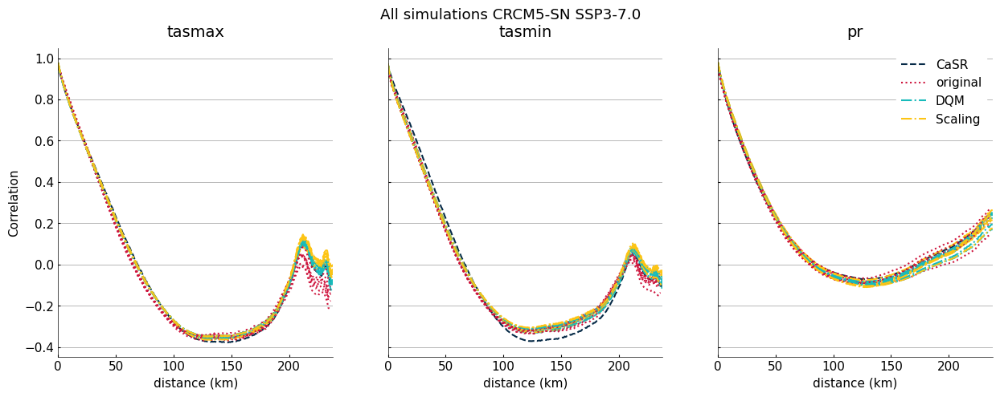

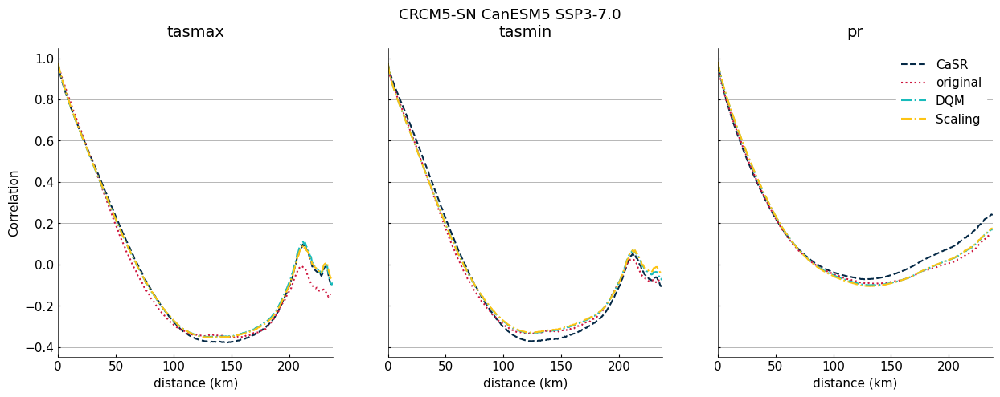

In [8]:
#spatial correlogram
# created by running post-workflow-analysis/correlogram.py
fig, axs = plt.subplots(1,3, figsize=(15,5), sharex=True,sharey=True)
fig.suptitle('All simulations CRCM5-SN SSP3-7.0')
axs[0].set_ylabel('Correlation')

for i,var in enumerate(variables):
    axs[i].set_title(var)
    sc_ref= xr.open_zarr(f"{CONFIG['arches']}/correlogram/CaSR_atlas_correlogram-{var}.zarr.zip", decode_timedelta=False).spatial_correlogram
    
    axs[i].plot(sc_ref, label='CaSR', linestyle='--', color=key_colors['CaSR'])
    axs[i].set_xlabel('distance (km)')

    adj_dict=cat.search(source='CRCM5-SN', experiment='ssp370', bias_adjust_project='ESPO').to_dataset_dict()
    for sim_id, ds in adj_dict.items():
        dm=ds.attrs['cat:driving_model']
        mem=ds.attrs['cat:driving_member']
        
        sc_espo= xr.open_zarr(f"{CONFIG['arches']}/correlogram/ESPO_{dm}_{mem}_CRCM5-SN_ssp370_atlas_correlogram-{var}.zarr.zip", decode_timedelta=False)
        sc_scaling= xr.open_zarr(f"{CONFIG['arches']}/correlogram/Scaling_{dm}_{mem}_CRCM5-SN_ssp370_atlas_correlogram-{var}.zarr.zip", decode_timedelta=False)

        sc_ext = xr.open_zarr(f"{CONFIG['arches']}/correlogram/raw_{dm}_{mem}_CRCM5-SN_ssp370_atlas_correlogram-{var}.zarr.zip", decode_timedelta=False)

        axs[i].plot(sc_ext.spatial_correlogram, label=f'original' , linestyle=':', color=key_colors['raw'])
        axs[i].plot(sc_espo.spatial_correlogram, label='DQM',color=key_colors['ESPO'], linestyle='-.')
        axs[i].plot(sc_scaling.spatial_correlogram, label='Scaling',color=key_colors['Scaling'], linestyle='-.')

    

    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys())

fig, axs = plt.subplots(1,3, figsize=(15,5), sharex=True,sharey=True)
fig.suptitle('CRCM5-SN CanESM5 SSP3-7.0')
axs[0].set_ylabel('Correlation')

for i,var in enumerate(variables):
    axs[i].set_title(var)
    sc_ref= xr.open_zarr(f"{CONFIG['arches']}/correlogram/CaSR_atlas_correlogram-{var}.zarr.zip", decode_timedelta=False).spatial_correlogram
    
    axs[i].plot(sc_ref, label='CaSR', linestyle='--', color=key_colors['CaSR'])
    axs[i].set_xlabel('distance (km)')

    adj_dict=cat.search(source='CRCM5-SN', driving_model='CanESM5', experiment='ssp370', bias_adjust_project='ESPO').to_dataset_dict()
    for sim_id, ds in adj_dict.items():
        dm=ds.attrs['cat:driving_model']
        mem=ds.attrs['cat:driving_member']
        
        sc_espo= xr.open_zarr(f"{CONFIG['arches']}/correlogram/ESPO_{dm}_{mem}_CRCM5-SN_ssp370_atlas_correlogram-{var}.zarr.zip", decode_timedelta=False)
        sc_scaling= xr.open_zarr(f"{CONFIG['arches']}/correlogram/Scaling_{dm}_{mem}_CRCM5-SN_ssp370_atlas_correlogram-{var}.zarr.zip", decode_timedelta=False)

        sc_ext = xr.open_zarr(f"{CONFIG['arches']}/correlogram/raw_{dm}_{mem}_CRCM5-SN_ssp370_atlas_correlogram-{var}.zarr.zip", decode_timedelta=False)

        axs[i].plot(sc_ext.spatial_correlogram, label=f'original' , linestyle=':', color=key_colors['raw'])
        axs[i].plot(sc_espo.spatial_correlogram, label='DQM',color=key_colors['ESPO'], linestyle='-.')
        axs[i].plot(sc_scaling.spatial_correlogram, label='Scaling',color=key_colors['Scaling'], linestyle='-.')

    

    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys())
    plt.savefig(f"{CONFIG['figures']}/correlogram_CanESM5_atlas.pdf",bbox_inches='tight')
                     


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo

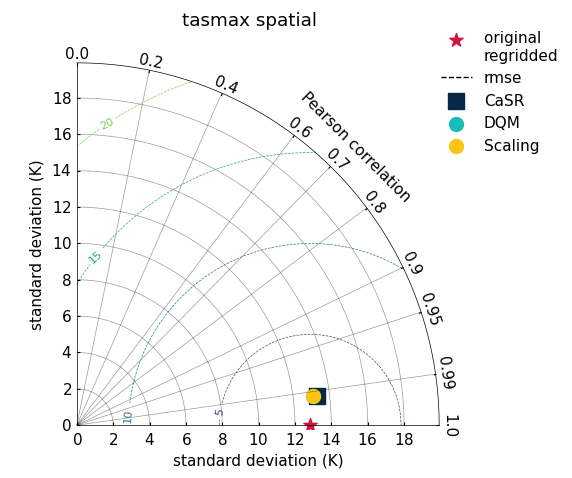

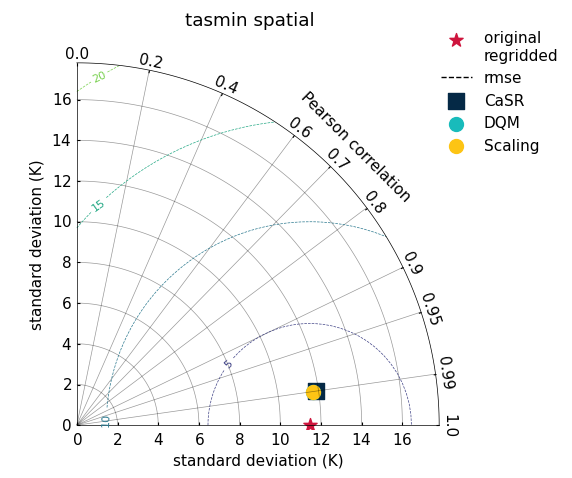

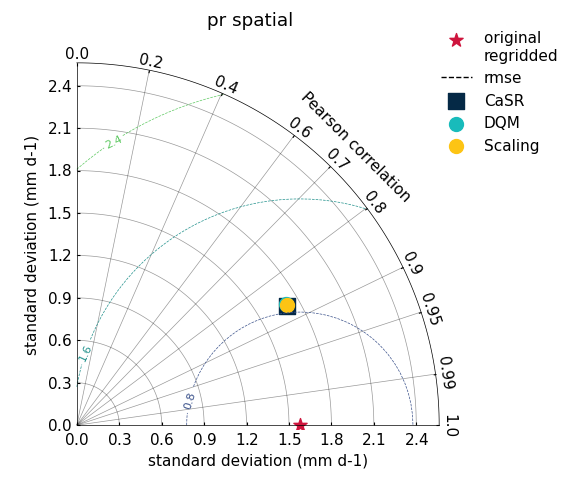

In [9]:
# spatial taylor diag
# created by running post-workflow-analysis/taylordiag.py
s=100
for i,var in enumerate(variables):


    d={}   
        
    adj_dict=cat.search(source='CRCM5-SN', experiment='ssp370', bias_adjust_project='ESPO', driving_model='CanESM5').to_dataset_dict()
    for sim_id, ds in adj_dict.items():
        dm=ds.attrs['cat:driving_model']
        mem=ds.attrs['cat:driving_member']

        out_ref = xr.open_zarr(f"{CONFIG['arches']}/taylordiag/CaSR_{dm}_{mem}_CRCM5-SN_ssp370_taylordiag-spatial-{var}.zarr.zip")
        d['CaSR']=out_ref.taylordiagram
            
        for baj in ['ESPO','Scaling']:
            out = xr.open_zarr(f"{CONFIG['arches']}/taylordiag/{baj}_{dm}_{mem}_CRCM5-SN_ssp370_taylordiag-spatial-{var}.zarr.zip")
            d[baj.replace('ESPO','DQM')]=out.taylordiagram


            
        
        fig, floating_ax, legend=fg.taylordiagram(
            d,
            plot_kw={"reference": {'color': key_colors['raw'],"marker": "*", "s":s},
                    'CaSR': {'color': key_colors['CaSR'],"marker": "s", "s":130},
                    'DQM':{'color': key_colors['ESPO'], "s":s},
                     'Scaling':{'color': key_colors['Scaling'], "s":s},
                    },
        )
        legend.get_texts()[0].set_text('\noriginal \nregridded')
        #fig.suptitle(f"{dm} {mem} {var} spatial")
        fig.suptitle(f"{var} spatial")
        plt.savefig(f"{CONFIG['figures']}/taylordiagram-spatial_{dm}_{var}.pdf",bbox_inches='tight')

## temporal


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo

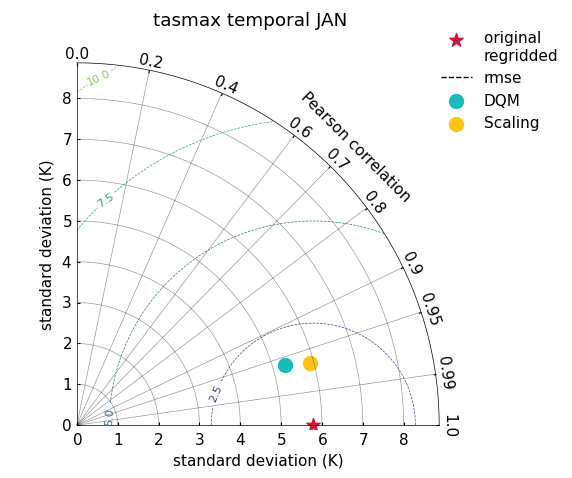

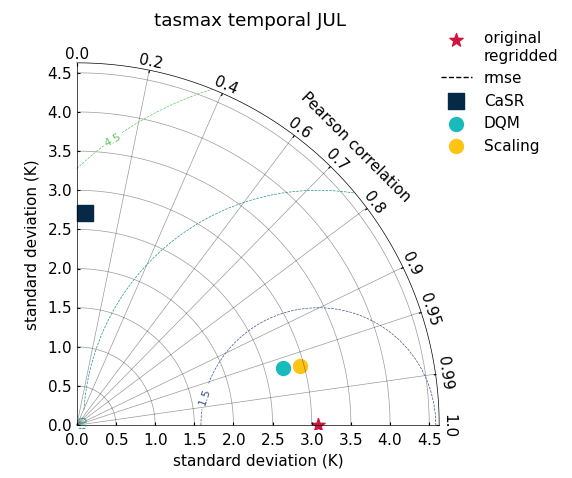

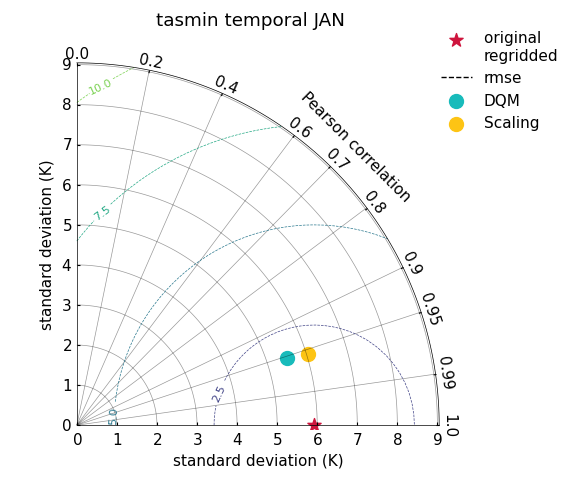

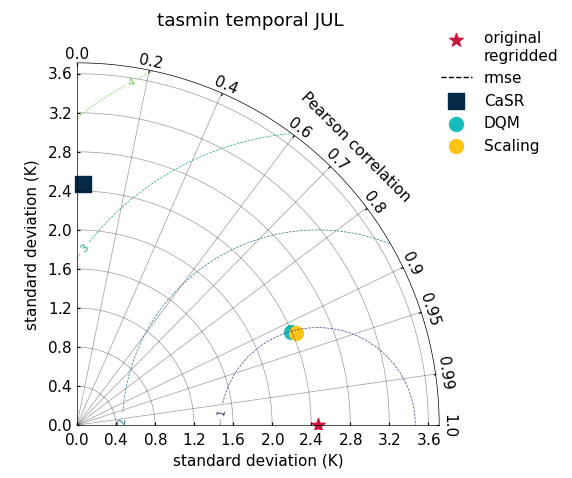

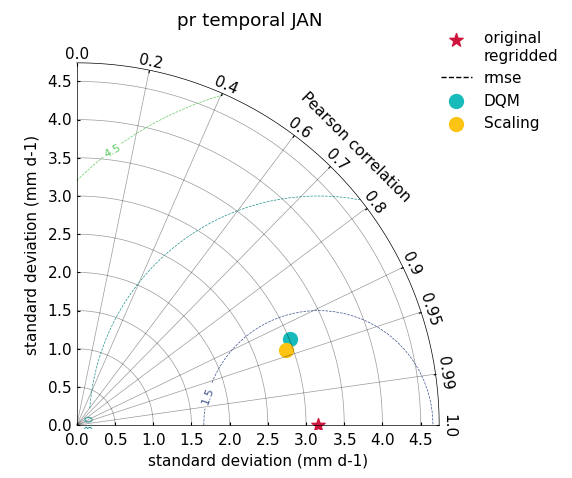

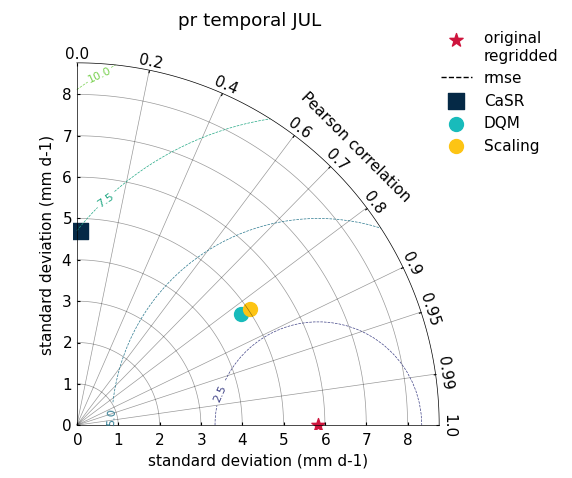

In [10]:
# temporaltaylor diag
# created by running post-workflow-analysis/taylordiag.py
s=100
for i,var in enumerate(variables):
    for month in ['JAN','JUL']:

    
        d={}   
            
        adj_dict=cat.search(source='CRCM5-SN', experiment='ssp370', bias_adjust_project='ESPO', driving_model='CanESM5').to_dataset_dict()
        for sim_id, ds in adj_dict.items():
            dm=ds.attrs['cat:driving_model']
            mem=ds.attrs['cat:driving_member']
    
            out_ref = xr.open_zarr(f"{CONFIG['arches']}/taylordiag/CaSR_{dm}_{mem}_CRCM5-SN_ssp370_taylordiag-temporal{month}-{var}.zarr.zip")
            d['CaSR']=out_ref.taylordiagram
                
            for baj in ['ESPO','Scaling']:
                out = xr.open_zarr(f"{CONFIG['arches']}/taylordiag/{baj}_{dm}_{mem}_CRCM5-SN_ssp370_taylordiag-temporal{month}-{var}.zarr.zip")
                d[baj.replace('ESPO','DQM')]=out.taylordiagram
    
    
                
            
            fig, floating_ax, legend=fg.taylordiagram(
                d,
                plot_kw={"reference": {'color': key_colors['raw'],"marker": "*", "s":s},
                        'CaSR': {'color': key_colors['CaSR'],"marker": "s", "s":130},
                        'DQM':{'color': key_colors['ESPO'], "s":s},
                         'Scaling':{'color': key_colors['Scaling'], "s":s},
                        },
            )
            legend.get_texts()[0].set_text('\noriginal \nregridded')
            #fig.suptitle(f"{dm} {mem} {var} spatial")
            fig.suptitle(f"{var} temporal {month}")
            plt.savefig(f"{CONFIG['figures']}/taylordiagram-temporal{month}_{dm}_{var}.pdf",bbox_inches='tight')

## VALUE

/tmp/ipykernel_1516757/3249649762.py:65: UserWarning: Colormap warning: Variable group not found. Use the cmap argument.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib

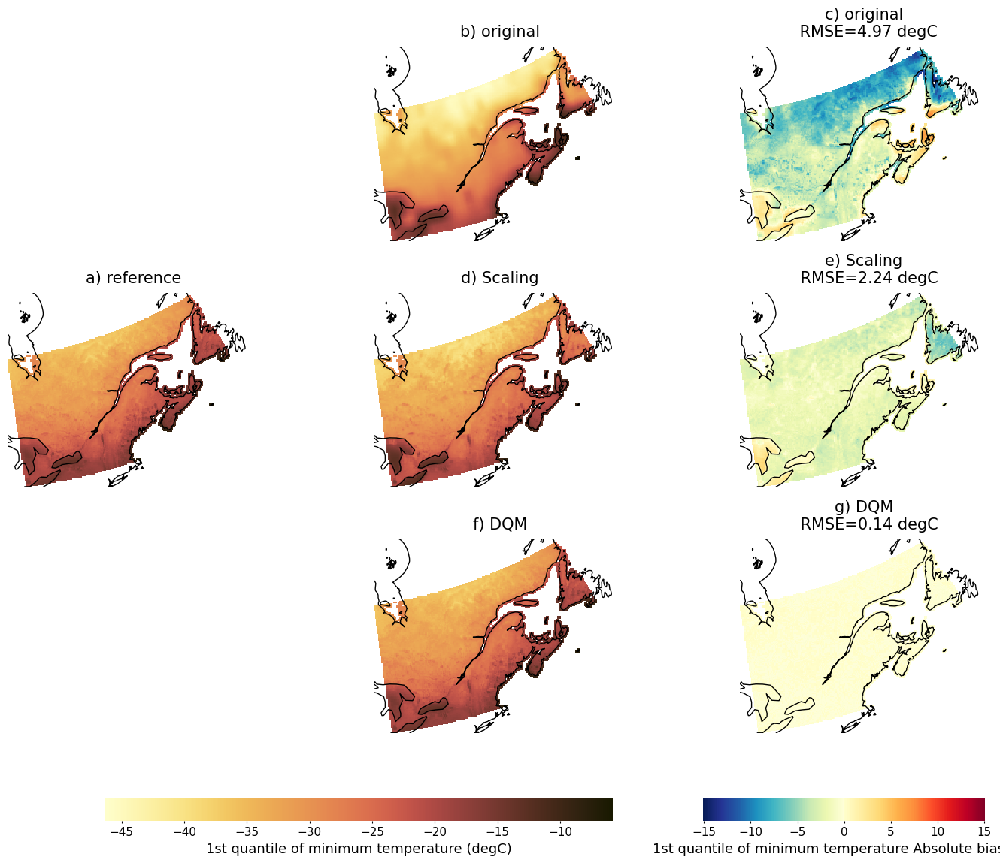

In [11]:
var='q01_tasmin'
prop_ref=xr.open_zarr(f"{CONFIG['scaling']}/diagnostics/CaSR/NAM/Atlas/ref-prop.zarr.zip")[var]
prop_sim=xr.open_zarr(f"{CONFIG['scaling']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_sim-prop.zarr.zip")[var]
meas_sim_prop=xr.open_zarr(f"{CONFIG['scaling']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_sim-meas.zarr.zip")[var]
prop_scen1=xr.open_zarr(f"{CONFIG['scaling']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_scen-prop.zarr.zip")[var]
meas_scen1_prop=xr.open_zarr(f"{CONFIG['scaling']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_scen-meas.zarr.zip")[var]
prop_scen2=xr.open_zarr(f"{CONFIG['espo']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_scen-prop.zarr.zip")[var]
meas_scen2_prop=xr.open_zarr(f"{CONFIG['espo']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_scen-meas.zarr.zip")[var]

maps2('Scaling', 'DQM',prop_ref, prop_sim, prop_scen1, prop_scen2, meas_sim_prop, meas_scen1_prop, meas_scen2_prop)
plt.savefig(f"{CONFIG['figures']}/q01tasmin_scalingVSDQM.pdf",bbox_inches='tight')



--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


/tmp/ipykernel_1516757/4226584797.py:45: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/tmp/ipykernel_1516757/4226584797.py:45: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/tmp/ipykernel_1516757/4226584797.py:45: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='o

25


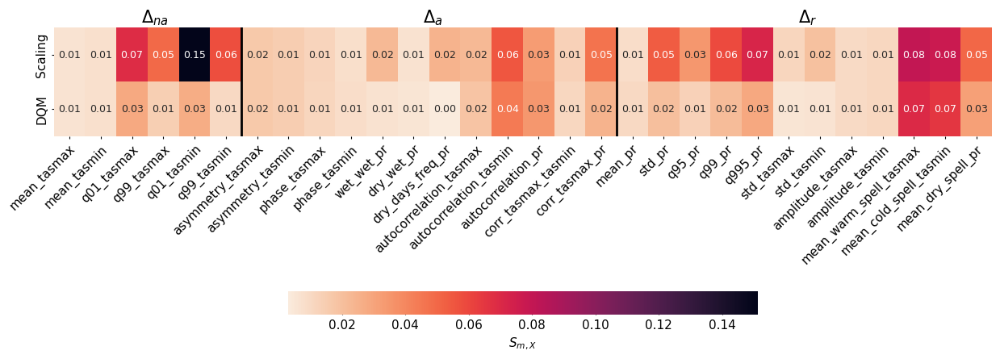

In [12]:
# gab version of heatmap

#ordered by scores type
ordered_properties=[
    "mean_tasmax","mean_tasmin", "q01_tasmax","q99_tasmax","q01_tasmin","q99_tasmin",
    'asymmetry_tasmax', 'asymmetry_tasmin',      'phase_tasmax', 'phase_tasmin', "wet_wet_pr","dry_wet_pr",'dry_days_freq_pr',  
        'autocorrelation_tasmax','autocorrelation_tasmin', 'autocorrelation_pr',"corr_tasmax_tasmin","corr_tasmax_pr",
    "mean_pr",  'std_pr',"q95_pr","q99_pr","q995_pr",'std_tasmax', 'std_tasmin','amplitude_tasmax', 'amplitude_tasmin',                 
         "mean_warm_spell_tasmax",'mean_cold_spell_tasmin','mean_dry_spell_pr',
                   ]

all_sims=[]
all_mets=[]

# # regridded
# sims=[]
adj_dict=cat_sim.search(source='CRCM5-SN',variable='tasmax', experiment='ssp370', processing_level='raw').to_dataset_dict(xarray_open_kwargs={'engine':'h5netcdf'})
ids=[k.replace('.NAM-12.raw.D','') for k in adj_dict.keys()]

#adjusted
for m in ['scaling','espo']:
    sims=[]
    ref= xr.open_zarr(f"{CONFIG[m]}/diagnostics/CaSR/NAM/Atlas/ref-prop.zarr.zip", decode_timedelta=False)
    for sim_id in ids:
        #ds= xr.open_zarr(f"{CONFIG[m]}/diagnostics/CaSR/NAM/Atlas/{sim_id}/{sim_id}_NAM_Atlas_scen-meas.zarr.zip", decode_timedelta=False)
        ds= xr.open_zarr(f"{CONFIG[m]}/diagnostics/CaSR/NAM/Atlas/{sim_id}/{sim_id}_NAM_Atlas_scen-prop.zarr.zip", decode_timedelta=False)

        
        # code de gab
        for v in [v for v in ds.data_vars if "asymmetry" in v]:
            ds[v].attrs["units"] = ""
            ref[v].attrs["units"] = ""

        # compute_diff modify to use meas instead of prop
        abs_v = [v for v in ds.data_vars if ds[v].attrs.get("units", "") == "" and 'phase' not in v]
        temp_v = [v for v in ds.data_vars if (ds[v].attrs.get("units", "") in ["degC"]) and any(prefix in v for prefix in ["mean", "q01", "q50", "q95", "q99", "q995"])]
        phase_v = [v for v in ds.data_vars if 'phase' in v]
        other_v = [v for v in ds.data_vars if v not in abs_v + temp_v + phase_v]
    
        ds_diff_abs = ds[abs_v] - ref[abs_v]
        if len(temp_v) > 0:
            for variable in ["tasmin", "tasmax"]:
                var_temp_v = [v for v in temp_v if variable in v]
                ds_diff_temp = ((ds[var_temp_v] - ref[var_temp_v]) / (ref[f"std_{variable}"]))
                ds_diff_abs = xr.merge([ds_diff_abs, ds_diff_temp])
        ds_diff_rel = (ds[other_v] - ref[other_v]) / ref[other_v].clip(min=0.00001)

        # circular bias 
        ds_diff_phase=   (ds[phase_v] - ref[phase_v]) % 365
        ds_diff_phase = ds_diff_phase.where(ds_diff_phase <= 365 / 2, 365 - ds_diff_phase)  # when condition false, replace by 2nd arg
        ds_diff_phase = ds_diff_phase.where(ref[phase_v] >= ds[phase_v], ds_diff_phase * -1)
        ds_diff_phase = ds_diff_phase/365 # normalize
    
        out = xr.merge([ds_diff_abs, ds_diff_rel, ds_diff_phase], compat="no_conflicts")

        
        meas_adj_mean= abs(out).mean() # spatial mean
        sims.append(meas_adj_mean.expand_dims(realization=[sim_id]))
        all_sims.append(meas_adj_mean.expand_dims(realization=[f"{m}_{sim_id}"]))
    ds_sims=xr.concat(sims, dim='realization').mean('realization')
    all_mets.append(ds_sims.expand_dims(realization=[m.replace('scaling','Scaling').replace('espo','DQM')]))


ds_all=xr.concat(all_sims, dim='realization').to_array(dim='properties').T
ds_all=ds_all.sel(properties=ordered_properties)
# ax=fg.heatmap(ds_all,plot_kw={'annot':True, }, fig_kw={'figsize':(15,5)},divergent=0, cmap='RdBu_r')
# ax.set_title('Atlas')

    
ds_mets=xr.concat(all_mets, dim='realization')   
# put props in dims, instead of var
ds_mets=ds_mets.to_array(dim='properties').T

ds_mets=ds_mets.sel(properties=ordered_properties)

ds_mets.attrs['long_name']=r"$S_{m,X}$"
ax=fg.heatmap(ds_mets,plot_kw={'annot':True,'fmt':".2f",'annot_kws':{"size": 9},'cbar_kws':{"orientation": "horizontal","pad": 0.5,"shrink": 0.5 }},
              fig_kw={'figsize':(15,5)}, cmap='rocket_r')#RdBu_r, divergent=0,
#ax.set_title('Atlas', y=1.1, fontsize=20)
ax.set_ylabel('')
ax.set_xlabel('')

texts = ax.texts

ax.axvline(x=6, linewidth=2, color="black")
ax.axvline(x=18, linewidth=2, color="black")
ax.text(2.8, -0.1, r"$\Delta_{na}$", fontsize=15)
ax.text(11.8, -0.1, r"$\Delta_{a}$", fontsize=15)
ax.text(23.8,-0.1, r"$\Delta_{r}$", fontsize=15)

plt.savefig(f"{CONFIG['figures']}/score_ScalingvsDQM.pdf",bbox_inches='tight')
print(((ds_mets.isel(realization=0)-ds_mets.isel(realization=1))>0).sum().values)



# DQM-tasmin vs DQM-dtr

## create DQM-dtr

DQM-dtr was created by running post-workflow-analysis/create-DQM-dtr.py

In [13]:
# patts = [
#     "staging/{type}/{processing_level}/{bias_adjust_project}_{version}_{bias_adjust_reference}/{mip_era}/{activity}/{domain}/{institution}/{source}/{experiment}/{member}/{frequency}/{variable}/{?:_}_{DATES}.zarr.zip",
#     "staging/{type}/{processing_level}/{bias_adjust_project}_{version}_{bias_adjust_reference}/{mip_era}/{activity}/{domain}/{institution}/{source}/{driving_model}/{driving_member}/{experiment}/{member}/{frequency}/{variable}/{?:_}_{DATES}.zarr.zip"
# ]
# df = xs.catutils.parse_directory(directories=[CONFIG['dqm-dtr']],
#                                  patterns=patts,
#                                  )

# display(df)

# cat.update(df)

## temperature inversion


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:678: UserWarning: Attribute "units" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:678: UserWarning: Attribute "units" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:678: UserWarning: Attribute "units" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:678: UserWarning: Attribute "units" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:678: UserWarning: Attribute "units" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:678: UserWarning: Attribute "units" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.

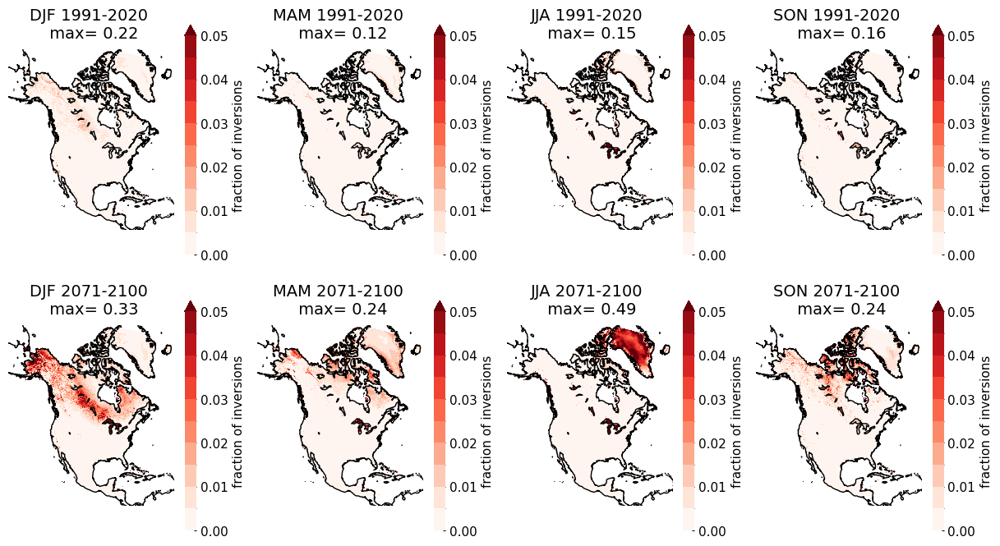

In [14]:
fig, axs = plt.subplots(2,4, figsize=(15,8), subplot_kw={'projection':map_proj})
for i,season in enumerate(['DJF', 'MAM','JJA','SON']):
    for j, period in enumerate([['1991','2020'],['2071','2100']]):
        frac=xr.open_zarr(f"{CONFIG['arches']}/inversion/frac_{season}_{period[0]}.zarr.zip", decode_timedelta=False)
        fg.gridmap(frac, features=fe, ax=axs[j,i],levels = [0,0.005,0.01,0.015,0.02,0.025,0.03,0.035,0.04,0.045,0.05], cmap='Reds')
        axs[j,i].set_title(f"{season} {'-'.join(period)} \n max= {round(float(frac.dtr.max().values),2)}")
plt.savefig(f"{CONFIG['figures']}/inversions_mapfrac.png",bbox_inches='tight')



<xarray.Dataset> Size: 106GB
Dimensions:       (realization: 80, time: 151, season: 4, rlat: 778, rlon: 706)
Coordinates:
  * time          (time) datetime64[ns] 1kB 1950-01-01 1951-01-01 ... 2100-01-01
  * season        (season) <U3 48B 'MAM' 'JJA' 'SON' 'DJF'
  * rlat          (rlat) float32 3kB -44.1 -44.01 -43.92 ... 25.65 25.74 25.83
  * rlon          (rlon) float32 3kB -35.4 -35.31 -35.22 ... 27.87 27.96 28.05
    lat           (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    lon           (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    rotated_pole  int32 4B ...
Dimensions without coordinates: realization
Data variables:
    dtr           (realization, time, season, rlat, rlon) float32 106GB dask.array<chunksize=(80, 151, 1, 50, 50), meta=np.ndarray>
Attributes: (12/22)
    avertissement:                Ouranos ne donne aucune garantie, expresse ...
    cat:_data_format_:            zarr
    cat:activity:                 ScenarioMIP
    cat:bias_adjust_institution:  Ouranos
    cat:bias_adjust_project:      ESPO
    cat:bias_adjust_reference:    CaSR
    ...                           ...
    disclaimer:                   Ouranos make no warranty, either express or...
    history:                      [2026-07-07 19:45:43] dtr computed from adj...
    license:                      Creative Commons Attribution 4.0 Internatio...
    organisation:                 Équipe science du climat et services climat...
    organization:                 Climate Science and Climate Services Team, ...
    version:                      v2.0

2026-10-16 11:01:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:01:58 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.


-1.0961448
2026-10-16 11:02:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:02:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.


-0.8006025
2026-10-16 11:02:51 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:02:51 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.


-1.5550232
2026-10-16 11:03:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:03:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.


-1.3063558
2026-10-16 11:03:38 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:03:38 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.


-1.9171448
2026-10-16 11:03:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:03:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.


-1.9265747
2026-10-16 11:04:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:04:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.


-1.6126404
2026-10-16 11:04:45 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:04:45 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.


-0.9327755


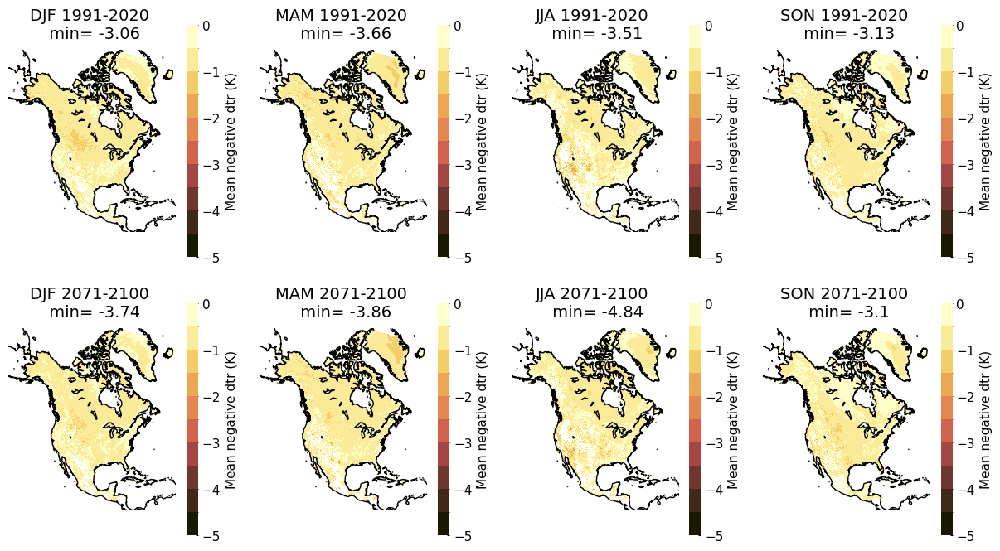

In [15]:

# from inversion.py
ens=xr.open_zarr(f"{CONFIG['espo']}/preswap/ens_dtrpreswap_day_ESPO6_v20_CaSR_NAM.zarr.zip", decode_timedelta=False)
display(ens)

fig, axs = plt.subplots(2,4, figsize=(15,8), subplot_kw={'projection':map_proj})
for i,season in enumerate(['DJF', 'MAM','JJA','SON']):
    for j, period in enumerate([['1991','2020'],['2071','2100']]):
        out= ens.sel(time=slice(period[0],period[1]), season=season).mean(['time','realization'])
        out.dtr.attrs['long_name']='Mean negative dtr'# pre-swap for DQM-tasmin'
        
        fg.gridmap(out, features=fe, ax=axs[j,i], cmap='temp_seq_r',
                   levels = [-5,-4.5,-4,-3.5,-3,-2.5,-2,-1.5,-1,-0.5,0])#,plot_kw={'vmin':-5, 'vmax':0)
        axs[j,i].set_title(f"{season} {'-'.join(period)} \n min= {round(float(out.dtr.min().values),2)}")
        qc= xs.spatial.subset(out,  method="shape", shape="../config/region_qc.zip")
        print(qc.dtr.min().values)
        
plt.savefig(f"{CONFIG['figures']}/inversions_mapmean.png",bbox_inches='tight')



2026-10-16 11:05:04 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/intake_esm/source.py:272: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/lustre06/project/6046550/julavoie/envs/espo

2026-10-16 11:05:04 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not fou

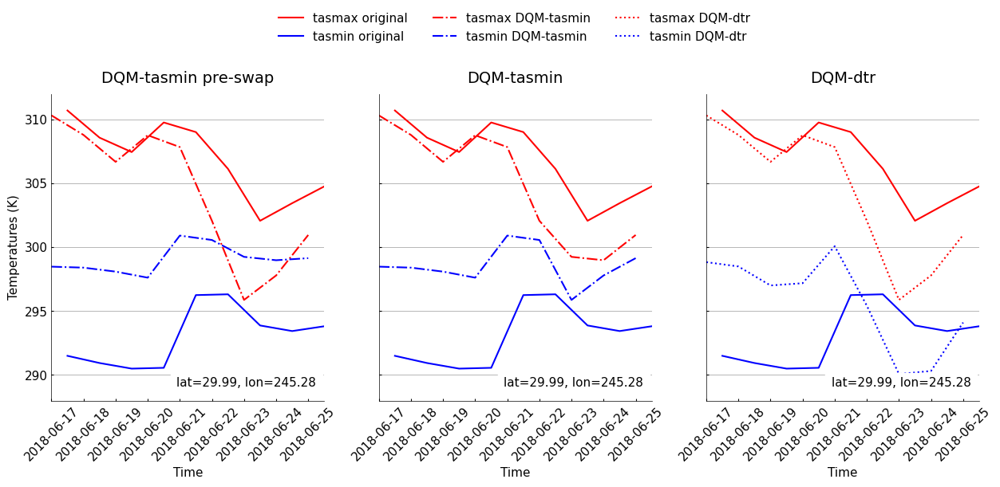

In [16]:
raw= cat_sim.search(processing_level='raw', source='CRCM5-SN', driving_model='CanESM5', variable=['tasmax','tasmin'], experiment='ssp370').to_dataset(xarray_open_kwargs={'engine':'h5netcdf'})
raw= xs.spatial.subset(raw, method='gridpoint', lat=29.978115,lon=-114.65858)
ds_tasmin_max=xr.open_zarr(f"{CONFIG['espo']}/staging/simulation/biasadjusted/ESPO_v20_CaSR/CMIP6/CORDEX/NAM/OURANOS/CRCM5-SN/CanESM5/r1i1p2f1/ssp370/r1/day/tasmax/tasmax_day_ESPO6_v20_CaSR+CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_1951-2100.zarr.zip", decode_timedelta=False)
ds_tasmin_min=xr.open_zarr(f"{CONFIG['espo']}/staging/simulation/biasadjusted/ESPO_v20_CaSR/CMIP6/CORDEX/NAM/OURANOS/CRCM5-SN/CanESM5/r1i1p2f1/ssp370/r1/day/tasmin/tasmin_day_ESPO6_v20_CaSR+CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_1951-2100.zarr.zip", decode_timedelta=False)

ds_dtr_max=xr.open_zarr(f"{CONFIG['dqm-dtr']}/staging/simulation/biasadjusted/DQM-dtr_v20_CaSR/CMIP6/CORDEX/NAM/OURANOS/CRCM5-SN/CanESM5/r1i1p2f1/ssp370/r1/day/tasmax/tasmax_day_DQM-dtr_v20_CaSR+CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_1951-2100.zarr.zip", decode_timedelta=False)
ds_dtr_min=xr.open_zarr(f"{CONFIG['dqm-dtr']}/staging/simulation/biasadjusted/DQM-dtr_v20_CaSR/CMIP6/CORDEX/NAM/OURANOS/CRCM5-SN/CanESM5/r1i1p2f1/ssp370/r1/day/tasmin/tasmin_day_DQM-dtr_v20_CaSR+CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_1951-2100.zarr.zip", decode_timedelta=False)

ds_tasmin_max_preswap=ds_tasmin_max.copy(deep=True)
ds_tasmin_min_preswap=ds_tasmin_min.copy(deep=True)

maxpreswap= ds_tasmin_min.tasmin.sel(time='2018-06-23').values
minpreswap= ds_tasmin_max.tasmax.sel(time='2018-06-23').values

ds_tasmin_max_preswap['tasmax'].loc[dict(time='2018-06-23')] = maxpreswap
ds_tasmin_min_preswap['tasmin'].loc[dict(time='2018-06-23')] = minpreswap

maxpreswap= ds_tasmin_min.tasmin.sel(time='2018-06-24').values
minpreswap= ds_tasmin_max.tasmax.sel(time='2018-06-24').values

ds_tasmin_max_preswap['tasmax'].loc[dict(time='2018-06-24')] = maxpreswap
ds_tasmin_min_preswap['tasmin'].loc[dict(time='2018-06-24')] = minpreswap

fig,axs=plt.subplots(1,3, figsize=(15,5), sharey=True)

timesel=slice('2018-06-17','2018-06-25')

fg.timeseries({
            'tasmax original':raw.tasmax.sel( time=timesel),
            'tasmax DQM-tasmin': ds_tasmin_max_preswap.tasmax.sel(rlat=-24.750002,rlon=-21.177216, time=timesel),
              
            'tasmin original':raw.tasmin.sel(time=timesel),
             'tasmin DQM-tasmin': ds_tasmin_min_preswap.tasmin.sel(rlat=-24.750002,rlon=-21.177216, time=timesel),
                  
                 },
                 plot_kw={
                   'tasmax DQM-tasmin': {'color':'red', 'linestyle': '-.'},
             'tasmin DQM-tasmin': {'color':'blue', 'linestyle': '-.'},
                    'tasmax original':{'color':'red', 'linestyle': '-'},
                        'tasmin original':{'color':'blue', 'linestyle': '-'},
                 },
              ax=axs[0],legend=None
                )

fg.timeseries({
            'tasmax original':raw.tasmax.sel( time=timesel),
                'tasmin original':raw.tasmin.sel(time=timesel),

            'tasmax DQM-tasmin': ds_tasmin_max.tasmax.sel(rlat=-24.750002,rlon=-21.177216, time=timesel),
              
             'tasmin DQM-tasmin': ds_tasmin_min.tasmin.sel(rlat=-24.750002,rlon=-21.177216, time=timesel),
                  
                 },
                 plot_kw={
                   'tasmax DQM-tasmin': {'color':'red', 'linestyle': '-.'},
             'tasmin DQM-tasmin': {'color':'blue', 'linestyle': '-.'},
                    'tasmax original':{'color':'red', 'linestyle': '-'},
                        'tasmin original':{'color':'blue', 'linestyle': '-'},
                 },
              ax=axs[1],legend=None
                )

fg.timeseries({
            'tasmax original':raw.tasmax.sel( time=timesel),
                'tasmin original':raw.tasmin.sel(time=timesel),

            'tasmax DQM-dtr': ds_dtr_max.tasmax.sel(rlat=-24.750002,rlon=-21.177216, time=timesel),
              
             'tasmin DQM-dtr': ds_dtr_min.tasmin.sel(rlat=-24.750002,rlon=-21.177216, time=timesel),
                  
                 },
                 plot_kw={
                     'tasmax DQM-dtr': {'color':'red', 'linestyle': ':'},
             'tasmin DQM-dtr': {'color':'blue', 'linestyle': ':'},
                    'tasmax original':{'color':'red', 'linestyle': '-'},
                        'tasmin original':{'color':'blue', 'linestyle': '-'},
                 },
              ax=axs[2],
              legend=None
                )
axs[0].set_ylabel('Temperatures (K)')
axs[1].set_ylabel('')
axs[2].set_ylabel('')
axs[0].tick_params(axis='x', rotation=45)
axs[1].tick_params(axis='x', rotation=45)
axs[2].tick_params(axis='x', rotation=45)
axs[0].set_title('DQM-tasmin pre-swap')
axs[1].set_title('DQM-tasmin')
axs[2].set_title('DQM-dtr')
axs[2].set_ylim(288,312)


# lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes[1:]]
# lines, labels = [sum(lol, []) for lol in zip(*lines_labels)]
# fig.legend(lines, labels, bbox_to_anchor=(1,1), ncol=4)

handles1, labels1 = axs[1].get_legend_handles_labels()
handles2, labels2 = axs[2].get_legend_handles_labels()
handles=handles1+handles2
labels=labels1+labels2

by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), bbox_to_anchor=(0.2,1.3), ncol=3)

plt.savefig(f"{CONFIG['figures']}/inversions_timeseries.png",bbox_inches='tight')


## variance distortion

/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:678: UserWarning: Attribute "units" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.


2026-10-16 11:06:05 DEBUG    xscen.io        Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_both_JUL_CanESM5_ESPO.zarr.


DEBUG:xscen.io:Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_both_JUL_CanESM5_ESPO.zarr.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:678: UserWarning: Attribute "units" not found.


2026-10-16 11:09:52 DEBUG    xscen.io        Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_both_JUL_CanESM5_DQM-dtr.zarr.


DEBUG:xscen.io:Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_both_JUL_CanESM5_DQM-dtr.zarr.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide


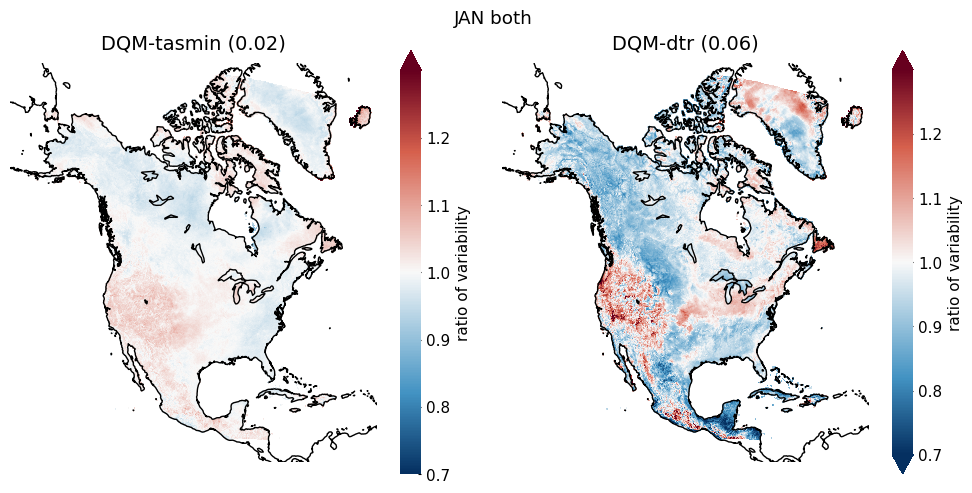

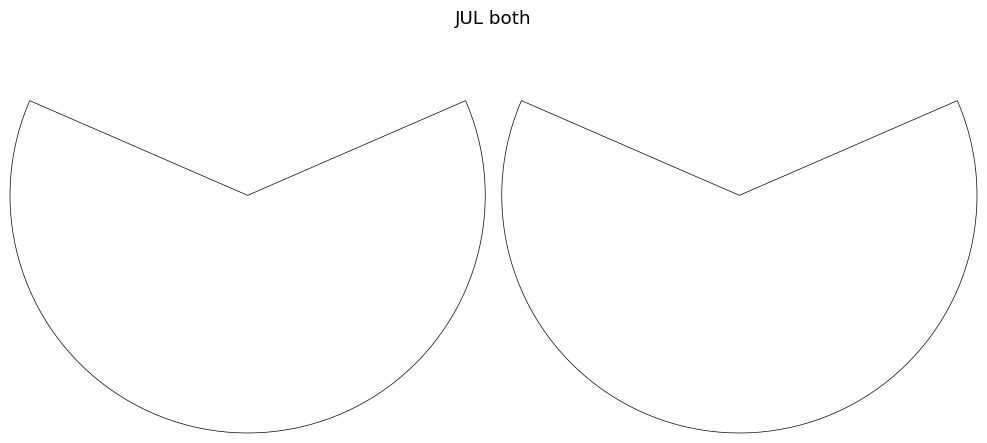

In [17]:
# both
var='tasmin'
fig, axs= plt.subplots(1,2,subplot_kw={'projection': map_proj}, figsize=(10,5))
fig.suptitle('JAN both')
fig2, axs2= plt.subplots(1,2,subplot_kw={'projection': map_proj}, figsize=(10,5))
fig2.suptitle('JUL both')

ds_ref=xr.open_zarr(f"{CONFIG['scaling']}/reference/NAM_CaSR_fullregion.zarr.zip", decode_timedelta=False)
ds_ref=ds_ref.sel(time=slice('1991','2020'))

ds_refJAN=ds_ref.sel(time=(ds_ref.time.dt.month == 1))
ds_refJUL=ds_ref.sel(time=(ds_ref.time.dt.month == 7))

std_refJAN= ds_refJAN.std('time').tasmin
std_refJUL= ds_refJUL.std('time').tasmin
Path(f"{CONFIG['arches']}/ratiovar").mkdir(parents=True, exist_ok=True)

for i,dm in enumerate(['CanESM5']):
    for j,m in enumerate(['ESPO','DQM-dtr']):
        ds=cat.search(driving_model=dm, source='CRCM5-SN', experiment='ssp370', bias_adjust_project=m, variable=var).to_dataset()
        ds=ds.sel(time=slice('1991','2020'))
        dsJAN=ds.sel(time=(ds.time.dt.month == 1))
        dsJUL=ds.sel(time=(ds.time.dt.month == 7))

        stdJAN= dsJAN.std('time').tasmin
        stdJUL= dsJUL.std('time').tasmin


        ratioJAN=stdJAN/std_refJAN
        ratioJAN.attrs['long_name']= 'adj std / CaSR std'

        path= f"{CONFIG['arches']}/ratiovar/ratiovar_both_JAN_{dm}_{m}.zarr"
        
        if not  Path(path).exists():
            xs.save_to_zarr(ratioJAN.to_dataset(name=var), path, rechunk={'rlat':-1, 'rlon':-1})
        else:
            ratioJAN = xr.open_zarr(path)[var]
            ratioJAN.attrs['long_name']= 'ratio of variability'
            del ratioJAN.attrs['units']
            fg.gridmap(ratioJAN, divergent=1, ax=axs[j], plot_kw={'vmin':0.75, 'vmax':1.25},features=fe)
            axs[j].set_title(f"{m.replace('ESPO','DQM-tasmin')} ({round(float(abs(ratioJAN-1).where(~np.isinf(ratioJAN)).mean().values),2)})")

        ratioJUL=stdJUL/std_refJUL

        path= f"{CONFIG['arches']}/ratiovar_both_JUL_{dm}_{m}.zarr"
        if not  Path(path).exists():
            xs.save_to_zarr(ratioJUL.to_dataset(name=var), path, rechunk={'rlat':-1, 'rlon':-1})
        else:
            ratioJUL = xr.open_zarr(path)[var]
            ratioJUL.attrs['long_name']= 'ratio of variability'
            del ratioJUL.attrs['units']
            fg.gridmap(ratioJUL, divergent=1, ax=axs2[j], plot_kw={'vmin':0.75, 'vmax':1.25},features=fe)
            axs2[j].set_title(f"{m.replace('ESPO','DQM-tasmin')} ({round(float(abs(ratioJUL-1).where(~np.isinf(ratioJUL)).mean().values),2)})")
fig.tight_layout()
fig2.tight_layout()
fig.savefig(f"{CONFIG['figures']}/ratiovar_CRCM5_CanESM5_both_JAN.png",bbox_inches='tight')
fig2.savefig(f"{CONFIG['figures']}/ratiovar_CRCM5_CanESM5_both_JUL.png",bbox_inches='tight')


2026-10-16 11:12:39 DEBUG    xscen.io        Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_interannual_CanESM5_ESPO.zarr.


DEBUG:xscen.io:Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_interannual_CanESM5_ESPO.zarr.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/num

2026-10-16 11:13:37 DEBUG    xscen.io        Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_interannual_CanESM5_DQM-dtr.zarr.


DEBUG:xscen.io:Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_interannual_CanESM5_DQM-dtr.zarr.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/

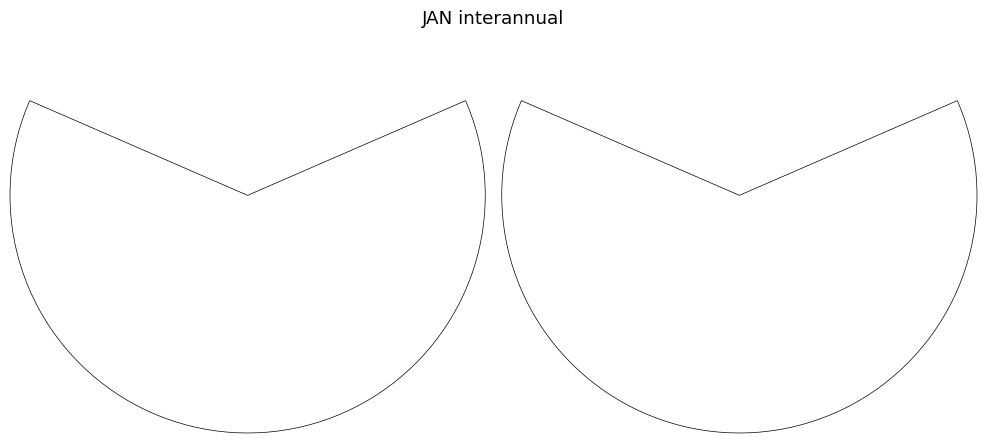

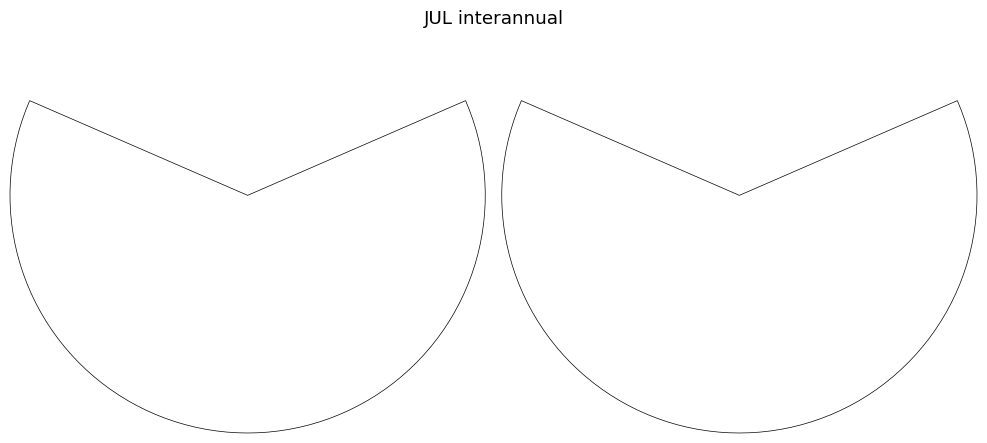

In [18]:
# interannual
var='tasmin'
fig, axs= plt.subplots(1,2,subplot_kw={'projection': map_proj}, figsize=(10,5))
fig.suptitle('JAN interannual')
fig2, axs2= plt.subplots(1,2,subplot_kw={'projection': map_proj}, figsize=(10,5))
fig2.suptitle('JUL interannual')

ds_ref=xr.open_zarr(f"{CONFIG['scaling']}/reference/NAM_CaSR_fullregion.zarr.zip", decode_timedelta=False)
ds_ref=ds_ref.sel(time=slice('1991','2020'))
if var =='pr':
    with xr.set_options(keep_attrs=True):
        ds_ref['pr']=xc.core.units.convert_units_to(ds_ref['pr'], 'mm/day', context='hydro')

ds_ref=ds_ref.resample(time='MS').mean('time')
ds_ref=xs.utils.unstack_dates(ds_ref)
std_ref=ds_ref.std('time').tasmin


for i,dm in enumerate(['CanESM5']):
    for j,m in enumerate(['ESPO','DQM-dtr']):
        ds=cat.search(driving_model=dm, source='CRCM5-SN', experiment='ssp370', bias_adjust_project=m, variable=var).to_dataset()
        ds=ds.sel(time=slice('1991','2020'))
        if var =='pr':
            with xr.set_options(keep_attrs=True):
                ds['pr']=xc.core.units.convert_units_to(ds['pr'], 'mm/day', context='hydro')
        ds=ds.resample(time='MS').mean('time')
        ds=xs.utils.unstack_dates(ds)
        std=ds.std('time').tasmin
        
        ratio=std/std_ref
        ratioJAN.attrs['long_name']= 'ratio of variability'

        path= f"{CONFIG['arches']}/ratiovar_interannual_{dm}_{m}.zarr"
        if not  Path(path).exists():
            xs.save_to_zarr(ratio.to_dataset(name=var), path, rechunk={'rlat':-1, 'rlon':-1})
        else:
            ratio = xr.open_zarr(path)[var]
            ratio.attrs['long_name']= 'ratio of variability'
            del ratio.attrs['units']
            fg.gridmap(ratio.sel(month='JAN'), divergent=1, ax=axs[j], plot_kw={'vmin':0.75, 'vmax':1.25},features=fe)
            axs[j].set_title(f"{m.replace('ESPO','DQM-tasmin')} ({round(float(abs(ratio.sel(month='JAN')-1).where(~np.isinf(ratio.sel(month='JAN'))).mean().values),2)})")
            fg.gridmap(ratio.sel(month='JUL'), divergent=1, ax=axs2[j], plot_kw={'vmin':0.75, 'vmax':1.25},features=fe)
            axs2[j].set_title(f"{m.replace('ESPO','DQM-tasmin')} ({round(float(abs(ratio.sel(month='JUL')-1).where(~np.isinf(ratio.sel(month='JUL'))).mean().values),2)})")
fig.tight_layout()
fig2.tight_layout()
fig.savefig(f"{CONFIG['figures']}/ratiovar_CRCM5_CanESM5_interannual_JAN.png",bbox_inches='tight')
fig2.savefig(f"{CONFIG['figures']}/ratiovar_CRCM5_CanESM5_interannual_JUL.png",bbox_inches='tight')


2026-10-16 11:14:29 DEBUG    xscen.io        Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_intramonthly_CanESM5_ESPO.zarr.


DEBUG:xscen.io:Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_intramonthly_CanESM5_ESPO.zarr.


2026-10-16 11:15:45 DEBUG    xscen.io        Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_intramonthly_CanESM5_DQM-dtr.zarr.


DEBUG:xscen.io:Writing ['tasmin'] for /project/ctb-frigon/julavoie/ARCHES//ratiovar_intramonthly_CanESM5_DQM-dtr.zarr.


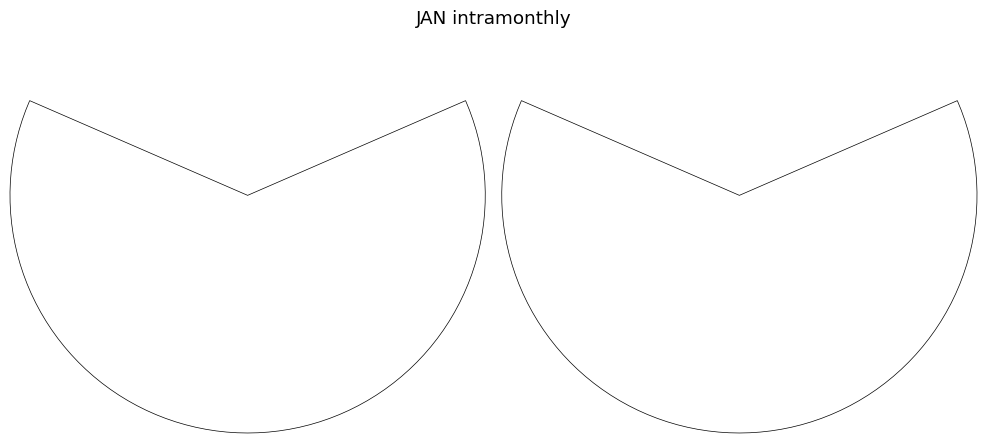

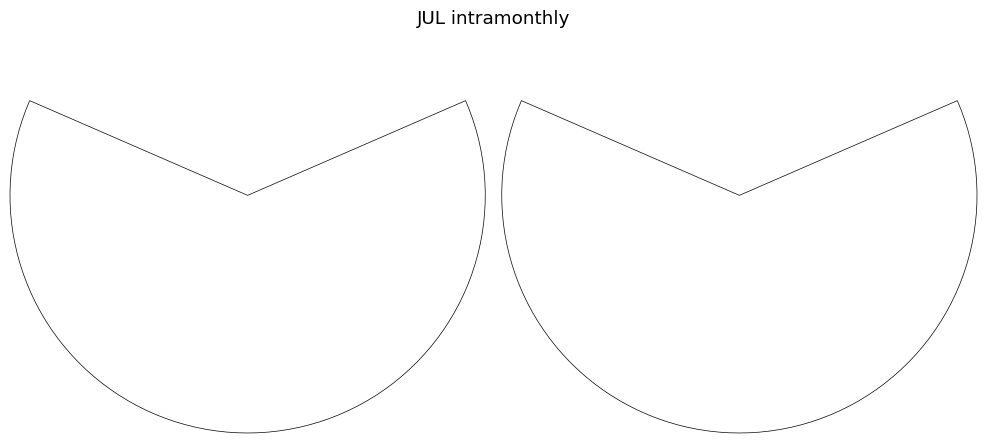

In [19]:
# intramensuel
var='tasmin'
fig, axs= plt.subplots(1,2,subplot_kw={'projection': map_proj}, figsize=(10,5))
fig.suptitle('JAN intramonthly')
fig2, axs2= plt.subplots(1,2,subplot_kw={'projection': map_proj}, figsize=(10,5))
fig2.suptitle('JUL intramonthly')

ds_ref=xr.open_zarr(f"{CONFIG['scaling']}/reference/NAM_CaSR_fullregion.zarr.zip", decode_timedelta=False)
ds_ref=ds_ref.sel(time=slice('1991','2020'))

ds_ref=ds_ref.resample(time='MS').var('time')
ds_ref=xs.utils.unstack_dates(ds_ref)
std_ref=np.sqrt(ds_ref.mean('time').tasmin)

for i,dm in enumerate(['CanESM5']):
    for j,m in enumerate(['ESPO','DQM-dtr']):
        ds=cat.search(driving_model=dm, source='CRCM5-SN', experiment='ssp370', bias_adjust_project=m, variable=var).to_dataset()
        ds=ds.sel(time=slice('1991','2020'))

        ds=ds.resample(time='MS').var('time')
        ds=xs.utils.unstack_dates(ds)
        std=np.sqrt(ds.mean('time').tasmin)
        
        ratio=std/std_ref
        ratio.attrs['long_name']= 'adj std / CaSR std'

        path= f"{CONFIG['arches']}/ratiovar_intramonthly_{dm}_{m}.zarr"
        if not  Path(path).exists():
            xs.save_to_zarr(ratio.to_dataset(name=var), path, rechunk={'rlat':-1, 'rlon':-1})
        else:
            ratio = xr.open_zarr(path)[var]
            ratio.attrs['long_name']= 'ratio of variability'
            del ratio.attrs['units']
            fg.gridmap(ratio.sel(month='JAN'), divergent=1, ax=axs[j], plot_kw={'vmin':0.75, 'vmax':1.25},features=fe)
            axs[j].set_title(f"{m.replace('ESPO','DQM-tasmin')} ({round(float(abs(ratio.sel(month='JAN')-1).where(~np.isinf(ratio.sel(month='JAN'))).mean().values),2)})")
            fg.gridmap(ratio.sel(month='JUL'), divergent=1, ax=axs2[j], plot_kw={'vmin':0.75, 'vmax':1.25},features=fe)
            axs2[j].set_title(f"{m.replace('ESPO','DQM-tasmin')} ({round(float(abs(ratio.sel(month='JUL')-1).where(~np.isinf(ratio.sel(month='JUL'))).mean().values),2)})")
fig.tight_layout()
fig2.tight_layout()
fig.savefig(f"{CONFIG['figures']}/ratiovar_CRCM5_CanESM5_intramontly_JAN.png",bbox_inches='tight')
fig2.savefig(f"{CONFIG['figures']}/ratiovar_CRCM5_CanESM5_intramontly_JUL.png",bbox_inches='tight')


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2

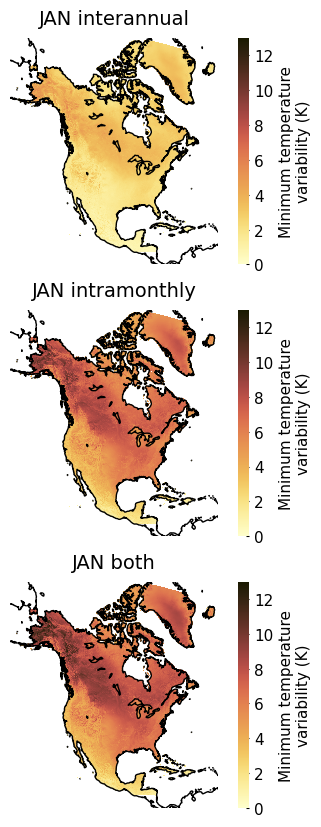

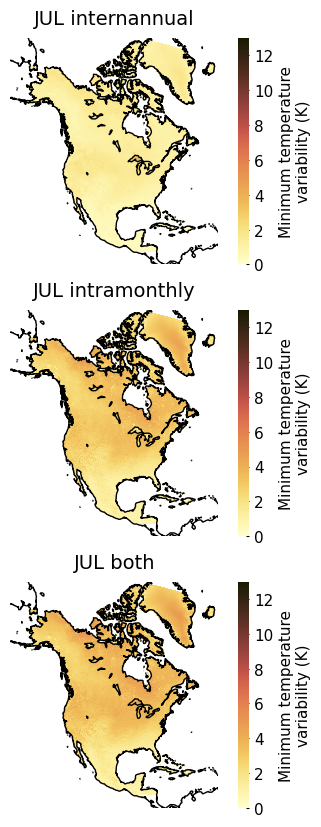

In [20]:
# for casr


var='tasmin'
fig, axs= plt.subplots(3,1,subplot_kw={'projection': map_proj}, figsize=(5,10))
fig2, axs2= plt.subplots(3,1,subplot_kw={'projection': map_proj}, figsize=(5,10))
plot_kw={'vmin':0,'vmax':13}

ds_ref=xr.open_zarr(f"{CONFIG['scaling']}/reference/NAM_CaSR_fullregion.zarr.zip", decode_timedelta=False)
ds_ref=ds_ref.sel(time=slice('1991','2020'))

ds_ref['tasmin'].attrs['long_name']= 'Minimum temperature variability'


#interannual
ds_refA=ds_ref.resample(time='MS').mean('time')
ds_refA=xs.utils.unstack_dates(ds_refA)
std_refA=ds_refA.std('time').tasmin

fg.gridmap(std_refA.sel(month='JAN'),  ax=axs[0],features=fe, plot_kw=plot_kw)
fg.gridmap(std_refA.sel(month='JUL'), ax=axs2[0],features=fe, plot_kw=plot_kw)
axs[0].set_title('JAN interannual')
axs2[0].set_title('JUL internannual')

#intramensuel
ds_refM=ds_ref.resample(time='MS').var('time')
ds_refM=xs.utils.unstack_dates(ds_refM)
std_refM=np.sqrt(ds_refM.mean('time').tasmin)
fg.gridmap(std_refM.sel(month='JAN'),  ax=axs[1],features=fe, plot_kw=plot_kw)
fg.gridmap(std_refM.sel(month='JUL'), ax=axs2[1],features=fe, plot_kw=plot_kw)
axs[1].set_title('JAN intramonthly')
axs2[1].set_title('JUL intramonthly')


# both
ds_refBJAN=ds_ref.sel(time=(ds_ref.time.dt.month == 1))
ds_refBJUL=ds_ref.sel(time=(ds_ref.time.dt.month == 7))

std_refBJAN= ds_refBJAN.std('time').tasmin
std_refBJUL= ds_refBJUL.std('time').tasmin

fg.gridmap(std_refBJAN,  ax=axs[2],features=fe, plot_kw=plot_kw)
fg.gridmap(std_refBJUL, ax=axs2[2],features=fe, plot_kw=plot_kw)
axs[2].set_title('JAN both')
axs2[2].set_title('JUL both')
fig.savefig(f"{CONFIG['figures']}/var_CaSR_JAN.png",bbox_inches='tight')
fig2.savefig(f"{CONFIG['figures']}/var_CaSR_JUL.png",bbox_inches='tight')


## VALUE

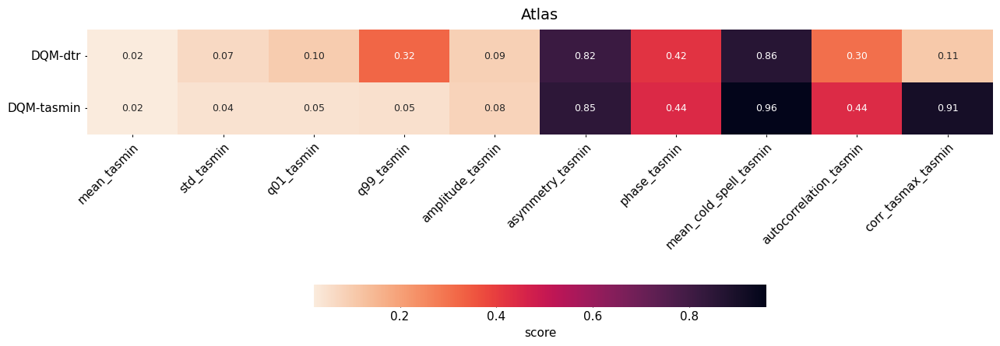

In [21]:
# gab first version of heatmap


ordered_properties=["mean_tasmin",  'std_tasmin',"q01_tasmin","q99_tasmin",'amplitude_tasmin','asymmetry_tasmin', 
 'phase_tasmin',  'mean_cold_spell_tasmin', 'autocorrelation_tasmin',  "corr_tasmax_tasmin", ]

prop_ref= xr.open_zarr(f"{CONFIG['espo']}/diagnostics/CaSR/NAM/Atlas/ref-prop.zarr.zip", decode_timedelta=False)
prop_ref_std=prop_ref.std() # spatial std

all_sims=[]
all_mets=[]
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)


#adjusted
for m in ['dqm-dtr','espo']:
    sims=[]
    for sim_id in ids:
        if 'ssp370' in sim_id:
            #sim_id=sim_id.replace('ESPO_CaSR_','').replace("r1_NAM","r1_NAM-12")
            meas_adj= xr.open_zarr(f"{CONFIG[m]}/diagnostics/CaSR/NAM/Atlas/{sim_id}/{sim_id}_NAM_Atlas_scen-meas.zarr.zip", decode_timedelta=False)
            meas_adj_mean= abs(meas_adj).mean() # spatial mean
            meas_adj_mean_std=meas_adj_mean/prop_ref_std
            sims.append(meas_adj_mean_std.expand_dims(realization=[sim_id]))
            all_sims.append(meas_adj_mean_std.expand_dims(realization=[f"{m}_{sim_id}"]))
    ds_sims=xr.concat(sims, dim='realization').mean('realization')
    all_mets.append(ds_sims.expand_dims(realization=[m.replace('scaling','Scaling').replace('espo','DQM-tasmin').replace('dqm-dtr','DQM-dtr')]))


ds_all=xr.concat(all_sims, dim='realization').to_array(dim='properties').T
ds_all=ds_all.sel(properties=ordered_properties)
# ax=fg.heatmap(ds_all,plot_kw={'annot':True, }, fig_kw={'figsize':(15,5)},divergent=0, cmap='RdBu_r')
# ax.set_title('Atlas')

    
ds_mets=xr.concat(all_mets, dim='realization')   
# put props in dims, instead of var
ds_mets=ds_mets.to_array(dim='properties').T

ds_mets=ds_mets.sel(properties=ordered_properties)

ds_mets.attrs['long_name']='score'
ax=fg.heatmap(ds_mets,plot_kw={'annot':True,'fmt':".2f",'annot_kws':{"size": 9},'cbar_kws':{"orientation": "horizontal","pad": 0.5,"shrink": 0.5 }},
              fig_kw={'figsize':(15,5)}, cmap='rocket_r')#RdBu_r
ax.set_title('Atlas')
ax.set_ylabel('')
ax.set_xlabel('')

texts = ax.texts



plt.savefig(f"{CONFIG['figures']}/score_dtrvstasmin.pdf",bbox_inches='tight')




/tmp/ipykernel_1516757/3249649762.py:65: UserWarning: Colormap warning: Variable group not found. Use the cmap argument.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.
/tmp/ipykernel_1516757/3249649762.py:134: UserWarning: This figure includes Axes that are not 

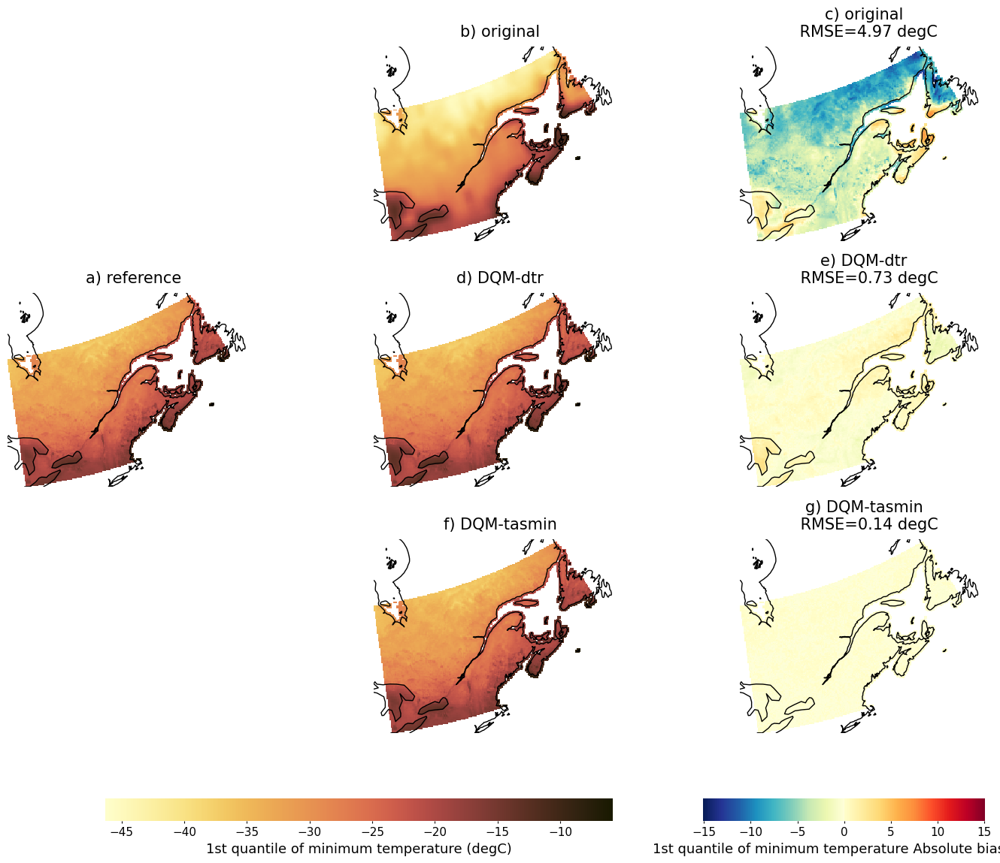

In [22]:
var='q01_tasmin'
prop_ref=xr.open_zarr(f"{CONFIG['dqm-dtr']}/diagnostics/CaSR/NAM/Atlas/ref-prop.zarr.zip")[var]
prop_sim=xr.open_zarr(f"{CONFIG['dqm-dtr']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_sim-prop.zarr.zip")[var]
meas_sim_prop=xr.open_zarr(f"{CONFIG['dqm-dtr']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_sim-meas.zarr.zip")[var]
prop_scen1=xr.open_zarr(f"{CONFIG['dqm-dtr']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_scen-prop.zarr.zip")[var]
meas_scen1_prop=xr.open_zarr(f"{CONFIG['dqm-dtr']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_scen-meas.zarr.zip")[var]
prop_scen2=xr.open_zarr(f"{CONFIG['espo']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_scen-prop.zarr.zip")[var]
meas_scen2_prop=xr.open_zarr(f"{CONFIG['espo']}/diagnostics/CaSR/NAM/Atlas/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12/CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM-12_NAM_Atlas_scen-meas.zarr.zip")[var]

maps2('DQM-dtr', 'DQM-tasmin', prop_ref, prop_sim, prop_scen1, prop_scen2, meas_sim_prop, meas_scen1_prop, meas_scen2_prop);


/tmp/ipykernel_1516757/4116703672.py:45: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/tmp/ipykernel_1516757/4116703672.py:45: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
/tmp/ipykernel_1516757/4116703672.py:45: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='o

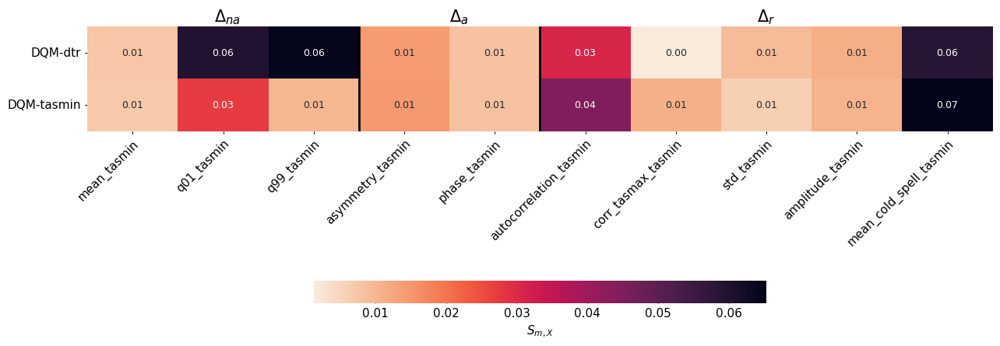

In [23]:
# gab first version of heatmap



ordered_properties=[
    "mean_tasmin", "q01_tasmin","q99_tasmin",
    'asymmetry_tasmin',       'phase_tasmin',  
        'autocorrelation_tasmin', "corr_tasmax_tasmin",'std_tasmin','amplitude_tasmin', 'mean_cold_spell_tasmin',
                   ]

prop_ref= xr.open_zarr(f"{CONFIG['espo']}/diagnostics/CaSR/NAM/Atlas/ref-prop.zarr.zip", decode_timedelta=False)
prop_ref_std=prop_ref.std() # spatial std

all_sims=[]
all_mets=[]
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)


#adjusted
for m in ['dqm-dtr','espo']:
    sims=[]

    ref= xr.open_zarr(f"{CONFIG[m]}/diagnostics/CaSR/NAM/Atlas/ref-prop.zarr.zip", decode_timedelta=False)
    for sim_id in ids:
        if 'ssp370' in sim_id:
            ds= xr.open_zarr(f"{CONFIG[m]}/diagnostics/CaSR/NAM/Atlas/{sim_id}/{sim_id}_NAM_Atlas_scen-prop.zarr.zip", decode_timedelta=False)
    
            
            # code de gab
            for v in [v for v in ds.data_vars if "asymmetry" in v]:
                ds[v].attrs["units"] = ""
                ref[v].attrs["units"] = ""
    
            # compute_diff modify to use meas instead of prop
            abs_v = [v for v in ds.data_vars if ds[v].attrs.get("units", "") == "" and 'phase' not in v]
            temp_v = [v for v in ds.data_vars if (ds[v].attrs.get("units", "") in ["degC"]) and any(prefix in v for prefix in ["mean", "q01", "q50", "q95", "q99", "q995"])]
            phase_v = [v for v in ds.data_vars if 'phase' in v]
            other_v = [v for v in ds.data_vars if v not in abs_v + temp_v + phase_v]
        
            ds_diff_abs = ds[abs_v] - ref[abs_v]
            if len(temp_v) > 0:
                for variable in ["tasmin", "tasmax"]:
                    var_temp_v = [v for v in temp_v if variable in v]
                    ds_diff_temp = ((ds[var_temp_v] - ref[var_temp_v]) / (ref[f"std_{variable}"]))
                    ds_diff_abs = xr.merge([ds_diff_abs, ds_diff_temp])
            ds_diff_rel = (ds[other_v] - ref[other_v]) / ref[other_v].clip(min=0.00001)
    
            # circular bias 
            ds_diff_phase=   (ds[phase_v] - ref[phase_v]) % 365
            ds_diff_phase = ds_diff_phase.where(ds_diff_phase <= 365 / 2, 365 - ds_diff_phase)  # when condition false, replace by 2nd arg
            ds_diff_phase = ds_diff_phase.where(ref[phase_v] >= ds[phase_v], ds_diff_phase * -1)
            ds_diff_phase = ds_diff_phase/365 # normalize
        
            out = xr.merge([ds_diff_abs, ds_diff_rel, ds_diff_phase], compat="no_conflicts")
    
            
            meas_adj_mean= abs(out).mean() # spatial mean
            sims.append(meas_adj_mean.expand_dims(realization=[sim_id]))
            all_sims.append(meas_adj_mean.expand_dims(realization=[f"{m}_{sim_id}"]))
    ds_sims=xr.concat(sims, dim='realization').mean('realization')
    all_mets.append(ds_sims.expand_dims(realization=[m.replace('scaling','Scaling').replace('espo','DQM-tasmin').replace('dqm-dtr','DQM-dtr')]))


ds_all=xr.concat(all_sims, dim='realization').to_array(dim='properties').T
ds_all=ds_all.sel(properties=ordered_properties)
# ax=fg.heatmap(ds_all,plot_kw={'annot':True, }, fig_kw={'figsize':(15,5)},divergent=0, cmap='RdBu_r')
# ax.set_title('Atlas')

    
ds_mets=xr.concat(all_mets, dim='realization')   
# put props in dims, instead of var
ds_mets=ds_mets.to_array(dim='properties').T

ds_mets=ds_mets.sel(properties=ordered_properties)

ds_mets.attrs['long_name']=r"$S_{m,X}$"
ax=fg.heatmap(ds_mets,plot_kw={'annot':True,'fmt':".2f",'annot_kws':{"size": 9},'cbar_kws':{"orientation": "horizontal","pad": 0.5,"shrink": 0.5 }},
              fig_kw={'figsize':(15,5)}, cmap='rocket_r')#RdBu_r
#ax.set_title('Atlas')
ax.set_ylabel('')
ax.set_xlabel('')

texts = ax.texts
ax.axvline(x=3, linewidth=2, color="black")
ax.axvline(x=5, linewidth=2, color="black")
ax.text(1.4, -0.1, r"$\Delta_{na}$", fontsize=15)
ax.text(4, -0.1, r"$\Delta_{a}$", fontsize=15)
ax.text(7.4,-0.1, r"$\Delta_{r}$", fontsize=15)


plt.savefig(f"{CONFIG['figures']}/score_dtrvstasmin.pdf",bbox_inches='tight')




# Basin average

In [24]:
# # all diff together
# lgdfs = []
# files = glob.glob(f"{CONFIG['data']}/region_shapefiles/*.shp")
# for f in files:
#     lgdfs.append(gpd.read_file(f))
# gdfsa = pd.concat(lgdfs)

# bbox = shapely.geometry.box(-83, 42, -55, 53)
# gdfs6 = gpd.read_file(f"{CONFIG['data']}/hydrobasins/hybas_na_lev06_v1c.shp")
# gdfs6 = gdfs6[gdfs6.geometry.within(bbox)]  # in atlas region
# gdfs6 = gdfs6[gdfs6["SUB_AREA"] > 200]  # bigger than one grid point
# tol = 0.01

atlas
lev06
atlas
lev06
atlas
lev06
atlas
lev06
atlas
lev06
atlas
lev06


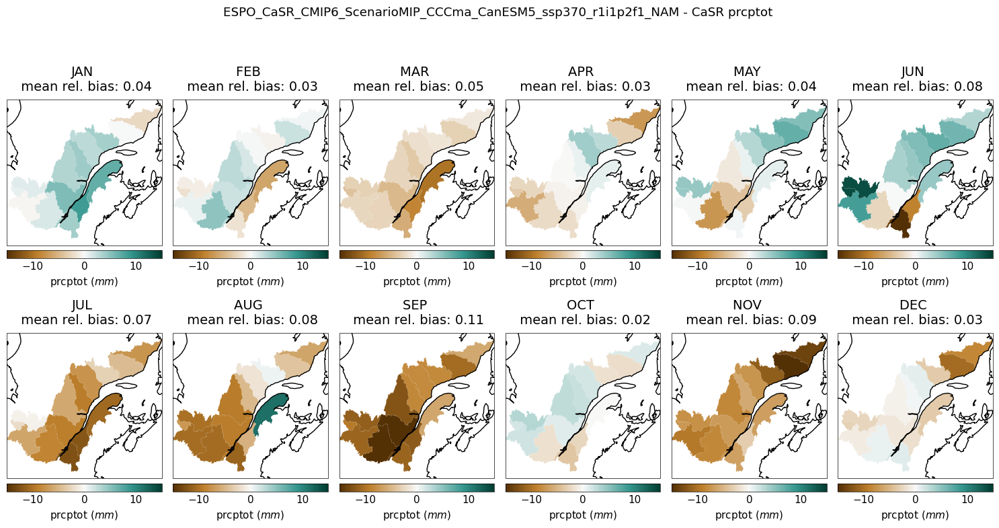

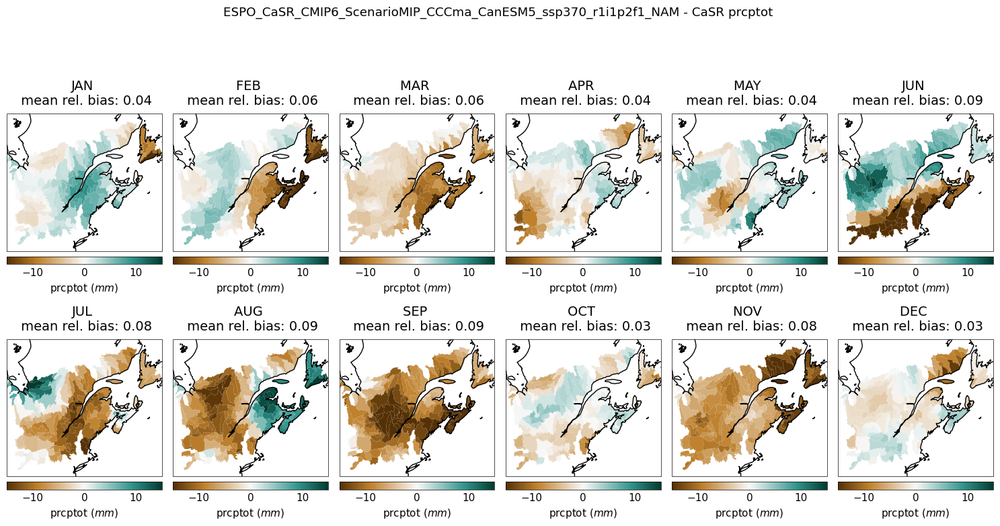

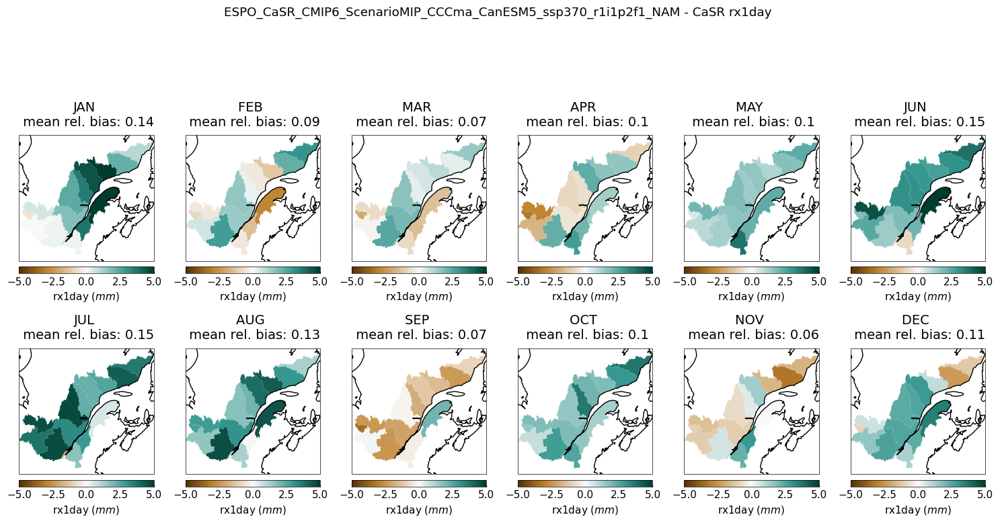

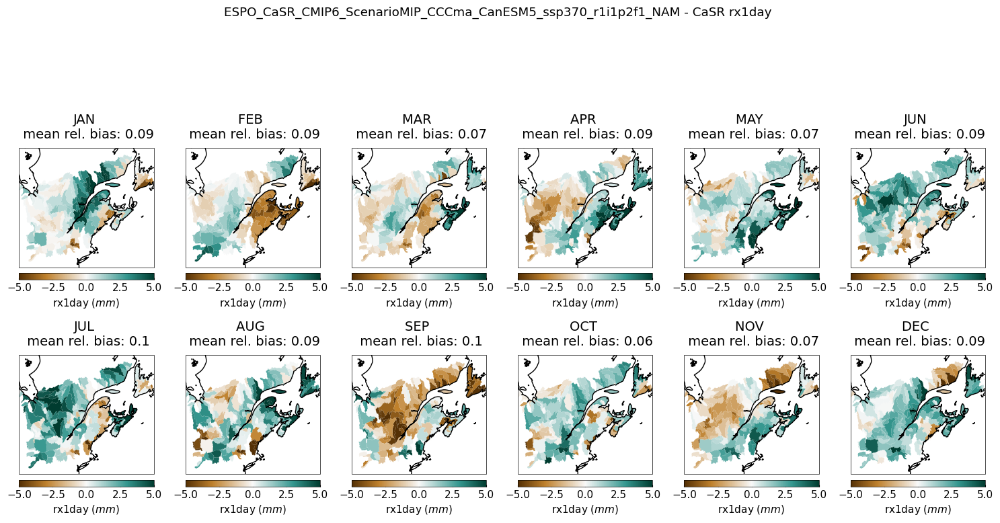

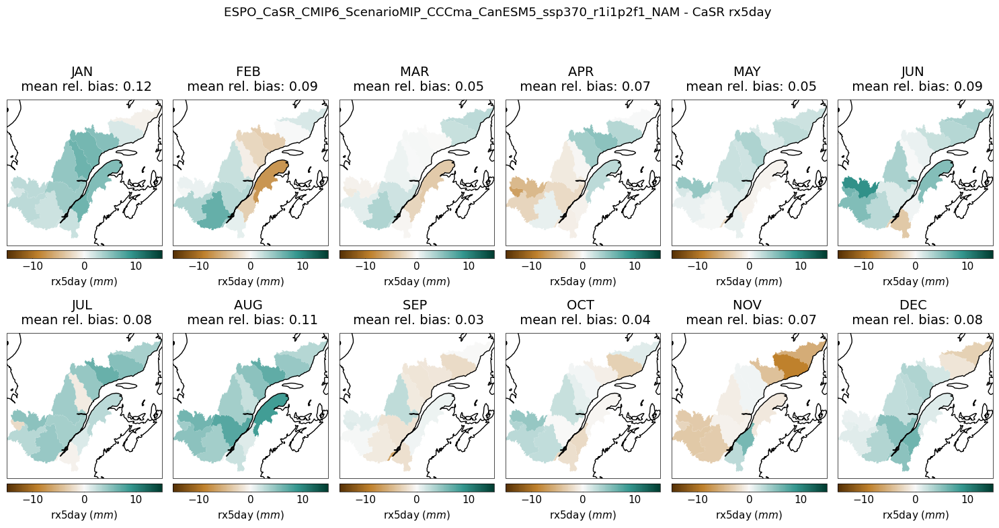

...

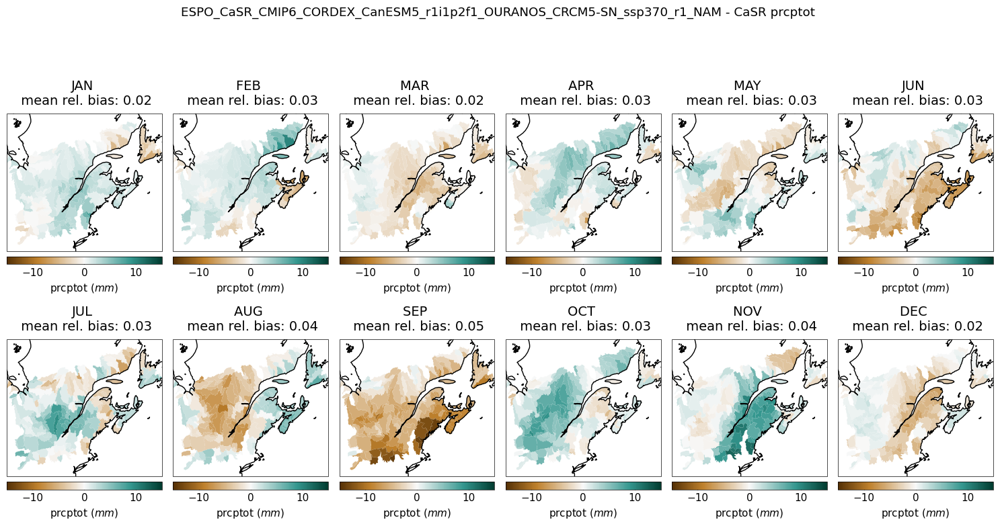

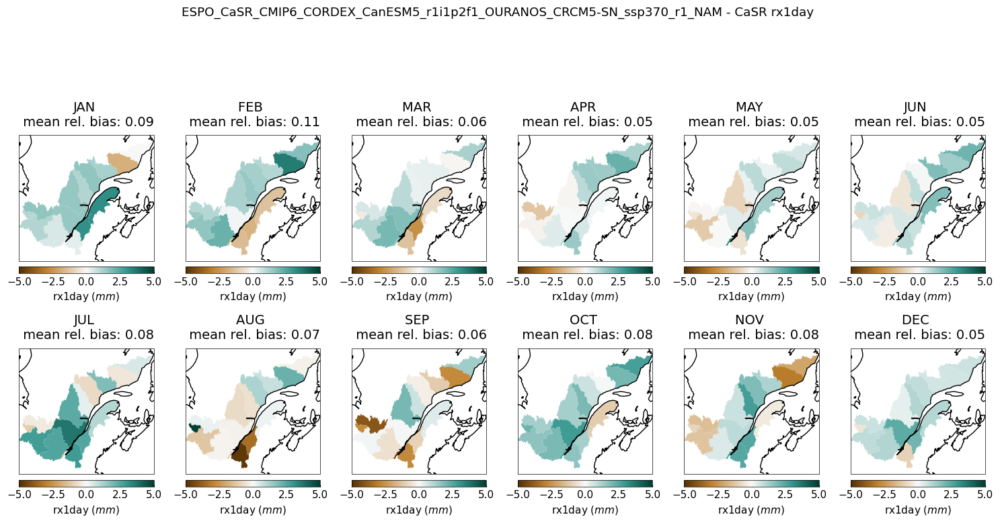

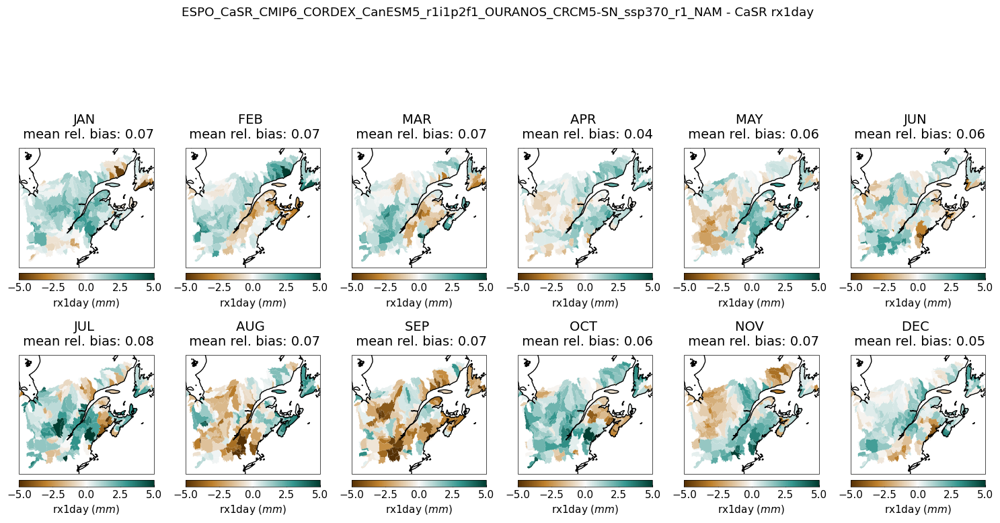

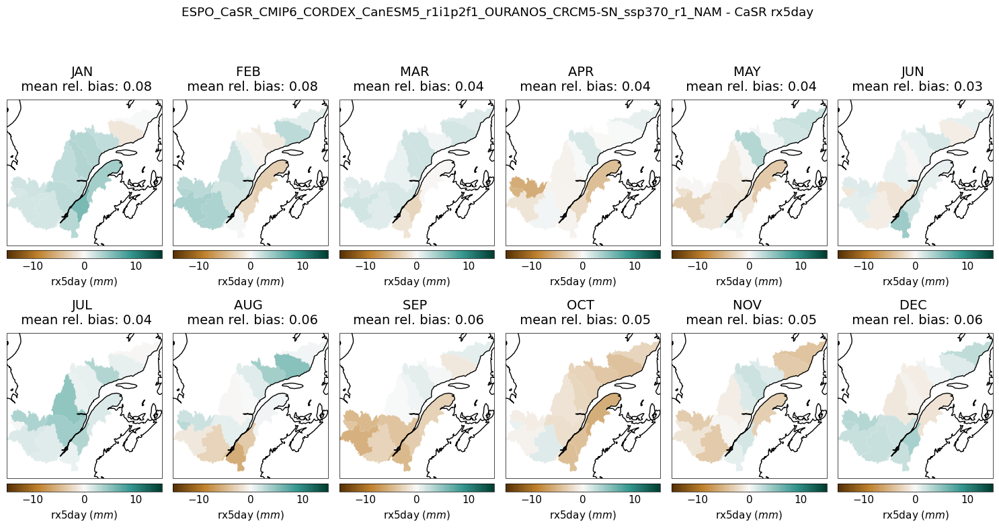

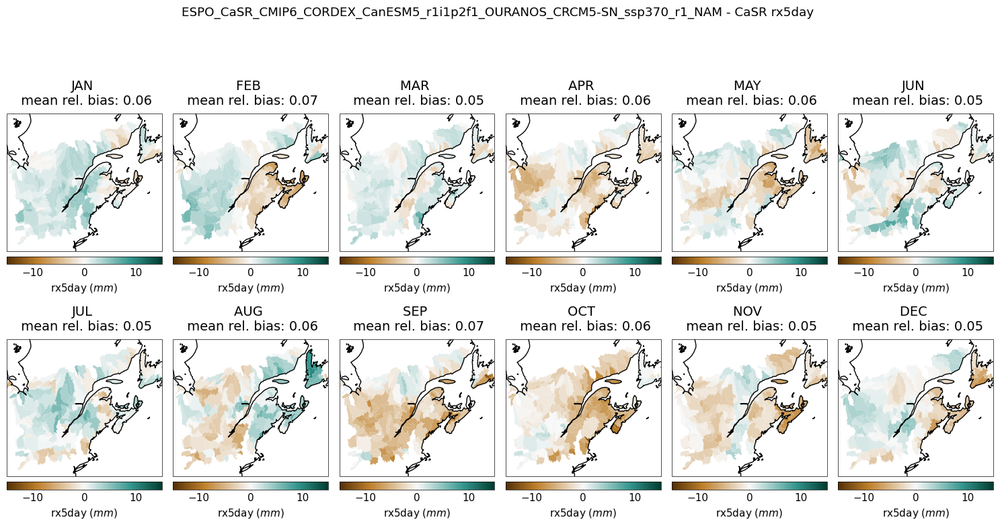

In [25]:
# vmums={'prcptot':15, 'rx1day':5,'rx5day':15}

# for sim_id in ['ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r1i1p2f1_NAM',
#                'ESPO_CaSR_CMIP6_CORDEX_CanESM5_r1i1p2f1_OURANOS_CRCM5-SN_ssp370_r1_NAM']:

#     for var in ['prcptot', 'rx1day','rx5day']:
#         for gdfs, geoname in zip([gdfsa, gdfs6], ["atlas", "lev06"], strict=True):
#             print(geoname)
#             refs=[]
#             adjs=[]
#             df_ref=pd.read_csv(f"{CONFIG['arches']}/bilan_pr/bassinavg_{geoname}_CaSR.csv")
#             df_adj= pd.read_csv(f"{CONFIG['arches']}/bilan_pr/bassinavg_{geoname}_{sim_id}.csv")
#             df_ref['month'] = pd.to_datetime(df_ref['time']).dt.strftime('%b').str.upper()
#             df_ref['monthnum'] = pd.to_datetime(df_ref['time']).dt.month
#             df_adj['month'] = pd.to_datetime(df_adj['time']).dt.strftime('%b').str.upper()
#             df_adj['monthnum'] = pd.to_datetime(df_adj['time']).dt.month
#             for j in range(len(gdfs)):
#                 cur_ref=df_ref[df_ref['basin_id']==j]
#                 cur_ref=cur_ref.groupby(['month'], as_index=False)[[var]].mean()
#                 refs.append(cur_ref)
        
#                 cur=df_adj[df_adj['basin_id']==j]
#                 cur=cur.groupby(['month'], as_index=False)[[var]].mean()
#                 adjs.append(cur)
            
            
                    
                
        
#             fig, axs = plt.subplots(2,6, figsize=(15,8), subplot_kw={'projection':ccrs.LambertConformal()})
#             axs=np.ravel(axs)
#             fig.suptitle(f'{sim_id} - CaSR {var} ')
        
#             for i, month in enumerate(['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN',
#                'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']):
#                 df=gdfs.copy()
#                 df['ref']= [ float(x.loc[x['month']==month][var].iloc[0]) for x in refs]
#                 df['ref']=df['ref'].astype(float)
#                 df['adj']= [ float(x.loc[x['month']==month][var].iloc[0]) for x in adjs]
#                 df['adj']=df['adj'].astype(float)
        
        
#                 df['diff']=df['adj']-df['ref']
#                 df['relbias']=abs((df['adj']-df['ref'])/df['ref'])
        
        
        
#                 fg.gdfmap(df, 'diff', cmap='prec_div',projection=ccrs.LambertConformal(), features=['coastline'],
#                       ax=axs[i],
#                      frame=True, plot_kw=dict(legend_kwds={"label": var +r" ($mm$)"},
#                                               vmin=-vmums[var], vmax=vmums[var]
#                                              ))
        
#                 axs[i].set_title(f"{month} \n mean rel. bias: {round(df['relbias'].mean(),2)}")
        
#                 # #FIXME: fix until figanos>0.6.0
#                 # for ax in axs.ravel():
#                 #     ax.spines['geo'].set_visible(False)
        
#                 fig.tight_layout()
#                 plt.savefig(f"{CONFIG['figures']}/basinavg_{var}_{geoname}_timemean_map_{sim_id}.png",bbox_inches='tight')
        
    


atlas
lev06
atlas
lev06
atlas
lev06


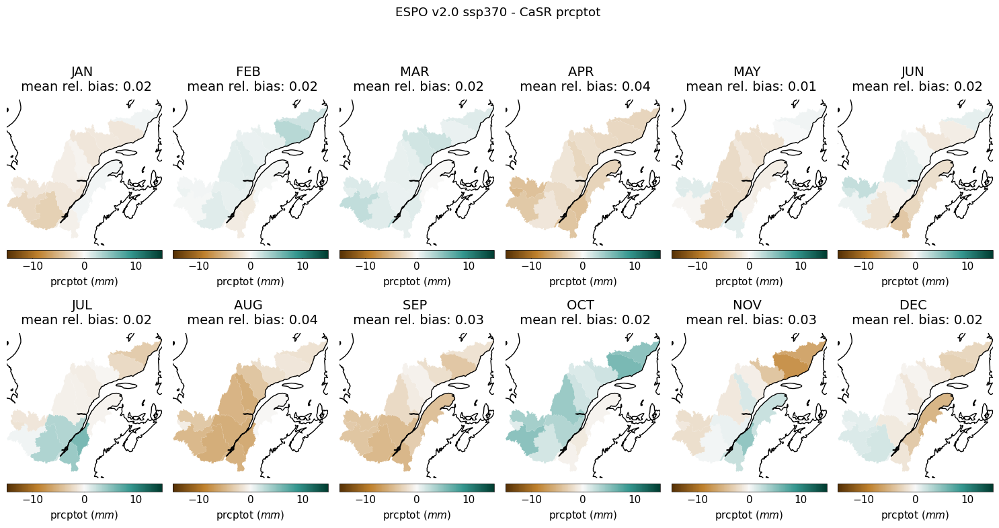

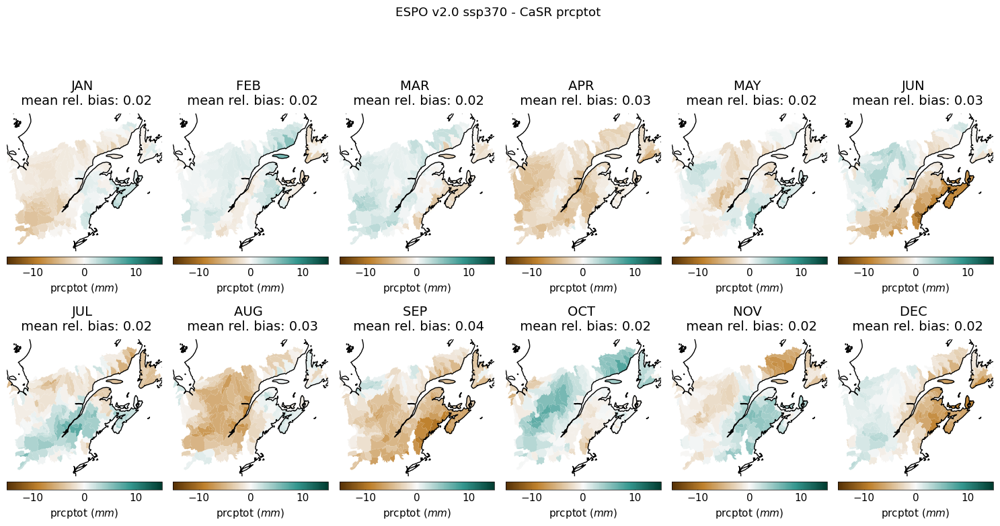

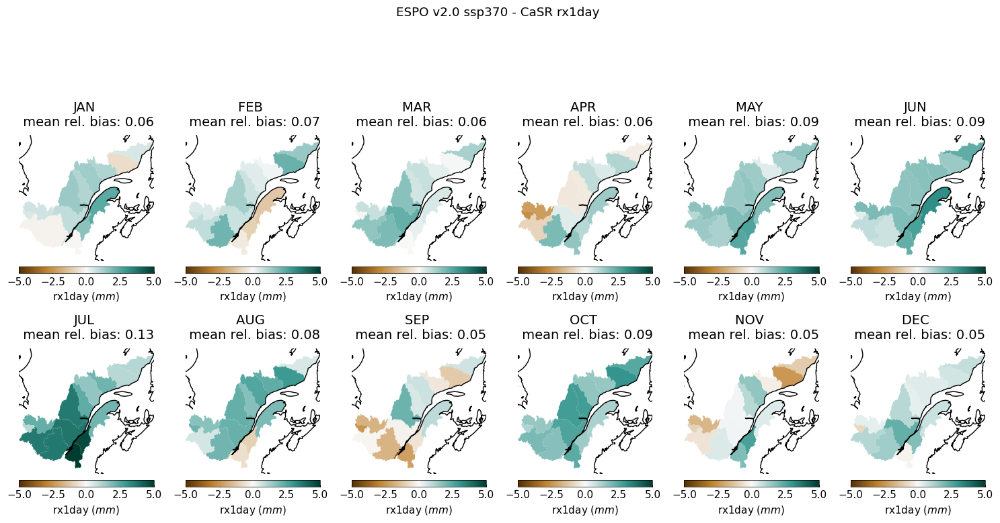

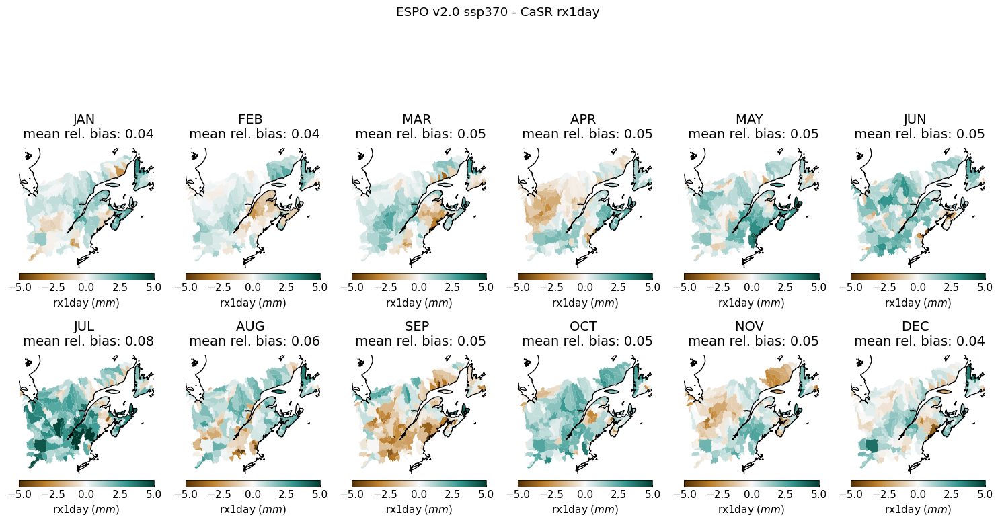

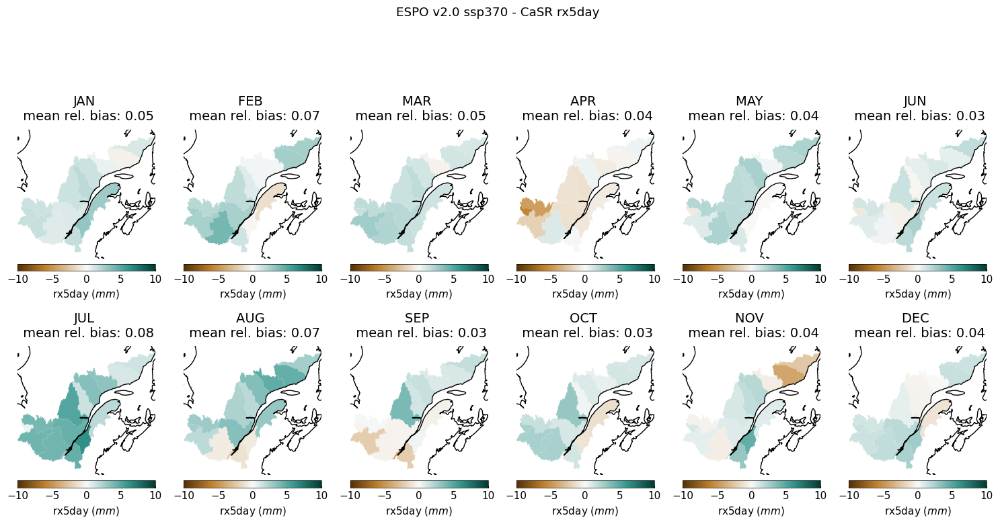

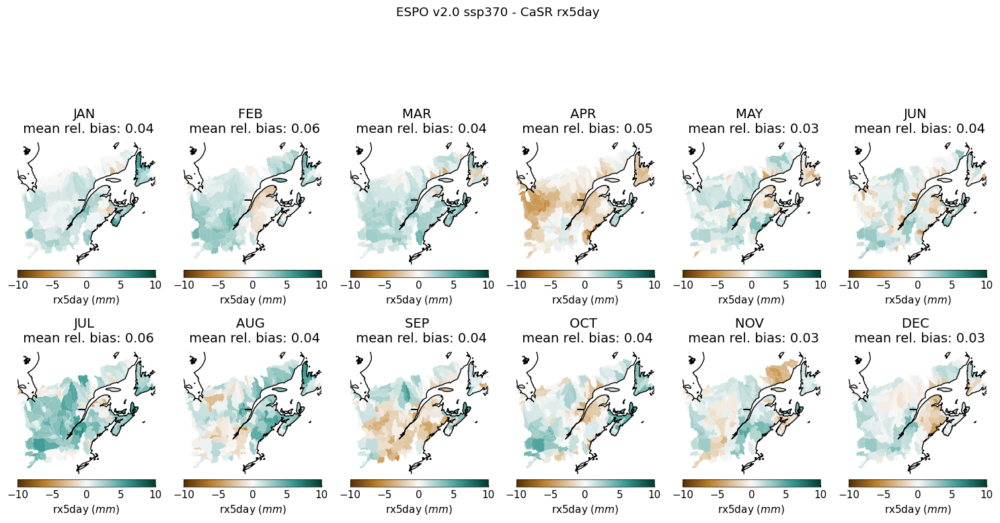

In [26]:
# #ensemble mean
# vmums={'prcptot':15, 'rx1day':5,'rx5day':10}



# for var in ['prcptot','rx1day','rx5day']:
#     for gdfs, geoname in zip([gdfsa, gdfs6], ["atlas", "lev06"], strict=True):
# # for var in ['prcptot',]:
# #     for gdfs, geoname in zip([gdfsa], ["atlas",], strict=True):

#             print(geoname)
#             refs=[]
#             adjs=[]
#             df_ref=pd.read_csv(f"{CONFIG['arches']}/bilan_pr/bassinavg_{geoname}_CaSR.csv")
#             df_ref['month'] = pd.to_datetime(df_ref['time']).dt.strftime('%b').str.upper()
#             df_ref['monthnum'] = pd.to_datetime(df_ref['time']).dt.month
#             # df_adj['month'] = pd.to_datetime(df_adj['time']).dt.strftime('%b').str.upper()
#             # df_adj['monthnum'] = pd.to_datetime(df_adj['time']).dt.month
#             for j in range(len(gdfs)):
#                 cur_ref=df_ref[df_ref['basin_id']==j]
#                 cur_ref=cur_ref.groupby(['month'], as_index=False)[[var]].mean()
#                 refs.append(cur_ref)

#                 cur=pd.read_csv(
#                     f"{CONFIG['arches']}/bilan_pr_ens/bassinavg_{geoname}_{j}_{var}.csv"
#                 )
#                 adjs.append(cur)
            
            
                    
                
        
#             fig, axs = plt.subplots(2,6, figsize=(15,8), subplot_kw={'projection':ccrs.LambertConformal()})
#             axs=np.ravel(axs)
#             fig.suptitle(f'ESPO v2.0 ssp370 - CaSR {var} ')
        
#             for i, month in enumerate(['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN',
#                'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']):
#                 df=gdfs.copy()
#                 df['ref']= [ float(x.loc[x['month']==month][var].iloc[0]) for x in refs]
#                 df['ref']=df['ref'].astype(float)
#                 df['adj']= [ float(x.loc[x['month']==month][var].iloc[0]) for x in adjs]
#                 df['adj']=df['adj'].astype(float)
        
        
#                 df['diff']=df['adj']-df['ref']
#                 df['relbias']=abs((df['adj']-df['ref'])/df['ref'])
        
        
#                 fg.gdfmap(df, 'diff', cmap='prec_div',projection=ccrs.LambertConformal(), features=['coastline'],
#                       ax=axs[i],
#                      frame=True, plot_kw=dict(legend_kwds={"label": var +r" ($mm$)"},
#                                               vmin=-vmums[var], vmax=vmums[var]
#                                              ))
        
#                 axs[i].set_title(f"{month} \n mean rel. bias: {round(df['relbias'].mean(),2)}")
        
#                 #FIXME: fix until figanos>0.6.0
#                 for ax in axs.ravel():
#                     ax.spines['geo'].set_visible(False)
        
#                 fig.tight_layout()
#                 plt.savefig(f"{CONFIG['figures']}/basinavg_{var}_{geoname}_timemean_map_ens.png",bbox_inches='tight')
        
    


atlas
atlas


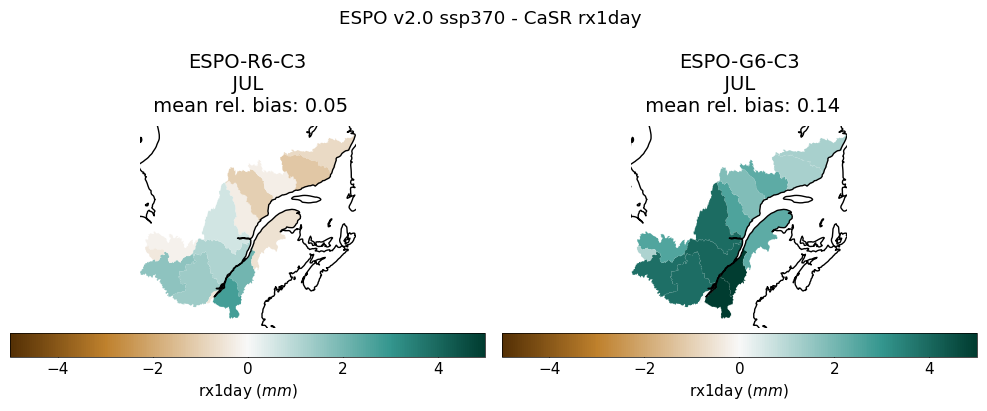

In [27]:
# #GCM vs RCM
# vmums={'prcptot':15, 'rx1day':5,'rx5day':10}




# for var in ['rx1day']:
#     fig, axs = plt.subplots(1,2, figsize=(10,4), subplot_kw={'projection':ccrs.LambertConformal()})

#     for gdfs, geoname in zip([gdfsa], ["atlas",], strict=True):
#         for i, ens in enumerate(['RCM','GCM']):
    
#                 print(geoname)
#                 refs=[]
#                 adjs=[]
#                 df_ref=pd.read_csv(f"{CONFIG['arches']}/bilan_pr/bassinavg_{geoname}_CaSR.csv")
#                 df_ref['month'] = pd.to_datetime(df_ref['time']).dt.strftime('%b').str.upper()
#                 df_ref['monthnum'] = pd.to_datetime(df_ref['time']).dt.month
#                 # df_adj['month'] = pd.to_datetime(df_adj['time']).dt.strftime('%b').str.upper()
#                 # df_adj['monthnum'] = pd.to_datetime(df_adj['time']).dt.month
#                 for j in range(len(gdfs)):
#                     cur_ref=df_ref[df_ref['basin_id']==j]
#                     cur_ref=cur_ref.groupby(['month'], as_index=False)[[var]].mean()
#                     refs.append(cur_ref)
#                     cur=pd.read_csv(
#                         f"{CONFIG['arches']}/bilan_pr_ens/{ens}_bassinavg_{geoname}_{j}_{var}.csv"
#                     )
#                     adjs.append(cur)
                
                
                        
                    


#                 #JULY
#                 month='JUL'

#                 df=gdfs.copy()
#                 df['ref']= [ float(x.loc[x['month']==month][var].iloc[0]) for x in refs]
#                 df['ref']=df['ref'].astype(float)
#                 df['adj']= [ float(x.loc[x['month']==month][var].iloc[0]) for x in adjs]
#                 df['adj']=df['adj'].astype(float)
        
        
#                 df['diff']=df['adj']-df['ref']
#                 df['relbias']=abs((df['adj']-df['ref'])/df['ref'])

#                 fg.gdfmap(df, 'diff', cmap='prec_div',projection=ccrs.LambertConformal(), features=['coastline'],
#                           ax=axs[i],
#                          frame=True, plot_kw=dict(legend_kwds={"label": var +r" ($mm$)"},
#                                                   vmin=-vmums[var], vmax=vmums[var]
#                                                  ))
#                 ensname=ens.replace('RCM','ESPO-R6-C3').replace('GCM','ESPO-G6-C3')
#                 axs[i].set_title(f"{ensname}\n {month} \n mean rel. bias: {round(df['relbias'].mean(),2)}")
#         #FIXME: fix until figanos>0.6.0
#         for ax in axs.ravel():
#             ax.spines['geo'].set_visible(False)
    
#         fig.suptitle(f'ESPO v2.0 ssp370 - CaSR {var} ')
#         fig.tight_layout()
#         plt.savefig(f"{CONFIG['figures']}/basinavg_{var}_{geoname}_timemean_map_GCMvsRCM.png",bbox_inches='tight')
            
        


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1418: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


atlas


/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:1449: UserWarning: Attribute "long_name" not found.


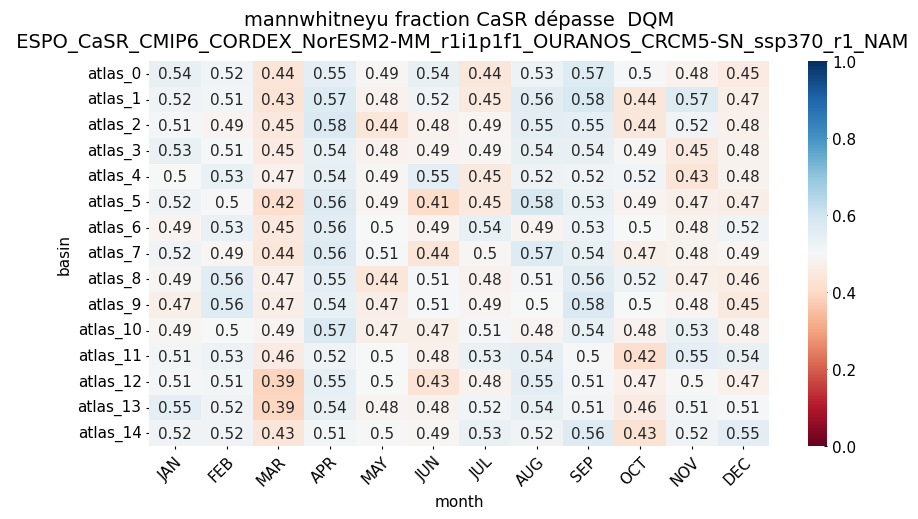

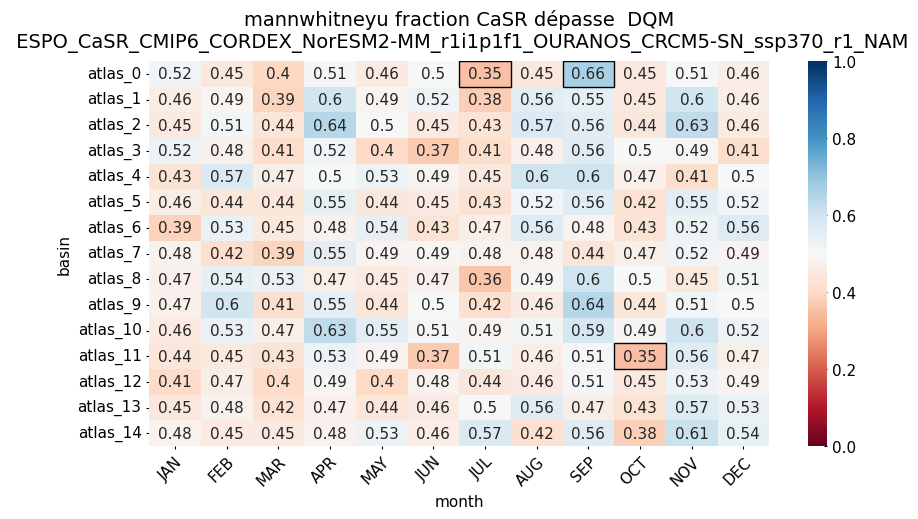

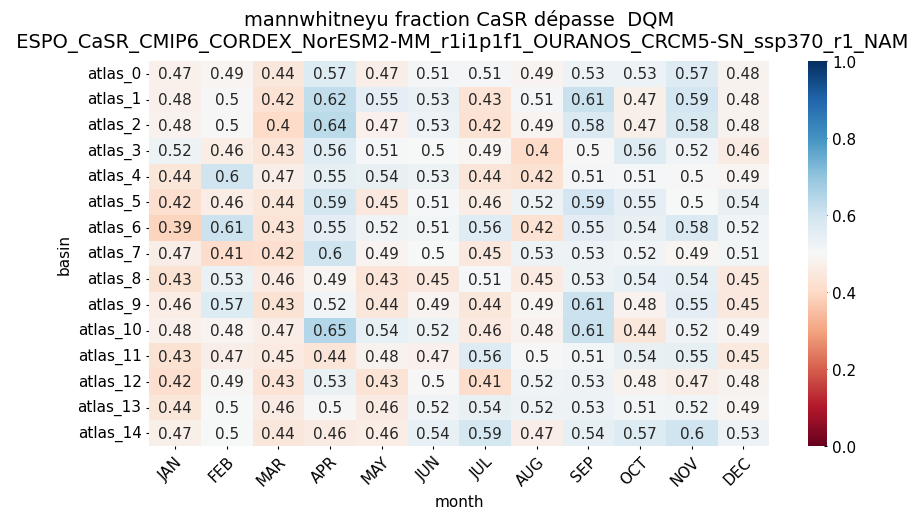

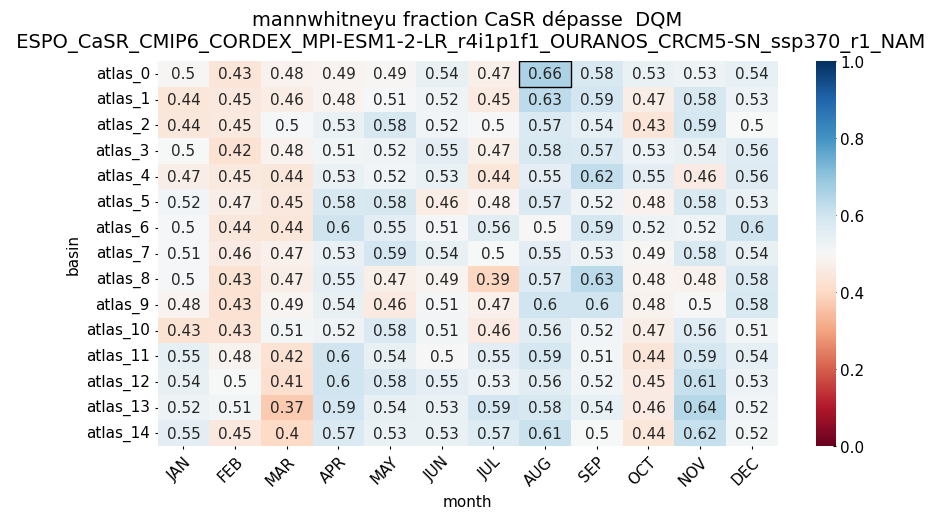

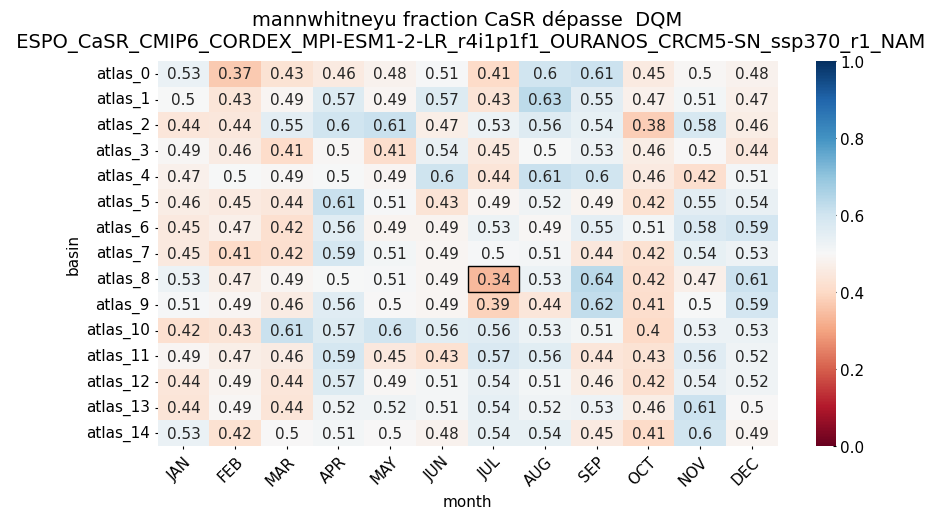

...

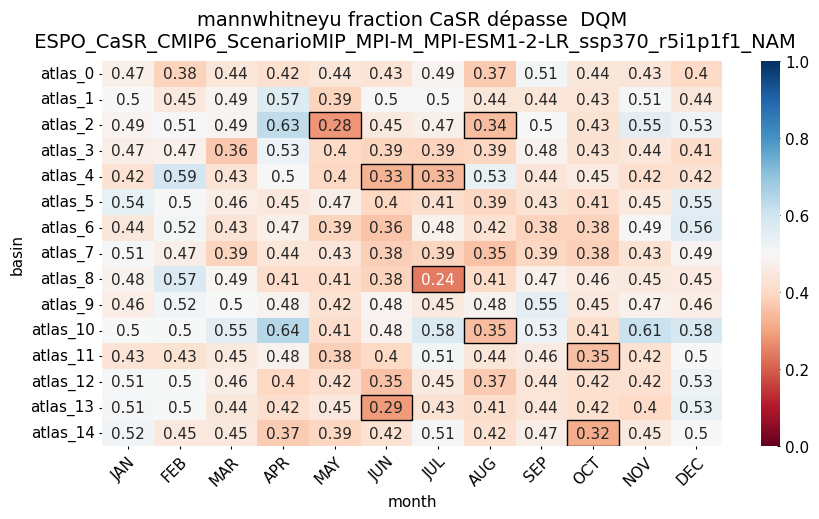

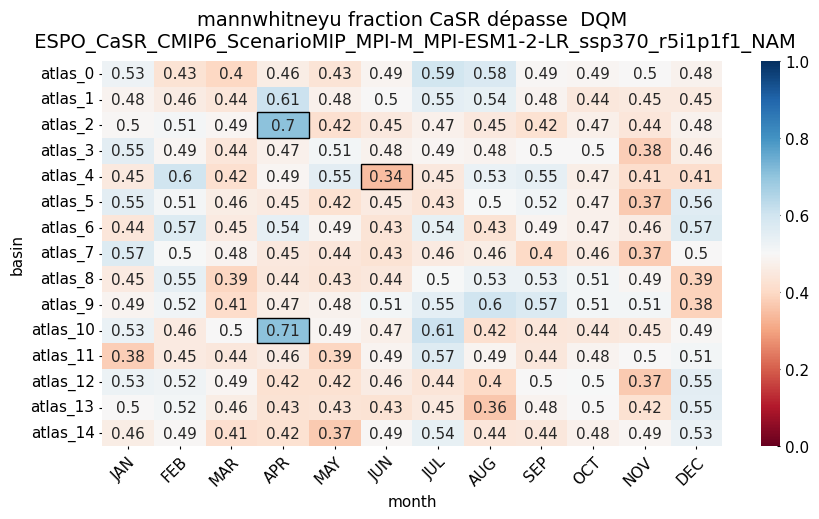

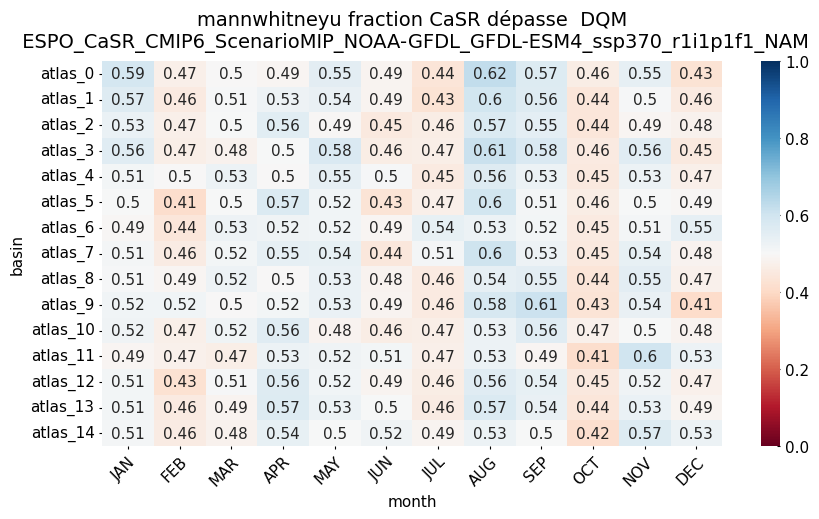

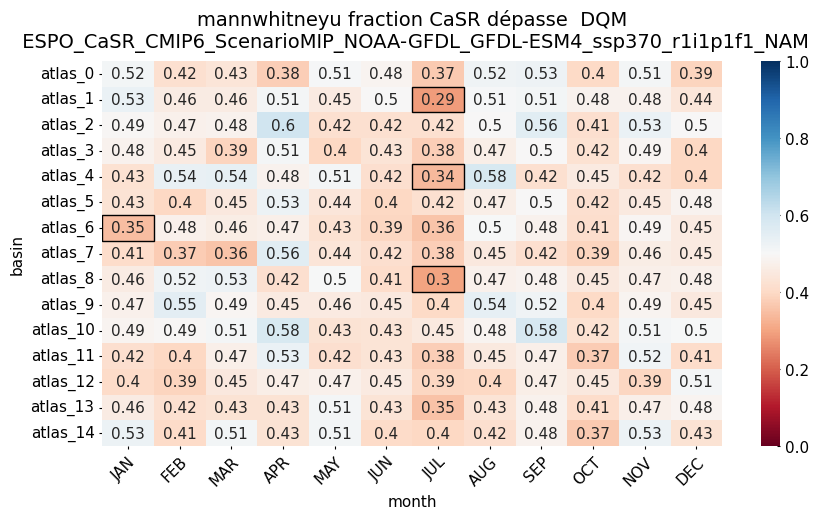

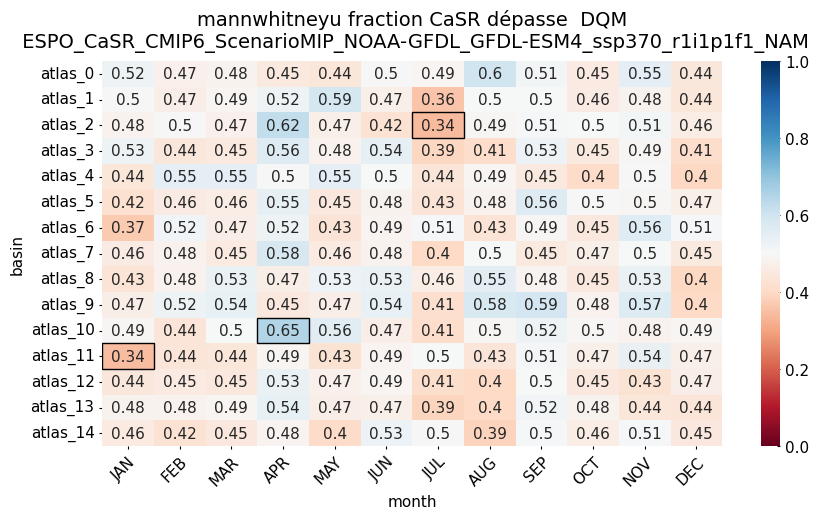

In [28]:
# #mannwhitneyu sim


# adj_ids=cat.search(experiment='ssp370', bias_adjust_project='ESPO').df.id.unique()
# for sim_id in adj_ids:
#     for var in ['prcptot', 'rx1day','rx5day']:
    
    
#         #for gdfs, geoname in zip([gdfsa, gdfs6], ["atlas", "lev06"], strict=True):
#         for gdfs, geoname in zip([gdfsa, ], ["atlas", ], strict=True):
#             print(geoname)
#             data=np.zeros((len(gdfs),12))
#             dataU=np.zeros((len(gdfs),12))
#             df_ref=pd.read_csv(f"{CONFIG['arches']}/bilan_pr/bassinavg_{geoname}_CaSR.csv")
#             df_adj=pd.read_csv(f"{CONFIG['arches']}/bilan_pr/bassinavg_{geoname}_{sim_id}.csv")
#             df_ref['month'] = pd.to_datetime(df_ref['time']).dt.strftime('%b').str.upper()
#             df_ref['monthnum'] = pd.to_datetime(df_ref['time']).dt.month
#             df_adj['month'] = pd.to_datetime(df_adj['time']).dt.strftime('%b').str.upper()
#             df_adj['monthnum'] = pd.to_datetime(df_adj['time']).dt.month
            

#             for i in range(len(gdfs)):
#                 cur_ref=df_ref[df_ref['basin_id']==i]

#                 cur_adj=df_adj[df_adj['basin_id']==i]
    
    
#                 for j, month in enumerate(months):
            
            
#                     data[i,j]=scipy.stats.mannwhitneyu(cur_ref.loc[cur_ref['monthnum']==j+1][var].values, cur_adj.loc[cur_adj['monthnum']==j+1][var].values ).pvalue
#                     u=scipy.stats.mannwhitneyu(cur_ref.loc[cur_ref['monthnum']==j+1][var].values, cur_adj.loc[cur_adj['monthnum']==j+1][var].values ).statistic
            
#                     dataU[i,j]=u/(len(cur_ref.loc[cur_ref['monthnum']==j+1][var].values)*len(cur_adj.loc[cur_adj['monthnum']==j+1][var].values))
#             out=xr.DataArray(data,coords={'basin':[f"{geoname}_{i}" for i in range(len(gdfs))],
#                                           'month':months}
#                             )
#             outU=xr.DataArray(dataU,coords={'basin':[f"{geoname}_{i}" for i in range(len(gdfs))],
#                                       'month':months}
#                         )
        
        
#         vmin = 0
#         vmax = 1
#         threshold = 0.05
        
#         # fraction of the colorbar that is red
#         red_fraction = (threshold - vmin) / (vmax - vmin)
        
#         # stitch together red + Blues using TwoSlopeNorm approach
#         cmap = mcolors.LinearSegmentedColormap.from_list(
#             "red_blues",
#             [(0.0, "red"),
#              (red_fraction, "red"),
#              (red_fraction, plt.cm.Blues(0.0)),  # start of Blues
#              (1.0, plt.cm.Blues(1.0))]           # end of Blues
#         )
        
#         norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
        
        
#         # ax=fg.heatmap(out,plot_kw={'annot':True,'norm':norm }, cmap=cmap, fig_kw={'figsize':(10,5)})
#         # ax.set_title(f'mannwhitneyu p-value CaSR vs DQM\n {sim_id}')
        
#         ax=fg.heatmap(outU,plot_kw={'annot':True, 'vmin':0, 'vmax':1 }, divergent=0.5, fig_kw={'figsize':(10,5)})
#         ax.set_title(f'mannwhitneyu fraction CaSR dépasse  DQM\n {sim_id}')
#         for i in range(out.shape[0]):
#             for j in range(out.shape[1]):
#                 if out[i,j]<0.05:
#                     ax.add_patch(patches.Rectangle(
#                     (j, i),       # (x, y) bottom-left corner
#                     1, 1,             # width, height
#                     fill=False,
#                     edgecolor='black',
#                     linewidth=1
#                 ))
#             #plt.savefig(f"{CONFIG['figures']}/basinavg_atlas_{var}_MN_{dm}.png",bbox_inches='tight')


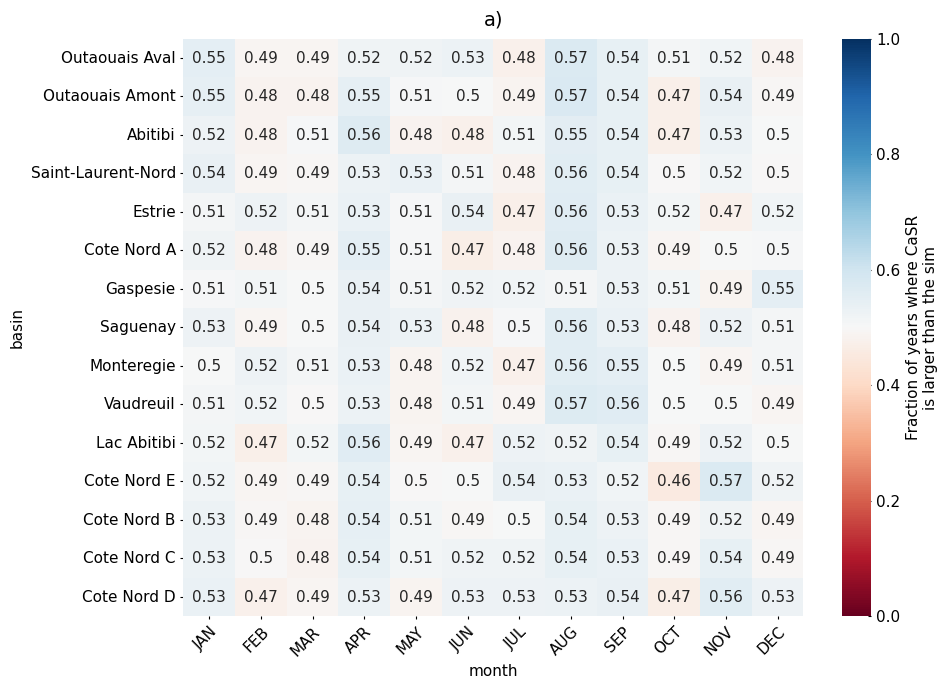

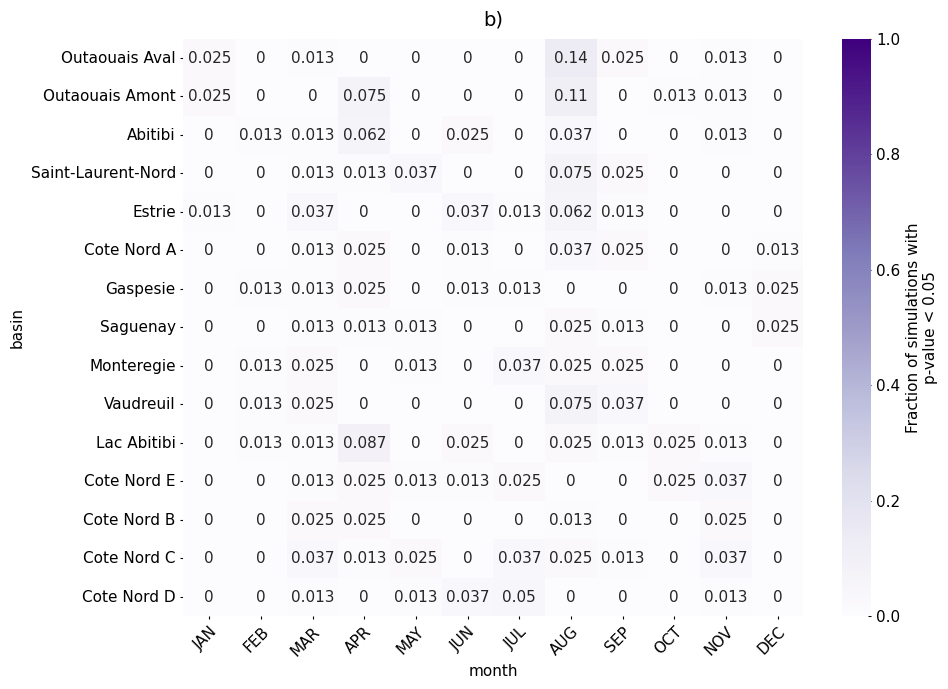

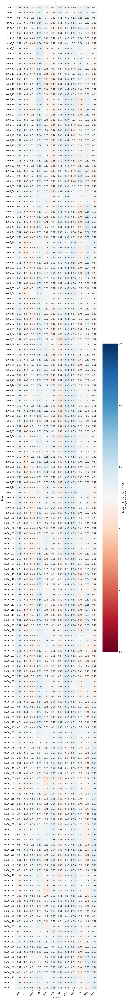

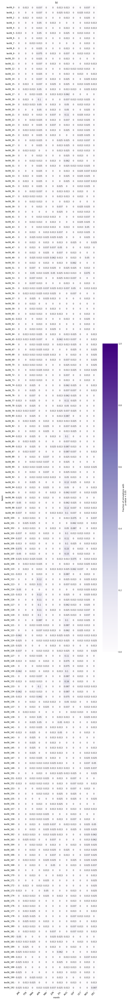

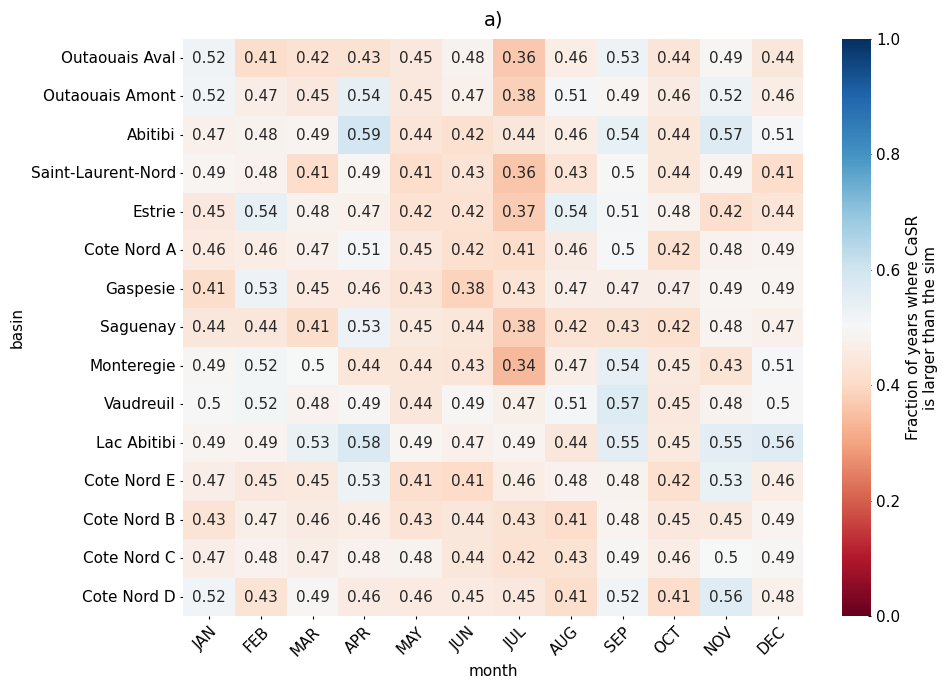

...

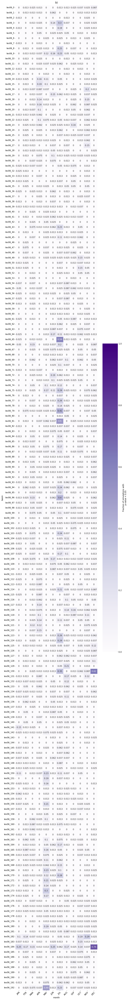

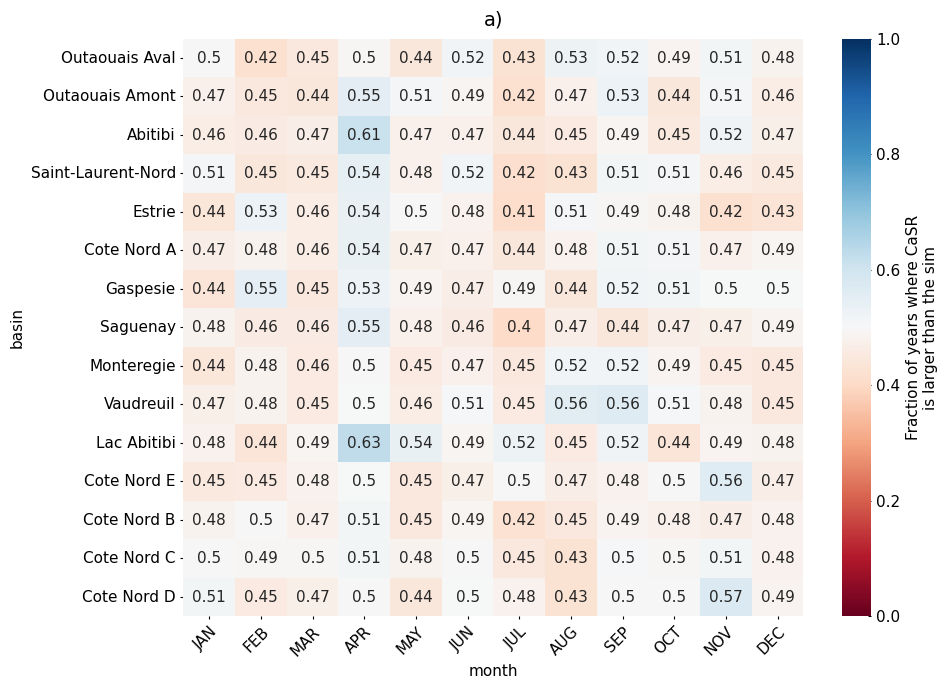

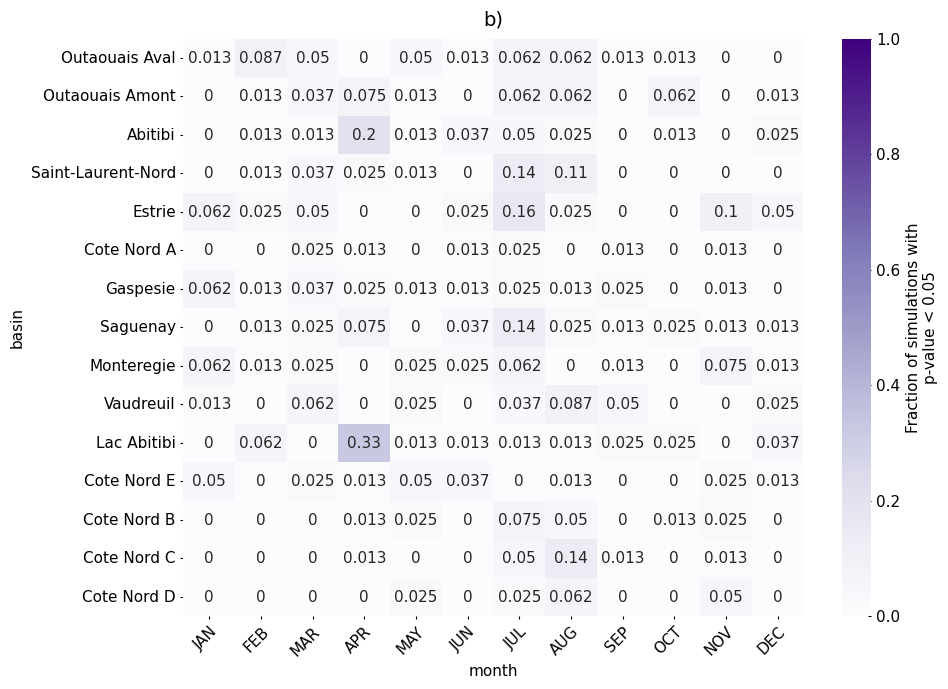

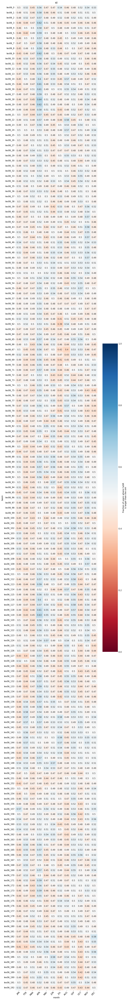

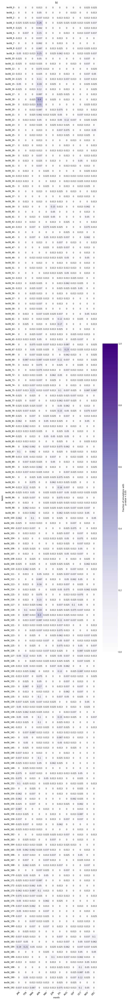

In [29]:
# #mannwhitneyu mean over sims


# sim_id='ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r1i1p2f1_NAM'
# adj_ids=cat.search(experiment='ssp370', bias_adjust_project='ESPO').df.id.unique()
# for var in ['prcptot', 'rx1day','rx5day']:
#     for gdfs, geoname in zip([gdfsa, gdfs6], ["atlas", "lev06"], strict=True):
# # for var in ['prcptot', ]:
# #     for gdfs, geoname in zip([gdfsa, ], ["atlas", ], strict=True):
#         outUs=[]
#         outs=[]
#         for sim_id in adj_ids:
    
#             data=np.zeros((len(gdfs),12))
#             dataU=np.zeros((len(gdfs),12))
#             df_ref=pd.read_csv(f"{CONFIG['arches']}/bilan_pr/bassinavg_{geoname}_CaSR.csv")
#             df_adj=pd.read_csv(f"{CONFIG['arches']}/bilan_pr/bassinavg_{geoname}_{sim_id}.csv")
#             df_ref['month'] = pd.to_datetime(df_ref['time']).dt.strftime('%b').str.upper()
#             df_ref['monthnum'] = pd.to_datetime(df_ref['time']).dt.month
#             df_adj['month'] = pd.to_datetime(df_adj['time']).dt.strftime('%b').str.upper()
#             df_adj['monthnum'] = pd.to_datetime(df_adj['time']).dt.month

#             for i in range(len(gdfs)):
#                 cur_ref=df_ref[df_ref['basin_id']==i]

#                 cur_adj=df_adj[df_adj['basin_id']==i]
    
    
#                 for j, month in enumerate(months):
            
            
#                     data[i,j]=scipy.stats.mannwhitneyu(cur_ref.loc[cur_ref['monthnum']==j+1][var].values, cur_adj.loc[cur_adj['monthnum']==j+1][var].values ).pvalue
#                     u=scipy.stats.mannwhitneyu(cur_ref.loc[cur_ref['monthnum']==j+1][var].values, cur_adj.loc[cur_adj['monthnum']==j+1][var].values ).statistic
            
#                     dataU[i,j]=u/(len(cur_ref.loc[cur_ref['monthnum']==j+1][var].values)*len(cur_adj.loc[cur_adj['monthnum']==j+1][var].values))
            
#             if geoname=='atlas':
#                 basins=gdfs['Nom_Projet']
#             else:
#                 basins=[f"{geoname}_{i}" for i in range(len(gdfs))]
#             out=xr.DataArray(data,coords={'basin':basins,
#                                           'month':months}
#                             )
#             out=out.expand_dims(dim={"realization": [sim_id]})
#             outs.append(out)
#             outU=xr.DataArray(dataU,coords={'basin':basins,
#                                       'month':months}
#                         )
#             outU=outU.expand_dims(dim={"realization": [sim_id]})
#             outUs.append(outU)
        
#         ensU=xr.concat(outUs,'realization')
#         ensU=ensU.mean('realization')
        
#         ens=xr.concat(outs,'realization')
#         pVal= ((ens<0.05).sum('realization'))/len(ens.realization)
#         pVal.attrs['long_name']='Fraction of simulations with p-value < 0.05'
        
#         vmin = 0
#         vmax = 1
#         threshold = 0.05
        
#         # fraction of the colorbar that is red
#         red_fraction = (threshold - vmin) / (vmax - vmin)
        
#         # stitch together red + Blues using TwoSlopeNorm approach
#         cmap = mcolors.LinearSegmentedColormap.from_list(
#             "red_blues",
#             [(0.0, "red"),
#              (red_fraction, "red"),
#              (red_fraction, plt.cm.Blues(0.0)),  # start of Blues
#              (1.0, plt.cm.Blues(1.0))]           # end of Blues
#         )
        
#         norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
#         ensU.attrs['long_name']='Fraction of years where CaSR is larger than the sim'
        
#         ax=fg.heatmap(ensU,plot_kw={'annot':True,'vmin':0, 'vmax':1 }, divergent=0.5, fig_kw={'figsize':(10,0.5*len(gdfs))})
#         ax.set_title(f'a)')
#         plt.savefig(f"{CONFIG['figures']}/basinavg_{var}_{geoname}_MN_allmodels.png",bbox_inches='tight')

#         ax=fg.heatmap(pVal,plot_kw={'annot':True,'vmin':0, 'vmax':1 }, cmap='Purples', fig_kw={'figsize':(10,0.5*len(gdfs))})
#         ax.set_title(f'b)')
#         plt.savefig(f"{CONFIG['figures']}/basinavg_{var}_{geoname}_pVal_allmodels.png",bbox_inches='tight')


# RX1day robustness
Results from this section were put in their own technical note, not included in the report of method choice.

In [30]:
# copy xclim code here to test different versions (source: https://github.com/Ouranosinc/xclim/blob/main/src/xclim/ensembles/_robustness.py)

import sys
import textwrap
from collections.abc import Callable
from inspect import Parameter, signature
from typing import cast

import numpy as np
import scipy.stats as spstats
import xarray as xr

from xclim.core.formatting import gen_call_string, update_xclim_history
from xclim.core.missing import MissingAny, MissingBase
from xclim.indices.generic import compare, detrend

SIGNIFICANCE_TESTS = {}

def significance_test(func: Callable) -> Callable:
    SIGNIFICANCE_TESTS[func.__name__[1:].replace("_", "-")] = func
    return func

def robustness_fractions(
    fut: xr.DataArray,
    ref: xr.DataArray | None = None,
    test: str | None = None,
    weights: xr.DataArray | None = None,
    invalid: MissingBase | None = None,
    strict_sign: bool = True,
    **kwargs,
) -> xr.Dataset:

    # Realization dimension name
    realization = "realization"

    # Assign dummy realization dimension if not present.
    if realization not in fut.dims:
        fut = fut.assign_coords({realization: "dummy"})
        fut = fut.expand_dims(realization)
    if ref is not None and realization not in ref.dims:
        ref = ref.assign_coords({realization: "dummy"})
        ref = ref.expand_dims(realization)

    # Get dummy weights to simplify code
    if weights is not None:
        w = weights
    else:
        w = xr.DataArray(
            [1] * fut[realization].size,
            dims=(realization,),
            coords={"realization": fut[realization]},
        )

    if ref is None:
        delta = fut
        valid = delta.notnull()
        if test not in [None, "threshold"]:
            raise ValueError("When deltas are given (ref=None), 'test' must be None or 'threshold'.")
    else:
        if invalid is None:
            invalid = MissingAny()
        delta = fut.mean("time") - ref.mean("time")
        valid = ~invalid(fut) & ~invalid(ref)

    if test is None:
        test_params = {}
        changed = xr.ones_like(delta).astype(bool)
        pvals = None
    elif test == "threshold":
        abs_thresh = kwargs.get("abs_thresh")
        rel_thresh = kwargs.get("rel_thresh")
        if abs_thresh is not None and rel_thresh is None:
            changed = abs(delta) > abs_thresh
            test_params = {"abs_thresh": abs_thresh}
        elif rel_thresh is not None and abs_thresh is None:
            changed = abs(delta / ref.mean("time")) > rel_thresh
            test_params = {"rel_thresh": rel_thresh}
        else:
            raise ValueError("One and only one of abs_thresh or rel_thresh must be given if test='threshold'.")
        pvals = None
    elif test in SIGNIFICANCE_TESTS:
        test_func = SIGNIFICANCE_TESTS[test]
        test_params = {
            n: kwargs.get(n, p.default)
            for n, p in signature(test_func).parameters.items()
            if p.kind == Parameter.KEYWORD_ONLY
        }

        changed, pvals = test_func(fut, ref, **test_params)
    else:
        raise ValueError(f"Statistical test {test} must be one of {', '.join(SIGNIFICANCE_TESTS.keys())}.")

    valid_frac = valid.weighted(w).sum(realization) / fut[realization].size
    n_valid = valid.weighted(w).sum(realization)
    change_frac = changed.where(valid).weighted(w).sum(realization) / n_valid
    if strict_sign:
        neg_del = compare(delta, "<", 0)
        pos_del = compare(delta, ">", 0)
    else:
        neg_del = compare(delta, "<=", 0)
        pos_del = compare(delta, ">=", 0)

    neg_frac = neg_del.where(valid).weighted(w).sum(realization) / n_valid
    pos_frac = pos_del.where(valid).weighted(w).sum(realization) / n_valid
    change_pos_frac = (pos_del & changed).where(valid).weighted(w).sum(realization) / n_valid
    change_neg_frac = (neg_del & changed).where(valid).weighted(w).sum(realization) / n_valid
    agree_frac = xr.concat((pos_frac, neg_frac, 1 - pos_frac - neg_frac), "sign").max("sign")

    # Metadata
    kwargs_str = gen_call_string("", **test_params)[1:-1]
    test_str = f"Significant change was tested with test {test} and parameters {kwargs_str}."

    strict = "strictly " if strict_sign else "zero or "
    out = xr.Dataset(
        {
            "changed": change_frac.assign_attrs(
                description=f"Fraction of valid members showing significant change. {test_str}",
                units="",
                test=str(test),
            ),
            "positive": pos_frac.assign_attrs(
                description=f"Fraction of valid members showing {strict} positive change.",
                units="",
            ),
            "changed_positive": change_pos_frac.assign_attrs(
                description=f"Fraction of valid members showing significant and {strict} positive change. {test_str}",
                units="",
                test=str(test),
            ),
            "negative": neg_frac.assign_attrs(
                description=f"Fraction of valid members showing {strict} negative change.",
                units="",
            ),
            "changed_negative": change_neg_frac.assign_attrs(
                description=f"Fraction of valid members showing significant and {strict} negative change. {test_str}",
                units="",
                test=str(test),
            ),
            "valid": valid_frac.assign_attrs(
                description="Fraction of valid members (No missing values along time).",
                units="",
            ),
            "agree": agree_frac.assign_attrs(
                description="Fraction of valid members agreeing on the sign of change. "
                + (
                    "Maximum between the positive, negative and no change fractions."
                    if strict_sign
                    else "Maximum between the zero or positive and the zero or negative change fractions."
                ),
                units="",
            ),
        },
        attrs={"description": "Significant change and sign of change fractions."},
    )
    out = out.fillna(0)

    if pvals is not None:
        pvals.attrs.update(
            description=f"P-values from change significance test. {test_str}",
            units="",
        )
        out = out.assign(pvals=pvals)

    # Keep attrs on non-modified coordinates
    for ncrd, crd in fut.coords.items():
        if ncrd in out.coords:
            out[ncrd].attrs.update(crd.attrs)

    return out



@significance_test
def _ipcc_ar6_c_1(fut, ref, *, ref_pi=None):

    # Ensure annual
    refy = ref.resample(time="YS").mean()
    if ref_pi is None:
        ref_detrended = detrend(refy, dim="time", deg=1)
        gamma = np.sqrt(2 / len(refy.time)) * 1.645 * ref_detrended.std("time")
    else:
        ref_detrended = detrend(refy, dim="time", deg=2)
        gamma = np.sqrt(2) * 1.645 * ref_detrended.resample(time="20YS").mean().std("time")

    delta = fut.mean("time") - ref.mean("time")
    changed = abs(delta) > gamma
    return changed, None

@significance_test
def _ipcc_ar6_c_062(fut, ref, *, ref_pi=None):

    # Ensure annual
    refy = ref.resample(time="YS").mean()
    if ref_pi is None:
        ref_detrended = detrend(refy, dim="time", deg=1)
        gamma = np.sqrt(2 / 20) * 1.645 * ref_detrended.std("time")
    else:
        ref_detrended = detrend(refy, dim="time", deg=2)
        gamma = np.sqrt(2) * 1.645 * ref_detrended.resample(time="20YS").mean().std("time")

    delta = fut.mean("time") - ref.mean("time")
    changed = abs(delta) > gamma
    return changed, None

2026-10-16 11:51:02 INFO     xscen.extract   Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


INFO:xscen.extract:Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


2026-10-16 11:51:02 INFO     xscen.extract   288 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP'}.


INFO:xscen.extract:288 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP'}.


2026-10-16 11:51:02 INFO     xscen.extract   Iterating over 72 potential datasets.


INFO:xscen.extract:Iterating over 72 potential datasets.


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:03 INFO     xscen.extract   Found 72 with all variables requested and corresponding to the criteria.


INFO:xscen.extract:Found 72 with all variables requested and corresponding to the criteria.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_INM-CM5-0_INM_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_INM-CM5-0_INM_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_EC-Earth3_EC-Earth-Consortium_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_EC-Earth3_EC-Earth-Consortium_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r6i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r6i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r9i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r9i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r11i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r11i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_EC-Earth3-Veg_EC-Earth-Consortium_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_EC-Earth3-Veg_EC-Earth-Consortium_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_CanESM5_CCCma_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_CanESM5_CCCma_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_IPSL-CM6A-LR_IPSL_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_IPSL-CM6A-LR_IPSL_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_UKESM1-0-LL_MOHC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_UKESM1-0-LL_MOHC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r3i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r3i1p1f2_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r2i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r2i1p1f2_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r4i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r4i1p1f2_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r8i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r8i1p1f2_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:03 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".


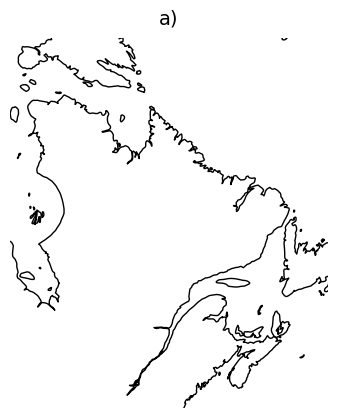

In [31]:
#ipcc atlas

def rx1day_rob(
    ref,
    fut,
    n_members,
    other_search_criteria,
    typ,
    xclimv,
    letter):


    typname={'reg1deg': '1deg', 'reg10km':'10km', 'espo':'ESPO'}
    levname={'reg1deg': 'raw', 'reg10km':'raw', 'espo':'adjusted'}

    sim_dict =xs.search_data_catalogs(
        data_catalogs=cat,
        variables_and_freqs={'pr':'D'},
        restrict_members={'ordered':n_members},
        other_search_criteria=other_search_criteria
    )
    
    n_sources=len(set([str(v.df['source'].unique()[0]) for  k,v in sim_dict.items()]))
    
    datasets=[]
    delta_datasets=[]
    for sim_id in sim_dict.keys():
        sim_id = sim_id.replace(".NAM.biasadjusted.D", "")
        ds= xr.open_zarr(f"{CONFIG['arches']}/rx1day/{typ}/rx1day_{sim_id}_{typ}.zarr.zip")
        datasets.append(ds)
    
    ens = xc.ensembles.create_ensemble(datasets)
    fractions = robustness_fractions(ens.rx1day.sel(time=slice(fut[:4], fut[-4:])),ens.rx1day.sel(time=slice(ref[:4], ref[-4:])), test=f"ipcc-ar6-c-{xclimv}")
    robustness = xc.ensembles.robustness_categories(fractions)
    nochange=robustness.where(robustness==2)
    conflict=robustness.where(robustness==3)
    
    
    ax=fg.gridmap(nochange , plot_kw={'add_colorbar':False},features={"coastline":{'color':'black'}},)
    #ax.set_title(f"{letter}) max {n_members} members of {n_sources} {levname[typ]} GCMs.\n {typname[typ]} grid. \n {fut} vs.{ref}")
    ax.set_title(f"{letter})")
    plt.savefig(f"{CONFIG['figures']}/rx1day_{n_members}mem_{n_sources}mod_{typ}_xclimv{xclimv}_{ref}_{fut}.pdf",bbox_inches='tight')
    # pcolurmesh doesnt show when it is on smaller area
    # ax=fg.hatchmap(
    #     {"No change or no signal": nochange, "Conflicting signal": conflict},
    #     plot_kw={"No change or no signal": {"hatches":'\\\\'},  "Conflicting signal":{"hatches": "X",}},
    #     features={"coastline":{'color':'grey'}},
    #     legend_kw={"title": ""},
    # )
    # ax.set_title(f"{letter}) max {n_members} members of {n_sources} {levname[typ]} GCMs.\n {typname[typ]} grid. \n {fut} vs.{ref}")

rx1day_rob(
    ref="1981-2010",
    fut='2081-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP'),
    typ='reg1deg',
    xclimv='1',
    letter='a')

2026-10-16 11:51:06 INFO     xscen.extract   Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


INFO:xscen.extract:Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


2026-10-16 11:51:06 INFO     xscen.extract   288 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP'}.


INFO:xscen.extract:288 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP'}.


2026-10-16 11:51:06 INFO     xscen.extract   Iterating over 72 potential datasets.


INFO:xscen.extract:Iterating over 72 potential datasets.


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:06 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:07 INFO     xscen.extract   Found 72 with all variables requested and corresponding to the criteria.


INFO:xscen.extract:Found 72 with all variables requested and corresponding to the criteria.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_INM-CM5-0_INM_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_INM-CM5-0_INM_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_INM_INM-CM5-0_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_EC-Earth3_EC-Earth-Consortium_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_EC-Earth3_EC-Earth-Consortium_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r6i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r6i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r9i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r9i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r11i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3_ssp370_r11i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_EC-Earth3-Veg_EC-Earth-Consortium_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_EC-Earth3-Veg_EC-Earth-Consortium_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_EC-Earth-Consortium_EC-Earth3-Veg_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_CanESM5_CCCma_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_CanESM5_CCCma_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CCCma_CanESM5_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_IPSL-CM6A-LR_IPSL_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_IPSL-CM6A-LR_IPSL_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_IPSL_IPSL-CM6A-LR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_UKESM1-0-LL_MOHC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_UKESM1-0-LL_MOHC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r3i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r3i1p1f2_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r2i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r2i1p1f2_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r4i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r4i1p1f2_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r8i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MOHC_UKESM1-0-LL_ssp370_r8i1p1f2_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:07 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".


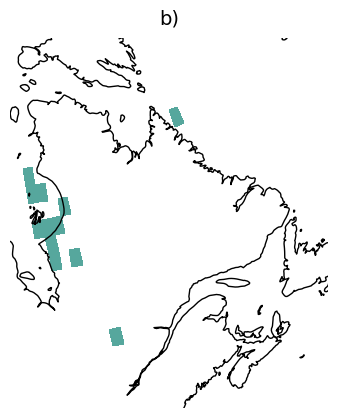

In [32]:
# portrait period
rx1day_rob(
    ref="1991-2020",
    fut='2071-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP'),
    typ='reg1deg',
    xclimv='1',
    letter='b',
    
)

2026-10-16 11:51:10 INFO     xscen.extract   Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


INFO:xscen.extract:Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


2026-10-16 11:51:10 INFO     xscen.extract   164 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP', 'source': ['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'FGOALS-g3', 'GFDL-ESM4', 'MIROC6', 'MIROC-ES2L', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NorESM2-LM']}.


INFO:xscen.extract:164 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP', 'source': ['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'FGOALS-g3', 'GFDL-ESM4', 'MIROC6', 'MIROC-ES2L', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NorESM2-LM']}.


2026-10-16 11:51:10 INFO     xscen.extract   Iterating over 41 potential datasets.


INFO:xscen.extract:Iterating over 41 potential datasets.


2026-10-16 11:51:10 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:10 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:10 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:10 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:11 INFO     xscen.extract   Found 41 with all variables requested and corresponding to the criteria.


INFO:xscen.extract:Found 41 with all variables requested and corresponding to the criteria.


2026-10-16 11:51:11 INFO     xscen.extract   Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:11 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".


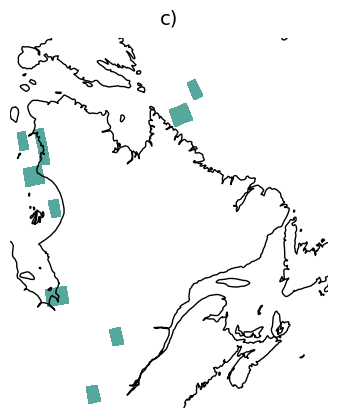

In [33]:
# hausfather , ipcc periods


rx1day_rob(
    ref="1981-2010",
    fut='2081-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP',
                              source=['ACCESS-CM2','ACCESS-ESM1-5','BCC-CSM2-MR','CMCC-ESM2','CNRM-CM6-1','CNRM-ESM2-1','FGOALS-g3','GFDL-ESM4',
                                    'MIROC6','MIROC-ES2L','MPI-ESM1-2-HR','MPI-ESM1-2-LR','MRI-ESM2-0','NorESM2-LM',]),
    typ='reg1deg',
    xclimv='1',
    letter='c',
)

2026-10-16 11:51:12 INFO     xscen.extract   Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


INFO:xscen.extract:Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


2026-10-16 11:51:12 INFO     xscen.extract   164 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP', 'source': ['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'FGOALS-g3', 'GFDL-ESM4', 'MIROC6', 'MIROC-ES2L', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NorESM2-LM']}.


INFO:xscen.extract:164 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP', 'source': ['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'FGOALS-g3', 'GFDL-ESM4', 'MIROC6', 'MIROC-ES2L', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NorESM2-LM']}.


2026-10-16 11:51:12 INFO     xscen.extract   Iterating over 41 potential datasets.


INFO:xscen.extract:Iterating over 41 potential datasets.


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:12 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:13 INFO     xscen.extract   Found 41 with all variables requested and corresponding to the criteria.


INFO:xscen.extract:Found 41 with all variables requested and corresponding to the criteria.


2026-10-16 11:51:13 INFO     xscen.extract   Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:13 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".


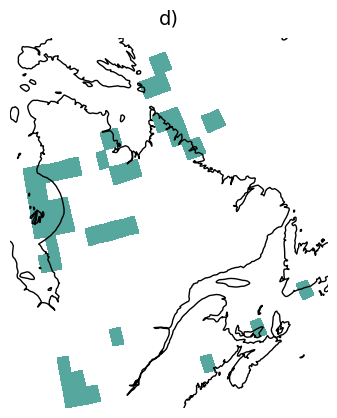

In [34]:
# hausfather ,portraits periods


rx1day_rob(
    ref="1991-2020",
    fut='2071-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP',
                              source=['ACCESS-CM2','ACCESS-ESM1-5','BCC-CSM2-MR','CMCC-ESM2','CNRM-CM6-1','CNRM-ESM2-1','FGOALS-g3','GFDL-ESM4',
                                    'MIROC6','MIROC-ES2L','MPI-ESM1-2-HR','MPI-ESM1-2-LR','MRI-ESM2-0','NorESM2-LM',]),
    typ='reg1deg',
    xclimv='1',
    letter='d',
)

2026-10-16 11:51:14 INFO     xscen.extract   Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


INFO:xscen.extract:Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


2026-10-16 11:51:14 INFO     xscen.extract   164 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP', 'source': ['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'FGOALS-g3', 'GFDL-ESM4', 'MIROC6', 'MIROC-ES2L', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NorESM2-LM']}.


INFO:xscen.extract:164 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP', 'source': ['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'FGOALS-g3', 'GFDL-ESM4', 'MIROC6', 'MIROC-ES2L', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NorESM2-LM']}.


2026-10-16 11:51:14 INFO     xscen.extract   Iterating over 41 potential datasets.


INFO:xscen.extract:Iterating over 41 potential datasets.


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:51:14 INFO     xscen.extract   Found 41 with all variables requested and corresponding to the criteria.


INFO:xscen.extract:Found 41 with all variables requested and corresponding to the criteria.


2026-10-16 11:51:14 INFO     xscen.extract   Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:51:14 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/nump

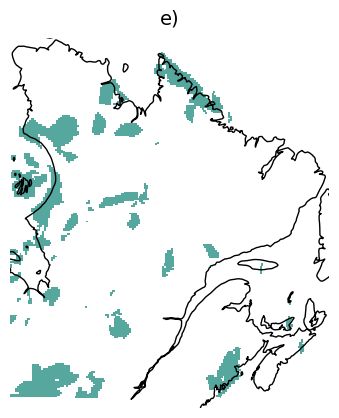

In [35]:
# hausfather , portraits periods, 10km


rx1day_rob(
    ref="1991-2020",
    fut='2071-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP',
                              source=['ACCESS-CM2','ACCESS-ESM1-5','BCC-CSM2-MR','CMCC-ESM2','CNRM-CM6-1','CNRM-ESM2-1','FGOALS-g3','GFDL-ESM4',
                                    'MIROC6','MIROC-ES2L','MPI-ESM1-2-HR','MPI-ESM1-2-LR','MRI-ESM2-0','NorESM2-LM',]),
    typ='reg10km',
    xclimv='1',
    letter='e',
)

2026-10-16 11:52:09 INFO     xscen.extract   Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


INFO:xscen.extract:Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


2026-10-16 11:52:09 INFO     xscen.extract   164 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP', 'source': ['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'FGOALS-g3', 'GFDL-ESM4', 'MIROC6', 'MIROC-ES2L', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NorESM2-LM']}.


INFO:xscen.extract:164 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP', 'source': ['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'FGOALS-g3', 'GFDL-ESM4', 'MIROC6', 'MIROC-ES2L', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NorESM2-LM']}.


2026-10-16 11:52:09 INFO     xscen.extract   Iterating over 41 potential datasets.


INFO:xscen.extract:Iterating over 41 potential datasets.


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:52:09 INFO     xscen.extract   Found 41 with all variables requested and corresponding to the criteria.


INFO:xscen.extract:Found 41 with all variables requested and corresponding to the criteria.


2026-10-16 11:52:09 INFO     xscen.extract   Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:52:09 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: Runti

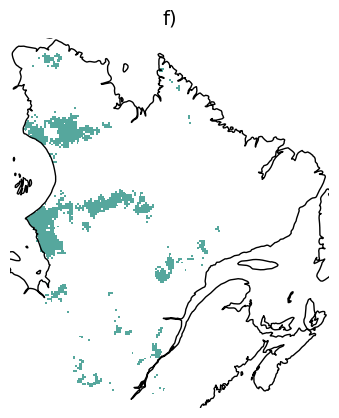

In [36]:
# hausfather , portraits periods, espo


rx1day_rob(
    ref="1991-2020",
    fut='2071-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP',
                              source=['ACCESS-CM2','ACCESS-ESM1-5','BCC-CSM2-MR','CMCC-ESM2','CNRM-CM6-1','CNRM-ESM2-1','FGOALS-g3','GFDL-ESM4',
                                    'MIROC6','MIROC-ES2L','MPI-ESM1-2-HR','MPI-ESM1-2-LR','MRI-ESM2-0','NorESM2-LM',]),
    typ='espo',
    xclimv='1',
    letter='f',
)

2026-10-16 11:53:01 INFO     xscen.extract   Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


INFO:xscen.extract:Catalog opened: <cat_ARCHES catalog with 299 dataset(s) from 1036 asset(s)> from 1 files.


2026-10-16 11:53:01 INFO     xscen.extract   164 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP', 'source': ['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'FGOALS-g3', 'GFDL-ESM4', 'MIROC6', 'MIROC-ES2L', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NorESM2-LM']}.


INFO:xscen.extract:164 assets matched the criteria : {'bias_adjust_project': 'ESPO', 'experiment': 'ssp370', 'activity': 'ScenarioMIP', 'source': ['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'FGOALS-g3', 'GFDL-ESM4', 'MIROC6', 'MIROC-ES2L', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NorESM2-LM']}.


2026-10-16 11:53:01 INFO     xscen.extract   Iterating over 41 potential datasets.


INFO:xscen.extract:Iterating over 41 potential datasets.


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:01 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 DEBUG    xscen.extract   At var pr, after search cat has []


DEBUG:xscen.extract:At var pr, after search cat has []


2026-10-16 11:53:02 INFO     xscen.extract   Found 41 with all variables requested and corresponding to the criteria.


INFO:xscen.extract:Found 41 with all variables requested and corresponding to the criteria.


2026-10-16 11:53:02 INFO     xscen.extract   Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MRI-ESM2-0_MRI_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MRI_MRI-ESM2-0_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-HR_DKRZ_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_DKRZ_MPI-ESM1-2-HR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_FGOALS-g3_CAS_ESPO_ScenarioMIP_ssp370_CaSR has 3 valid members. Restricting as per requested.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CAS_FGOALS-g3_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC-ES2L_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 2 valid members. Restricting as per requested.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC-ES2L_ssp370_r2i1p1f2_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MIROC6_MIROC_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MIROC_MIROC6_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-ESM1-5_CSIRO_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r6i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO_ACCESS-ESM1-5_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_ACCESS-CM2_CSIRO-ARCCSS_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r5i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_CSIRO-ARCCSS_ACCESS-CM2_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


INFO:xscen.extract:Dataset NAM_CMIP6_MPI-ESM1-2-LR_MPI-M_ESPO_ScenarioMIP_ssp370_CaSR has 5 valid members. Restricting as per requested.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r2i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r3i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r4i1p1f1_NAM from the results.


2026-10-16 11:53:02 INFO     xscen.extract   Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.


INFO:xscen.extract:Removing ESPO_CaSR_CMIP6_ScenarioMIP_MPI-M_MPI-ESM1-2-LR_ssp370_r5i1p1f1_NAM from the results.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: Runti

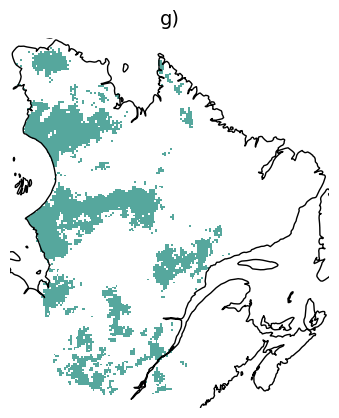

In [37]:
# hausfather , portraits periods, espo, old xclim


rx1day_rob(
    ref="1991-2020",
    fut='2071-2100',
    n_members=1,
    other_search_criteria=dict(bias_adjust_project="ESPO", experiment="ssp370",activity='ScenarioMIP',
                              source=['ACCESS-CM2','ACCESS-ESM1-5','BCC-CSM2-MR','CMCC-ESM2','CNRM-CM6-1','CNRM-ESM2-1','FGOALS-g3','GFDL-ESM4',
                                    'MIROC6','MIROC-ES2L','MPI-ESM1-2-HR','MPI-ESM1-2-LR','MRI-ESM2-0','NorESM2-LM',]),
    typ='espo',
    xclimv='062',
    letter='g',
)

# Adapt freq validation


--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


2026-10-16 11:54:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:33 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:33 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:33 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:33 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:34 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:34 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:34 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:34 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:35 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:35 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:35 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:36 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:36 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:36 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:37 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:37 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:38 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:38 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:38 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:38 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:39 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:39 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:39 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:40 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:40 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:40 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:40 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:41 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:41 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:41 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:42 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:42 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:42 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:42 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:43 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:43 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:44 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:44 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:44 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:44 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:45 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:45 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:45 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:45 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:46 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:46 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:46 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:46 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:47 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:47 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:47 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:47 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:48 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:48 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:49 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:49 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:49 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:49 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:50 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:50 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:50 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:50 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:51 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:51 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:51 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:51 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:52 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:52 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:52 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:53 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:53 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:53 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:53 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:54 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:54 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:54 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:55 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:55 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:55 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:55 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:56 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:56 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:56 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:58 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:54:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:54:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:55:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:55:00 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:55:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:55:01 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:55:02 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:55:03 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:55:03 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:55:04 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:55:04 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:55:04 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:55:04 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:55:05 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:55:05 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:55:05 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:55:06 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:55:06 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 11:55:06 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 11:55:06 INFO     xscen.ensembles Calculating ensemble_percentiles from an ensemble of 80 simulations.


INFO:xscen.ensembles:Calculating ensemble_percentiles from an ensemble of 80 simulations.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.


2026-10-16 12:02:37 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:37 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.



--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


2026-10-16 12:02:52 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:52 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:53 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:53 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:53 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:53 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:54 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:54 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:54 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:55 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:55 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:55 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:55 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:56 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:56 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:56 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:56 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:58 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:58 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:02:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:02:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:00 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:00 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:01 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:01 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:01 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:01 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:02 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:02 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:02 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:03 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:03 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:03 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:03 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:04 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:04 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:04 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:04 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:05 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:05 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:05 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:05 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:06 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:06 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:06 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:06 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:07 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:07 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:07 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:07 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:33 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:03:33 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:03:33 INFO     xscen.ensembles Calculating ensemble_percentiles from an ensemble of 80 simulations.


INFO:xscen.ensembles:Calculating ensemble_percentiles from an ensemble of 80 simulations.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.


2026-10-16 12:05:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.



--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


2026-10-16 12:05:45 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:46 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:46 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:46 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:46 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:47 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:47 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:47 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:47 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:48 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:48 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:48 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:49 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:49 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:49 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:49 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:50 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:50 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:50 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:50 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:51 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:51 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:51 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:51 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:52 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:52 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:52 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:52 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:53 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:53 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:53 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:53 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:54 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:54 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:54 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:54 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:55 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:55 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:55 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:55 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:56 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:56 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:56 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:56 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:58 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:58 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:05:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:05:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:00 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:00 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:01 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:01 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:01 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:01 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:02 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:02 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:02 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:02 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:03 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:03 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:03 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:04 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:04 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:04 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:04 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:05 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:05 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:05 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:05 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:06 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:06 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:06 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:07 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:07 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:07 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:07 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:06:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:06:28 INFO     xscen.ensembles Calculating ensemble_percentiles from an ensemble of 80 simulations.


INFO:xscen.ensembles:Calculating ensemble_percentiles from an ensemble of 80 simulations.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.


2026-10-16 12:08:38 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:38 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.



--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


2026-10-16 12:08:52 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:52 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:52 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:52 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:53 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:53 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:53 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:53 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:54 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:54 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:54 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:54 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:55 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:55 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:55 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:55 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:56 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:56 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:56 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:56 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:58 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:58 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:08:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:08:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:00 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:00 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:01 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:01 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:01 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:01 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:02 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:02 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:02 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:02 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:03 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:03 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:03 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:03 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:04 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:04 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:04 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:05 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:05 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:05 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:05 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:06 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:06 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:06 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:06 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:07 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:07 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:07 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:09:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:09:32 INFO     xscen.ensembles Calculating ensemble_percentiles from an ensemble of 80 simulations.


INFO:xscen.ensembles:Calculating ensemble_percentiles from an ensemble of 80 simulations.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.


2026-10-16 12:11:40 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:40 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.



--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


2026-10-16 12:11:54 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:54 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:11:54 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:54 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:11:55 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:55 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:11:55 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:55 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:11:56 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:56 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:11:56 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:56 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:11:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:11:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:11:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:58 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:11:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:11:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:11:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:11:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:00 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:00 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:01 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:01 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:01 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:01 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:02 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:02 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:02 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:02 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:03 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:03 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:05 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:05 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:05 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:06 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:06 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:06 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:06 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:07 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:07 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:07 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:07 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:33 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:33 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:33 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:33 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:34 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:34 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:34 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:34 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:35 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:35 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:35 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:35 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:12:36 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:12:36 INFO     xscen.ensembles Calculating ensemble_percentiles from an ensemble of 80 simulations.


INFO:xscen.ensembles:Calculating ensemble_percentiles from an ensemble of 80 simulations.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.


2026-10-16 12:14:53 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:14:54 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.



--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


2026-10-16 12:15:07 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:07 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:33 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:33 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:33 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:33 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:34 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:34 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:34 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:34 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:35 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:35 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:35 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:35 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:36 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:36 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:36 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:36 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:37 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:37 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:37 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:38 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:38 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:38 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:38 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:39 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:39 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:39 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:39 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:40 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:40 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:40 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:40 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:41 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:41 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:41 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:41 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:42 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:42 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:42 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:42 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:43 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:43 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:43 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:43 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:44 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:44 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:44 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:44 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:45 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:45 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:45 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:45 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:46 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:46 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:46 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:46 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:47 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:47 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:47 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:15:47 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:15:48 INFO     xscen.ensembles Calculating ensemble_percentiles from an ensemble of 80 simulations.


INFO:xscen.ensembles:Calculating ensemble_percentiles from an ensemble of 80 simulations.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.


2026-10-16 12:17:52 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:17:53 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.



--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


2026-10-16 12:18:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:33 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:33 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:33 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:33 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:34 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:34 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:34 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:34 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:35 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:35 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:35 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:36 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:36 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:36 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:36 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:37 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:37 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:37 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:37 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:38 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:38 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:38 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:38 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:39 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:39 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:39 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:39 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:40 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:40 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:40 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:40 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:41 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:41 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:41 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:41 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:42 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:42 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:42 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:42 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:43 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:43 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:43 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:43 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:44 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:44 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:44 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:44 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:45 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:45 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:45 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:45 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:46 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:46 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:46 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:46 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:47 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:47 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:47 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:47 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:48 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:48 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:48 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:18:48 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:18:49 INFO     xscen.ensembles Calculating ensemble_percentiles from an ensemble of 80 simulations.


INFO:xscen.ensembles:Calculating ensemble_percentiles from an ensemble of 80 simulations.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.


2026-10-16 12:21:42 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:21:42 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.



--> The keys in the returned dictionary of datasets are constructed as follows:
	'id.domain.processing_level.xrfreq'


2026-10-16 12:21:56 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:21:56 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:21:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:21:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:21:57 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:21:57 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:21:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:21:58 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:21:58 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:21:58 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:21:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:21:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:21:59 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:21:59 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:00 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:00 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:00 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:01 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:01 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:01 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:01 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:02 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:02 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:02 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:02 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:03 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:03 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:03 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:03 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:04 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:04 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:04 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:04 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:05 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:05 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:05 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:05 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:06 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:06 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:06 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:07 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:07 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:07 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:07 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:08 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:08 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:09 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:09 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:10 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:10 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:11 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:11 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:12 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:12 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:13 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:13 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:14 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:14 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:15 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:15 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:16 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:16 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:17 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:17 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:18 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:18 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:19 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:19 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:20 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:20 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:21 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:21 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:22 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:22 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:23 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:23 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:24 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:24 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:25 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:25 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:26 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:26 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:27 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:27 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:28 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:28 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:29 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:29 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:30 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:30 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:31 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:31 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:32 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:32 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:33 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:33 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:33 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:33 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:34 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:34 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:34 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:34 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:35 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:35 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:35 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:36 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:36 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:36 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:36 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:37 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:22:37 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


2026-10-16 12:22:37 INFO     xscen.ensembles Calculating ensemble_percentiles from an ensemble of 80 simulations.


INFO:xscen.ensembles:Calculating ensemble_percentiles from an ensemble of 80 simulations.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/plot.py:361: UserWarning: CFTimeIndex converted to pandas DatetimeIndex with a 'standard' calendar.


2026-10-16 12:24:36 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.


2026-10-16 12:24:37 INFO     xscen.spatial   Loading latitude for more efficient subsetting.


INFO:xscen.spatial:Loading latitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.


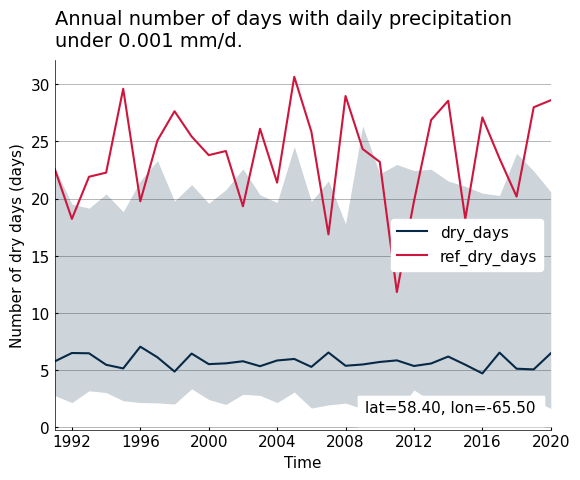

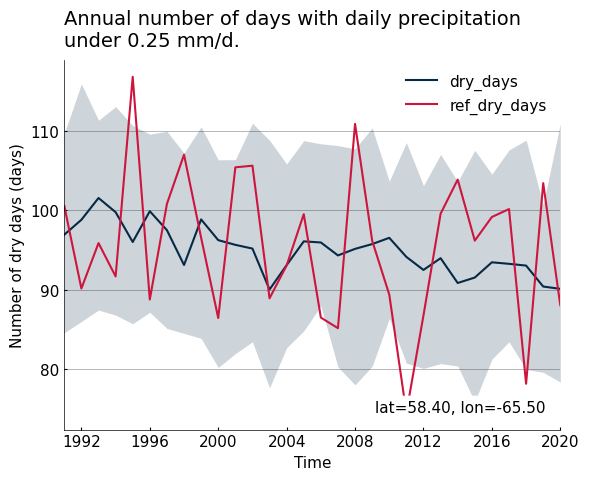

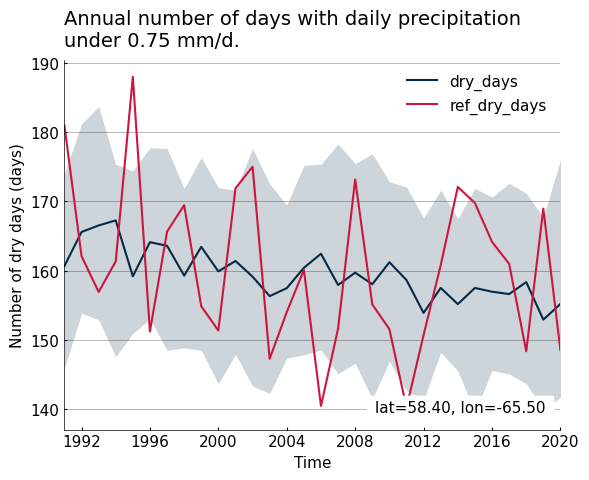

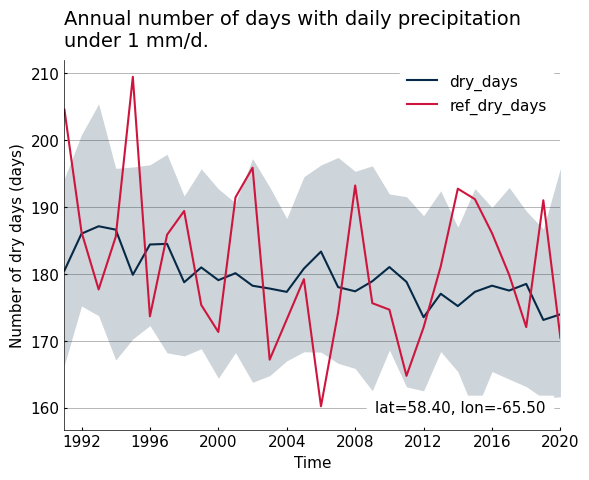

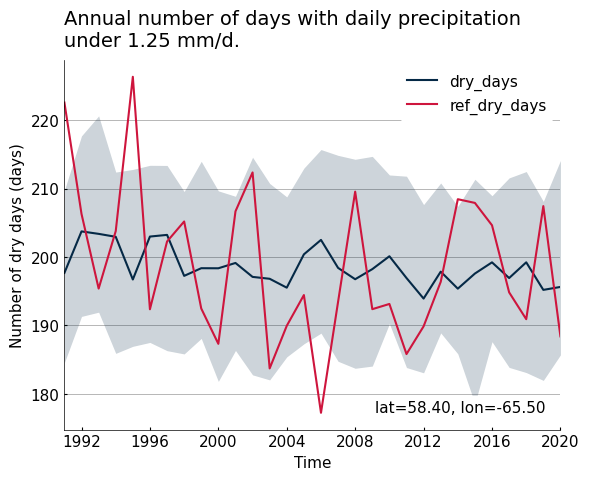

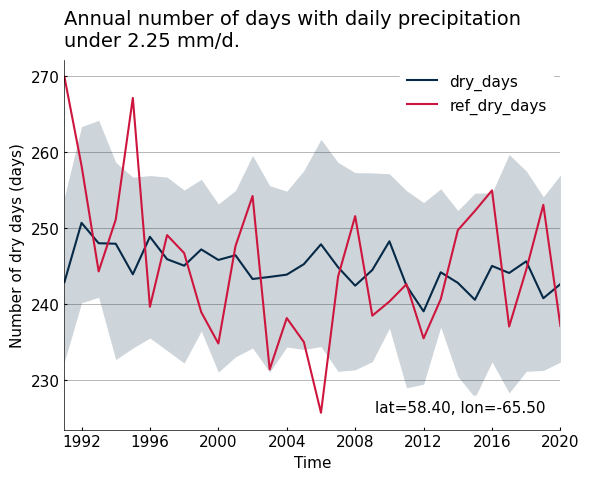

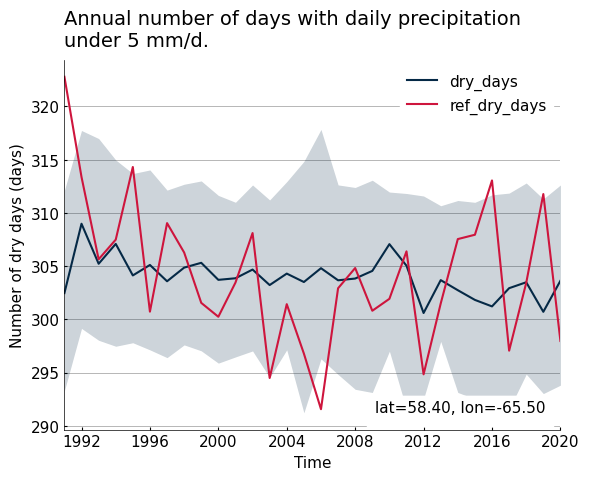

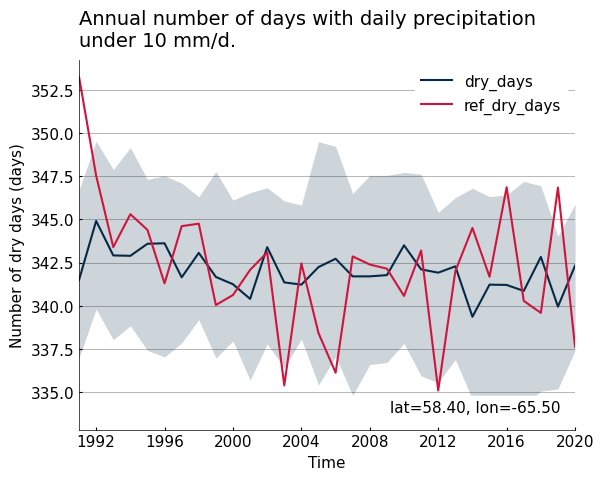

In [38]:
for thresh in ['0.001 mm/d','0.25 mm/d','0.75 mm/d','1 mm/d','1.25 mm/d','2.25 mm/d','5 mm/d','10 mm/d']:

    d= cat.search(bias_adjust_project="ESPO", experiment='ssp370', variable='pr').to_dataset_dict()
    das=[]
    for sim_id, ds in d.items():
        ds=ds.sel(time=slice('1991','2020'))
        da=xc.atmos.dry_days(ds.pr, thresh=thresh).to_dataset(name='dry_days')
        da= xs.spatial_mean(da, method='xesmf', spatial_subset=True, kwargs=dict(skipna=True),
                            region=dict(name='b', method='bbox',lon_bnds= [ -67, -64 ],lat_bnds= [ 56.35, 60.45 ]))
        da.attrs=ds.attrs
        das.append(da)
    weights = xs.generate_weights(das, independence_level='model')
    ens_stats = xs.ensemble_stats(
        datasets=das,
        statistics={
            "ensemble_percentiles": {"split": False}
        }, 
        weights=weights,
        common_attrs_only=True,
    )
    ax=fg.timeseries(ens_stats)
    
    # ref
    ds_ref=xr.open_zarr(f"{CONFIG['espo']}/reference/NAM_CaSR_fullregion.zarr.zip")
    ds_ref=ds_ref.sel(time=slice('1991','2020'))
    ds_ref=xc.atmos.dry_days(ds_ref.pr, thresh=thresh).to_dataset(name='dry_days')
    
    ds_ref= xs.spatial_mean(ds_ref, method='xesmf', spatial_subset=True,kwargs=dict(skipna=True),
                            region=dict(name='b', method='bbox',lon_bnds= [ -67, -64 ],lat_bnds= [ 56.35, 60.45 ]))
    fg.timeseries({'ref':ds_ref},ax=ax)

2026-10-16 12:24:39 INFO     xscen.spatial   Loading longitude for more efficient subsetting.


INFO:xscen.spatial:Loading longitude for more efficient subsetting.
/lustre06/project/6046550/julavoie/envs/espov2/lib/python3.12/site-packages/figanos/matplotlib/utils.py:287: UserWarning: Attribute "description" not found.


<GeoAxes: xlabel='longitude in rotated pole grid\n[degrees]', ylabel='latitude in rotated pole grid\n[degrees]'>

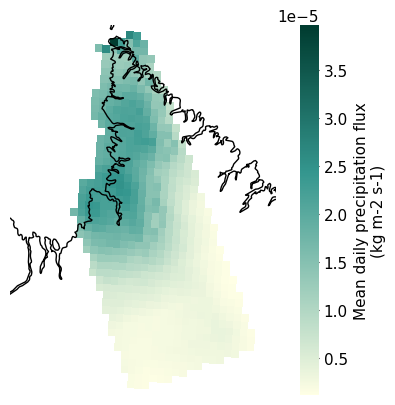

In [39]:
fg.gridmap(xs.spatial.subset(ds.pr.isel(time=0),name='b', method='bbox',lon_bnds= [ -67, -64 ],lat_bnds= [ 56.35, 60.45 ]), features=['coastline'])